In [165]:
!pip install contractions -q


[notice] A new release of pip is available: 26.1 -> 26.1.1
[notice] To update, run: pip install --upgrade pip


In [166]:
import pandas as pd
import re
from collections import Counter
import html
import re
import matplotlib.pyplot as plt
import numpy as np
import string

from contractions import fix as expand_contractions

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import skipgrams
import torch
from torch.utils.data import TensorDataset, DataLoader
from tensorflow.keras.utils import to_categorical
import torch.nn as nn
from torch.utils.data import Dataset

import torch.optim as optim
import datetime
import gc

import random
import time

from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns

import zipfile
import os
import io

from itertools import combinations
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE


from pandas.plotting import parallel_coordinates
import matplotlib.cm as cm
from matplotlib.lines import Line2D


In [167]:
dataset = pd.read_csv('news_dataset.csv')

#**EDA**

In [168]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 3 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   Class Index  120000 non-null  int64
 1   Title        120000 non-null  str  
 2   Description  120000 non-null  str  
dtypes: int64(1), str(2)
memory usage: 2.7 MB


In [169]:
dataset.head(10)

,Class Index,Title,Description
0,3,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli..."
1,3,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...
2,3,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...
3,3,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...
4,3,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco..."
5,3,"Stocks End Up, But Near Year Lows (Reuters)",Reuters - Stocks ended slightly higher on Frid...
6,3,Money Funds Fell in Latest Week (AP),AP - Assets of the nation's retail money marke...
7,3,Fed minutes show dissent over inflation (USATO...,USATODAY.com - Retail sales bounced back a bit...
8,3,Safety Net (Forbes.com),Forbes.com - After earning a PH.D. in Sociolog...
9,3,Wall St. Bears Claw Back Into the Black,"NEW YORK (Reuters) - Short-sellers, Wall Stre..."


In [170]:
for class_idx in sorted(dataset['Class Index'].unique()):
    print(f"\n{'='*60}")
    print(f"  CLASS INDEX: {class_idx}")
    print(f"{'='*60}")
    samples = dataset[dataset['Class Index'] == class_idx].head(5)
    for _, row in samples.iterrows():
        print(f"\n  Title      : {row['Title']}")
        print(f"  Description: {row['Description'][:150]}...")


  CLASS INDEX: 1

  Title      : Venezuelans Vote Early in Referendum on Chavez Rule (Reuters)
  Description: Reuters - Venezuelans turned out early\and in large numbers on Sunday to vote in a historic referendum\that will either remove left-wing President Hug...

  Title      : S.Koreans Clash with Police on Iraq Troop Dispatch (Reuters)
  Description: Reuters - South Korean police used water cannon in\central Seoul Sunday to disperse at least 7,000 protesters\urging the government to reverse a contr...

  Title      : Palestinians in Israeli Jails Start Hunger Strike (Reuters)
  Description: Reuters - Thousands of Palestinian\prisoners in Israeli jails began a hunger strike for better\conditions Sunday, but Israel's security minister said ...

  Title      : Seven Georgian soldiers wounded as South Ossetia ceasefire violated (AFP)
  Description: AFP - Sporadic gunfire and shelling took place overnight in the disputed Georgian region of South Ossetia in violation of a fragile ceasefi

In [171]:
# Based on sample inspection:
# 1 → World (international politics, conflicts, elections)
# 2 → Sports (Olympic games, NBA, baseball, football)
# 3 → Business (stock market, oil prices, finance)
# 4 → Sci/Tech (technology companies, software, electronics)

CLASS_NAMES = {1: 'World', 2: 'Sports', 3: 'Business', 4: 'Sci/Tech'}
dataset['category'] = dataset['Class Index'].map(CLASS_NAMES)

print(dataset['category'].value_counts())

category
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64


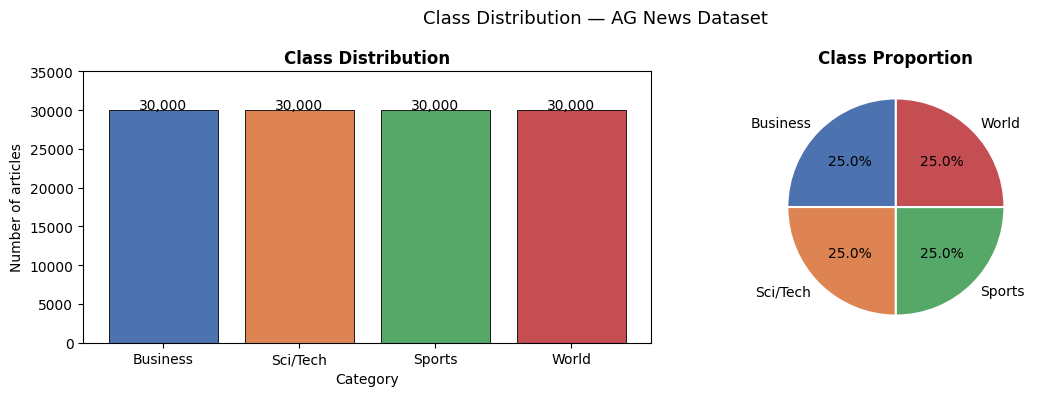

In [172]:
counts = dataset['category'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(counts.index, counts.values, color=['#4C72B0','#DD8452','#55A868','#C44E52'], edgecolor='black', linewidth=0.6)
axes[0].set_title('Class Distribution', fontweight='bold')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Number of articles')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 200, f'{v:,}', ha='center', fontsize=10)
axes[0].set_ylim(0, 35000)

axes[1].pie(counts.values, labels=counts.index,
            colors=['#4C72B0','#DD8452','#55A868','#C44E52'],
            autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[1].set_title('Class Proportion', fontweight='bold')

plt.suptitle('Class Distribution — AG News Dataset', fontsize=13)
plt.tight_layout()
plt.show()

In [173]:
for col in ['Title', 'Description']:
    print(f"\n=== Duplicate {col} per class ===")
    for class_idx, class_name in CLASS_NAMES.items():
        subset = dataset[dataset['Class Index'] == class_idx]
        dupes = subset[col].duplicated().sum()
        print(f"  {class_name:10s}: {dupes:,} duplicates ({dupes/len(subset)*100:.2f}%)")


=== Duplicate Title per class ===
  World     : 996 duplicates (3.32%)
  Sports    : 788 duplicates (2.63%)
  Business  : 1,431 duplicates (4.77%)
  Sci/Tech  : 1,837 duplicates (6.12%)

=== Duplicate Description per class ===
  World     : 222 duplicates (0.74%)
  Sports    : 163 duplicates (0.54%)
  Business  : 354 duplicates (1.18%)
  Sci/Tech  : 440 duplicates (1.47%)


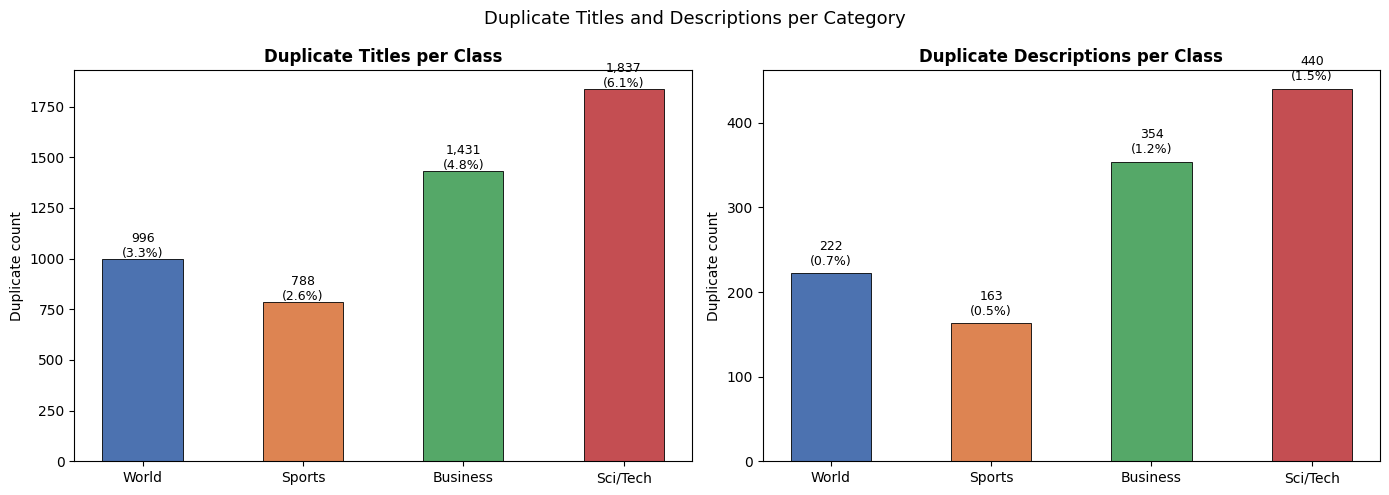

In [174]:
categories = list(CLASS_NAMES.values())
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

title_dupes = [dataset[dataset['Class Index'] == i]['Title'].duplicated().sum() for i in range(1,5)]
desc_dupes  = [dataset[dataset['Class Index'] == i]['Description'].duplicated().sum() for i in range(1,5)]

x = np.arange(len(categories))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, data, label in zip(axes, [title_dupes, desc_dupes], ['Title', 'Description']):
    bars = ax.bar(x, data, width=0.5, color=colors, edgecolor='black', linewidth=0.6)
    ax.set_title(f'Duplicate {label}s per Class', fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(categories)
    ax.set_ylabel('Duplicate count')
    for bar, val in zip(bars, data):
        pct = val / 30000 * 100
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                f'{val:,}\n({pct:.1f}%)', ha='center', fontsize=9)

plt.suptitle('Duplicate Titles and Descriptions per Category', fontsize=13)
plt.tight_layout()
plt.show()

In [175]:
for col in ['Title', 'Description']:
    print(f"\n{'='*60}")
    print(f"  DUPLICATE {col.upper()} EXAMPLES")
    print(f"{'='*60}")
    for class_idx, class_name in CLASS_NAMES.items():
        subset = dataset[dataset['Class Index'] == class_idx]
        dupes = subset[col][subset[col].duplicated(keep=False)]
        examples = dupes.drop_duplicates().head(5)
        print(f"\n  --- {class_name} ---")
        for i, val in enumerate(examples, 1):
            print(f"  {i}. {val[:100]}")


  DUPLICATE TITLE EXAMPLES

  --- World ---
  1. Phelps, Thorpe Advance in 200 Freestyle
  2. Venezuela Voters Turn Out in Huge Numbers
  3. F.B.I. Goes Knocking for Political Troublemakers
  4. Suspicious Powder Found at U.S. Embassy in Malaysia
  5. Israel Turns Up Heat on Palestinian Hunger Strike

  --- Sports ---
  1. Notables
  2. Singh Wins Playoff to Seize Third Major Title
  3. Today's schedule
  4. Greek Athletes Shocked by Accusations
  5. Medical Examiner Finds No Injuries on Thanou-Source

  --- Business ---
  1. Oil and Economy Cloud Stocks' Outlook (Reuters)
  2. Money Funds Fell in Latest Week (AP)
  3. Oil and Economy Cloud Stocks' Outlook
  4. Letters
  5. Caterpillar Union Rejects Contract Offer

  --- Sci/Tech ---
  1. Sony zooms in with new TV tech
  2. Search Engine Forums Spotlight
  3. Survival of software's fittest
  4. Sybase upgrades PowerBuilder, plots RFID move
  5. CA buys PestPatrol antispyware developer

  DUPLICATE DESCRIPTION EXAMPLES

  --- World ---

In [176]:
for class_idx, class_name in CLASS_NAMES.items():
    subset = dataset[dataset['Class Index'] == class_idx]

    both_same = subset.duplicated(subset=['Title', 'Description'], keep=False).sum()

    dup_titles = subset[subset['Title'].duplicated(keep=False)]
    only_title = dup_titles.groupby('Title').filter(lambda x: x['Description'].nunique() > 1).shape[0]

    dup_descs = subset[subset['Description'].duplicated(keep=False)]
    only_desc = dup_descs.groupby('Description').filter(lambda x: x['Title'].nunique() > 1).shape[0]

    print(f"\n{'='*50}")
    print(f"  {class_name}")
    print(f"{'='*50}")
    print(f"  Same title AND description : {both_same:,}")
    print(f"  Same title, diff. desc     : {only_title:,}")
    print(f"  Same desc,  diff. title    : {only_desc:,}")


  World
  Same title AND description : 0
  Same title, diff. desc     : 1,874
  Same desc,  diff. title    : 432

  Sports
  Same title AND description : 0
  Same title, diff. desc     : 1,299
  Same desc,  diff. title    : 319

  Business
  Same title AND description : 0
  Same title, diff. desc     : 2,663
  Same desc,  diff. title    : 691

  Sci/Tech
  Same title AND description : 0
  Same title, diff. desc     : 3,414
  Same desc,  diff. title    : 803


In [177]:
for col in ['Title', 'Description']:
    cross = dataset[dataset.duplicated(subset=[col], keep=False)]
    cross_diff_class = cross.groupby(col).filter(lambda x: x['Class Index'].nunique() > 1)

    print(f"\n=== {col} repeated across different classes ===")
    print(f"  Total cases : {len(cross_diff_class):,}")
    print(f"  Unique texts: {cross_diff_class[col].nunique():,}")

    print(f"\n  Distribution by class pair:")
    pairs = Counter()
    for _, group in cross_diff_class.groupby(col):
        classes = sorted(group['Class Index'].unique())
        for i in range(len(classes)):
            for j in range(i+1, len(classes)):
                pairs[(CLASS_NAMES[classes[i]], CLASS_NAMES[classes[j]])] += 1
    for (c1, c2), count in pairs.most_common():
        print(f"    {c1:10s} ↔ {c2:10s} : {count:,}")

# Title AND Description repeated across different classes
print(f"\n=== Title AND Description repeated across different classes ===")
cross_both = dataset[dataset.duplicated(subset=['Title', 'Description'], keep=False)]
cross_both_diff = cross_both.groupby(['Title', 'Description']).filter(lambda x: x['Class Index'].nunique() > 1)
print(f"  Total cases : {len(cross_both_diff):,}")
print(f"  Unique pairs: {cross_both_diff.groupby(['Title','Description']).ngroups:,}")

if len(cross_both_diff) > 0:
    print(f"\n  Distribution by class pair:")
    pairs = Counter()
    for _, group in cross_both_diff.groupby(['Title', 'Description']):
        classes = sorted(group['Class Index'].unique())
        for i in range(len(classes)):
            for j in range(i+1, len(classes)):
                pairs[(CLASS_NAMES[classes[i]], CLASS_NAMES[classes[j]])] += 1
    for (c1, c2), count in pairs.most_common():
        print(f"    {c1:10s} ↔ {c2:10s} : {count:,}")


=== Title repeated across different classes ===
  Total cases : 1,363
  Unique texts: 594

  Distribution by class pair:
    Business   ↔ Sci/Tech   : 377
    World      ↔ Business   : 98
    World      ↔ Sci/Tech   : 72
    World      ↔ Sports     : 41
    Sports     ↔ Business   : 8
    Sports     ↔ Sci/Tech   : 6

=== Description repeated across different classes ===
  Total cases : 243
  Unique texts: 98

  Distribution by class pair:
    Business   ↔ Sci/Tech   : 47
    World      ↔ Sci/Tech   : 23
    World      ↔ Business   : 21
    World      ↔ Sports     : 7

=== Title AND Description repeated across different classes ===
  Total cases : 0
  Unique pairs: 0


In [178]:
for class_idx, class_name in CLASS_NAMES.items():
    subset = dataset[dataset['Class Index'] == class_idx]
    words = []
    for text in subset['Title'] + ' ' + subset['Description']:
        tokens = re.findall(r'\b[a-zA-Z]+\b', text.lower())
        words.extend(tokens)

    top3 = Counter(words).most_common(3)
    print(f"\n{class_name}")
    for i, (word, count) in enumerate(top3, 1):
        print(f"  {i}. '{word}' — {count:,}")


World
  1. 'the' — 49,038
  2. 'in' — 32,216
  3. 'to' — 31,138

Sports
  1. 'the' — 63,383
  2. 'to' — 27,672
  3. 'a' — 26,115

Business
  1. 'the' — 44,820
  2. 'to' — 30,221
  3. 'a' — 29,097

Sci/Tech
  1. 'the' — 48,227
  2. 'to' — 31,703
  3. 'a' — 27,310


In [179]:
STOPWORDS = {
    'the','a','an','of','in','to','and','for','is','on','at','it',
    'its','with','by','as','be','was','are','that','this','from',
    'have','has','he','she','they','we','or','but','not','will',
    'had','been','were','his','her','their','our','which','who',
    'said','would','also','after','new','more','than','about','up',
    'out','if','one','two','three','four','five','six','seven','all'
}

for class_idx, class_name in CLASS_NAMES.items():
    subset = dataset[dataset['Class Index'] == class_idx]
    words = []
    for text in subset['Title'] + ' ' + subset['Description']:
        tokens = re.findall(r'\b[a-zA-Z]+\b', text.lower())
        words.extend([w for w in tokens if w not in STOPWORDS and len(w) > 2])

    top3 = Counter(words).most_common(3)
    print(f"\n{class_name}")
    for i, (word, count) in enumerate(top3, 1):
        print(f"  {i}. '{word}' — {count:,}")


World
  1. 'iraq' — 5,837
  2. 'reuters' — 5,423
  3. 'president' — 4,306

Sports
  1. 'game' — 4,281
  2. 'first' — 4,246
  3. 'over' — 4,159

Business
  1. 'reuters' — 8,717
  2. 'oil' — 6,386
  3. 'stocks' — 4,518

Sci/Tech
  1. 'microsoft' — 5,145
  2. 'software' — 3,673
  3. 'reuters' — 3,519


In [180]:
STOPWORDS.update(['reuters', 'ap', 'afp', 'said', 'says', 'new', 'first', 'over'])

for class_idx, class_name in CLASS_NAMES.items():
    subset = dataset[dataset['Class Index'] == class_idx]
    words = []
    for text in subset['Title'] + ' ' + subset['Description']:
        tokens = re.findall(r'\b[a-zA-Z]+\b', text.lower())
        words.extend([w for w in tokens if w not in STOPWORDS and len(w) > 2])

    top3 = Counter(words).most_common(3)
    print(f"\n{class_name}")
    for i, (word, count) in enumerate(top3, 1):
        print(f"  {i}. '{word}' — {count:,}")


World
  1. 'iraq' — 5,837
  2. 'president' — 4,306
  3. 'minister' — 3,351

Sports
  1. 'game' — 4,281
  2. 'season' — 3,647
  3. 'team' — 3,492

Business
  1. 'oil' — 6,386
  2. 'stocks' — 4,518
  3. 'inc' — 4,425

Sci/Tech
  1. 'microsoft' — 5,145
  2. 'software' — 3,673
  3. 'internet' — 3,387


In [181]:
STOPWORDS.update(['quot', 'fullquote', 'com'])

In [182]:
for class_idx, class_name in CLASS_NAMES.items():
    subset = dataset[dataset['Class Index'] == class_idx]
    words = []
    for text in subset['Title'] + ' ' + subset['Description']:
        tokens = re.findall(r'\b[a-zA-Z]+\b', text.lower())
        words.extend([w for w in tokens if w not in STOPWORDS and len(w) > 2])

    top3 = Counter(words).most_common(3)
    print(f"\n{class_name}")
    for i, (word, count) in enumerate(top3, 1):
        print(f"  {i}. '{word}' — {count:,}")


World
  1. 'iraq' — 5,837
  2. 'president' — 4,306
  3. 'minister' — 3,351

Sports
  1. 'game' — 4,281
  2. 'season' — 3,647
  3. 'team' — 3,492

Business
  1. 'oil' — 6,386
  2. 'stocks' — 4,518
  3. 'inc' — 4,425

Sci/Tech
  1. 'microsoft' — 5,145
  2. 'software' — 3,673
  3. 'internet' — 3,387


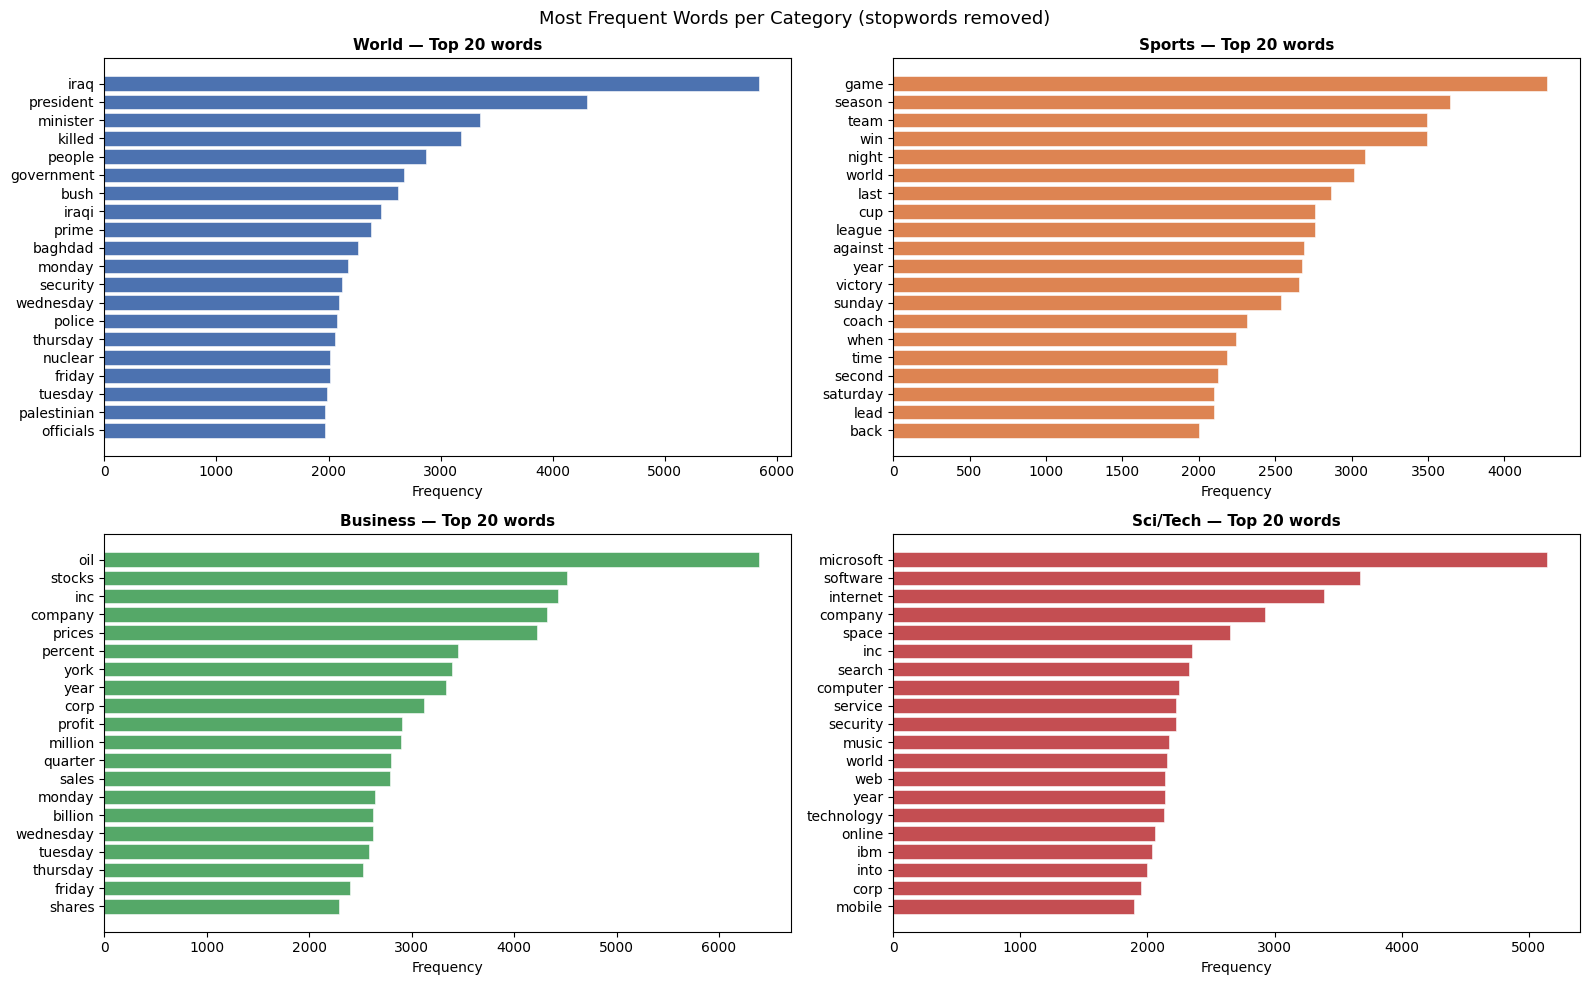

In [183]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
COLORS_MAP = {1: '#4C72B0', 2: '#DD8452', 3: '#55A868', 4: '#C44E52'}

for ax, (class_idx, class_name) in zip(axes.flat, CLASS_NAMES.items()):
    subset = dataset[dataset['Class Index'] == class_idx]
    words = []
    for text in subset['Title'] + ' ' + subset['Description']:
        tokens = re.findall(r'\b[a-zA-Z]+\b', text.lower())
        words.extend([w for w in tokens if w not in STOPWORDS and len(w) > 2])

    top20 = Counter(words).most_common(20)
    words_list, freqs = zip(*top20)

    ax.barh(list(reversed(words_list)), list(reversed(freqs)),
            color=COLORS_MAP[class_idx], edgecolor='white', linewidth=0.4)
    ax.set_title(f'{class_name} — Top 20 words', fontweight='bold', fontsize=11)
    ax.set_xlabel('Frequency')

plt.suptitle('Most Frequent Words per Category (stopwords removed)', fontsize=13)
plt.tight_layout()
plt.show()

In [184]:
for class_idx, class_name in CLASS_NAMES.items():
    subset = dataset[dataset['Class Index'] == class_idx]
    words = []
    for text in subset['Title'] + ' ' + subset['Description']:
        tokens = re.findall(r'\b[a-zA-Z]+\b', text.lower())
        words.extend([w for w in tokens if w not in STOPWORDS and len(w) > 2])

    bottom20 = Counter(words).most_common()[:-21:-1]
    print(f"\n{class_name} — Bottom 20 words")
    for i, (word, count) in enumerate(bottom20, 1):
        print(f"  {i:2}. '{word}' — {count:,}")


World — Bottom 20 words
   1. 'dodge' — 1
   2. 'interrogating' — 1
   3. 'quizzing' — 1
   4. 'ubiquitous' — 1
   5. 'blacked' — 1
   6. 'fryer' — 1
   7. 'kidsgrove' — 1
   8. 'indoctrinated' — 1
   9. 'vesicles' — 1
  10. 'synthetic' — 1
  11. 'vij' — 1
  12. 'chandra' — 1
  13. 'nirmal' — 1
  14. 'decomposing' — 1
  15. 'turkeyreached' — 1
  16. 'mashrafe' — 1
  17. 'nongovernmental' — 1
  18. 'blustery' — 1
  19. 'stubenhofer' — 1
  20. 'capt' — 1

Sports — Bottom 20 words
   1. 'xxxv' — 1
   2. 'sehorn' — 1
   3. 'flourishing' — 1
   4. 'advocates' — 1
   5. 'jurisdictions' — 1
   6. 'burdened' — 1
   7. 'attain' — 1
   8. 'elevates' — 1
   9. 'upgrading' — 1
  10. 'jazzy' — 1
  11. 'garciaparras' — 1
  12. 'stealth' — 1
  13. 'bangla' — 1
  14. 'mountainous' — 1
  15. 'homefield' — 1
  16. 'gird' — 1
  17. 'domino' — 1
  18. 'prong' — 1
  19. 'kia' — 1
  20. 'snowbird' — 1

Business — Bottom 20 words
   1. 'mantras' — 1
   2. 'austere' — 1
   3. 'fuss' — 1
   4. 'inhabited' — 1

In [185]:
print("=== Words appearing only once — per class vs entire dataset ===\n")

# Global counter across all classes
all_words = []
for text in dataset['Title'] + ' ' + dataset['Description']:
    tokens = re.findall(r'\b[a-zA-Z]+\b', text.lower())
    all_words.extend([w for w in tokens if w not in STOPWORDS and len(w) > 2])
global_counter = Counter(all_words)
global_single = sum(1 for w, c in global_counter.items() if c == 1)
print(f"  {'TOTAL':10s}: {global_single:,} / {len(global_counter):,} unique words ({global_single/len(global_counter)*100:.1f}%)")
print()

for class_idx, class_name in CLASS_NAMES.items():
    subset = dataset[dataset['Class Index'] == class_idx]
    words = []
    for text in subset['Title'] + ' ' + subset['Description']:
        tokens = re.findall(r'\b[a-zA-Z]+\b', text.lower())
        words.extend([w for w in tokens if w not in STOPWORDS and len(w) > 2])

    counter = Counter(words)
    # Appears once in this class
    single_in_class = {w for w, c in counter.items() if c == 1}
    # Of those, also appears only once globally
    single_globally  = sum(1 for w in single_in_class if global_counter[w] == 1)
    # Appears once in class but more in other classes
    rescued = len(single_in_class) - single_globally

    print(f"  {class_name:10s}: {len(single_in_class):,} appear once in class")
    print(f"             {single_globally:,} also appear once globally  → poor embedding")
    print(f"             {rescued:,} appear more in other classes → rescued by global vocab")
    print()

=== Words appearing only once — per class vs entire dataset ===

  TOTAL     : 19,413 / 61,174 unique words (31.7%)

  World     : 9,800 appear once in class
             4,673 also appear once globally  → poor embedding
             5,127 appear more in other classes → rescued by global vocab

  Sports    : 10,087 appear once in class
             5,409 also appear once globally  → poor embedding
             4,678 appear more in other classes → rescued by global vocab

  Business  : 8,767 appear once in class
             3,464 also appear once globally  → poor embedding
             5,303 appear more in other classes → rescued by global vocab

  Sci/Tech  : 10,792 appear once in class
             5,867 also appear once globally  → poor embedding
             4,925 appear more in other classes → rescued by global vocab



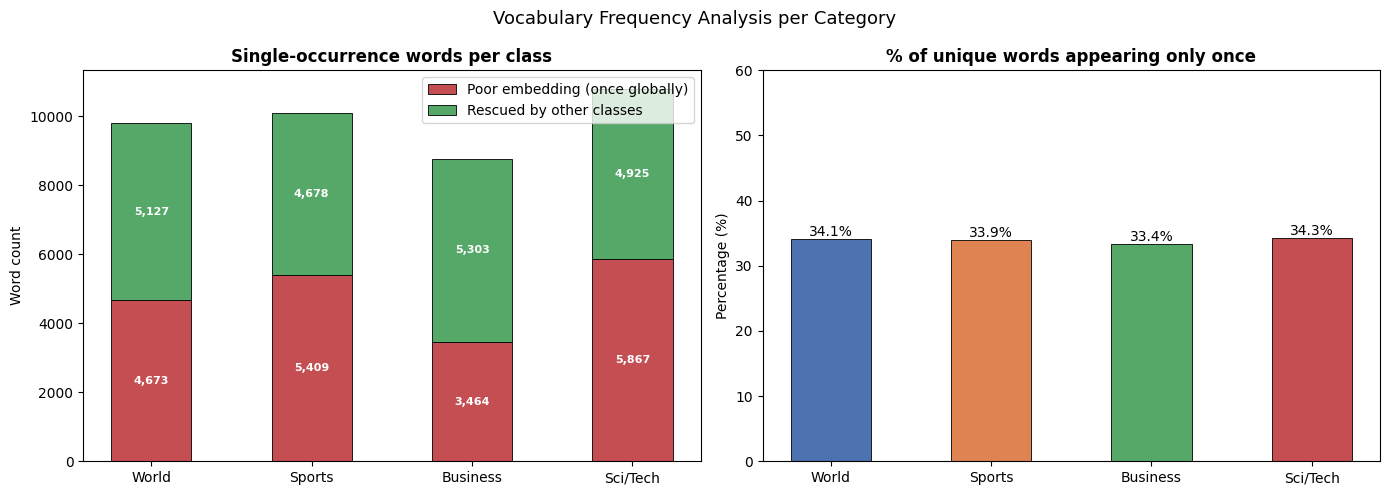

In [186]:
categories = list(CLASS_NAMES.values())
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

single_in_class_counts = []
single_globally_counts = []
rescued_counts = []

for class_idx in range(1, 5):
    subset = dataset[dataset['Class Index'] == class_idx]
    words = []
    for text in subset['Title'] + ' ' + subset['Description']:
        tokens = re.findall(r'\b[a-zA-Z]+\b', text.lower())
        words.extend([w for w in tokens if w not in STOPWORDS and len(w) > 2])

    counter = Counter(words)
    single_in_class = {w for w, c in counter.items() if c == 1}
    single_globally = sum(1 for w in single_in_class if global_counter[w] == 1)
    rescued = len(single_in_class) - single_globally

    single_in_class_counts.append(len(single_in_class))
    single_globally_counts.append(single_globally)
    rescued_counts.append(rescued)

x = np.arange(len(categories))
width = 0.3

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Stacked bar: globally rare vs rescued ───────────────────────────────────
axes[0].bar(x, single_globally_counts, width=0.5, label='Poor embedding (once globally)',
            color='#C44E52', edgecolor='black', linewidth=0.6)
axes[0].bar(x, rescued_counts, width=0.5, bottom=single_globally_counts,
            label='Rescued by other classes', color='#55A868', edgecolor='black', linewidth=0.6)
axes[0].set_xticks(x)
axes[0].set_xticklabels(categories)
axes[0].set_title('Single-occurrence words per class', fontweight='bold')
axes[0].set_ylabel('Word count')
axes[0].legend()
for i, (sg, rc) in enumerate(zip(single_globally_counts, rescued_counts)):
    axes[0].text(i, sg/2, f'{sg:,}', ha='center', va='center', fontsize=8, color='white', fontweight='bold')
    axes[0].text(i, sg + rc/2, f'{rc:,}', ha='center', va='center', fontsize=8, color='white', fontweight='bold')

# ── % of unique vocabulary that appears only once ───────────────────────────
all_unique = []
for class_idx in range(1, 5):
    subset = dataset[dataset['Class Index'] == class_idx]
    words = []
    for text in subset['Title'] + ' ' + subset['Description']:
        tokens = re.findall(r'\b[a-zA-Z]+\b', text.lower())
        words.extend([w for w in tokens if w not in STOPWORDS and len(w) > 2])
    all_unique.append(len(Counter(words)))

pcts = [s/u*100 for s, u in zip(single_in_class_counts, all_unique)]
bars = axes[1].bar(x, pcts, width=0.5, color=colors, edgecolor='black', linewidth=0.6)
axes[1].set_xticks(x)
axes[1].set_xticklabels(categories)
axes[1].set_title('% of unique words appearing only once', fontweight='bold')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_ylim(0, 60)
for bar, pct in zip(bars, pcts):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{pct:.1f}%', ha='center', fontsize=10)

plt.suptitle('Vocabulary Frequency Analysis per Category', fontsize=13)
plt.tight_layout()
plt.show()

In [187]:
dataset['title_len']   = dataset['Title'].str.len()
dataset['desc_len']    = dataset['Description'].str.len()
dataset['title_words'] = dataset['Title'].str.split().str.len()
dataset['desc_words']  = dataset['Description'].str.split().str.len()

print("=== Title length (chars) ===")
print(dataset['title_len'].describe().round(1).to_string())
print("\n=== Description length (chars) ===")
print(dataset['desc_len'].describe().round(1).to_string())
print("\n=== Title length (words) ===")
print(dataset['title_words'].describe().round(1).to_string())
print("\n=== Description length (words) ===")
print(dataset['desc_words'].describe().round(1).to_string())

=== Title length (chars) ===
count    120000.0
mean         42.1
std          13.6
min           6.0
25%          33.0
50%          41.0
75%          49.0
max         115.0

=== Description length (chars) ===
count    120000.0
mean        193.4
std          64.5
min           6.0
25%         155.0
50%         188.0
75%         219.0
max         985.0

=== Title length (words) ===
count    120000.0
mean          6.8
std           2.1
min           1.0
25%           5.0
50%           7.0
75%           8.0
max          19.0

=== Description length (words) ===
count    120000.0
mean         31.1
std           9.8
min           1.0
25%          25.0
50%          30.0
75%          36.0
max         173.0


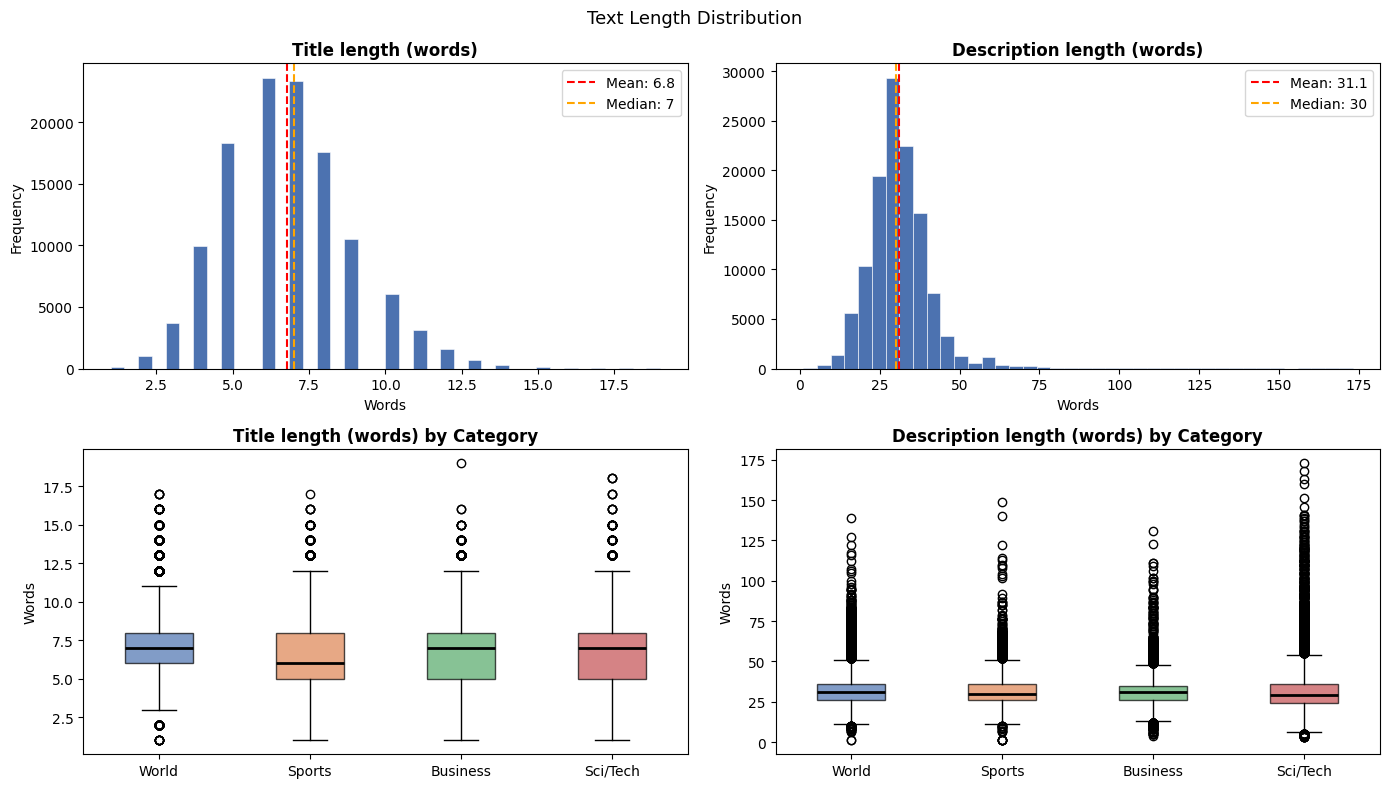

In [188]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# ── Histograms global ────────────────────────────────────────────────────────
for ax, col, label in zip(
    axes[0],
    ['title_words', 'desc_words'],
    ['Title length (words)', 'Description length (words)']
):
    ax.hist(dataset[col], bins=40, color='#4C72B0', edgecolor='white', linewidth=0.4)
    ax.axvline(dataset[col].mean(), color='red', linestyle='--',
               label=f'Mean: {dataset[col].mean():.1f}')
    ax.axvline(dataset[col].median(), color='orange', linestyle='--',
               label=f'Median: {dataset[col].median():.0f}')
    ax.set_title(label, fontweight='bold')
    ax.set_xlabel('Words')
    ax.set_ylabel('Frequency')
    ax.legend()

# ── Boxplot by class ─────────────────────────────────────────────────────────
for ax, col, label in zip(
    axes[1],
    ['title_words', 'desc_words'],
    ['Title length (words) by Category', 'Description length (words) by Category']
):
    data = [dataset[dataset['Class Index'] == i][col].values for i in range(1, 5)]
    bp = ax.boxplot(data, patch_artist=True,
                    medianprops={'color': 'black', 'linewidth': 2})
    for patch, color in zip(bp['boxes'], ['#4C72B0','#DD8452','#55A868','#C44E52']):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    ax.set_xticklabels(list(CLASS_NAMES.values()))
    ax.set_title(label, fontweight='bold')
    ax.set_ylabel('Words')

plt.suptitle('Text Length Distribution', fontsize=13)
plt.tight_layout()
plt.show()

In [189]:
# ── Vocabulary per class ─────────────────────────────────────────────────────
vocab_per_class = {}
for class_idx, class_name in CLASS_NAMES.items():
    subset = dataset[dataset['Class Index'] == class_idx]
    words = set()
    for text in subset['Title'] + ' ' + subset['Description']:
        tokens = re.findall(r'\b[a-zA-Z]+\b', text.lower())
        words.update([w for w in tokens if w not in STOPWORDS and len(w) > 2])
    vocab_per_class[class_name] = words

# ── Exclusive vs shared ──────────────────────────────────────────────────────
print("=== Vocabulary overlap analysis ===\n")
for class_name, vocab in vocab_per_class.items():
    others = set().union(*[v for k, v in vocab_per_class.items() if k != class_name])
    exclusive = vocab - others
    shared    = vocab & others
    print(f"  {class_name:10s}: {len(vocab):,} total | {len(exclusive):,} exclusive ({len(exclusive)/len(vocab)*100:.1f}%) | {len(shared):,} shared ({len(shared)/len(vocab)*100:.1f}%)")

# ── Pairwise overlap ─────────────────────────────────────────────────────────
print("\n=== Pairwise vocabulary overlap ===\n")
classes = list(vocab_per_class.keys())
for i in range(len(classes)):
    for j in range(i+1, len(classes)):
        a, b = classes[i], classes[j]
        overlap = vocab_per_class[a] & vocab_per_class[b]
        pct_a = len(overlap) / len(vocab_per_class[a]) * 100
        pct_b = len(overlap) / len(vocab_per_class[b]) * 100
        print(f"  {a:10s} ↔ {b:10s}: {len(overlap):,} words in common ({pct_a:.1f}% of {a}, {pct_b:.1f}% of {b})")

=== Vocabulary overlap analysis ===

  World     : 28,775 total | 7,647 exclusive (26.6%) | 21,128 shared (73.4%)
  Sports    : 29,734 total | 10,162 exclusive (34.2%) | 19,572 shared (65.8%)
  Business  : 26,270 total | 6,002 exclusive (22.8%) | 20,268 shared (77.2%)
  Sci/Tech  : 31,487 total | 9,747 exclusive (31.0%) | 21,740 shared (69.0%)

=== Pairwise vocabulary overlap ===

  World      ↔ Sports    : 15,530 words in common (54.0% of World, 52.2% of Sports)
  World      ↔ Business  : 15,306 words in common (53.2% of World, 58.3% of Business)
  World      ↔ Sci/Tech  : 16,333 words in common (56.8% of World, 51.9% of Sci/Tech)
  Sports     ↔ Business  : 14,094 words in common (47.4% of Sports, 53.7% of Business)
  Sports     ↔ Sci/Tech  : 15,071 words in common (50.7% of Sports, 47.9% of Sci/Tech)
  Business   ↔ Sci/Tech  : 16,622 words in common (63.3% of Business, 52.8% of Sci/Tech)


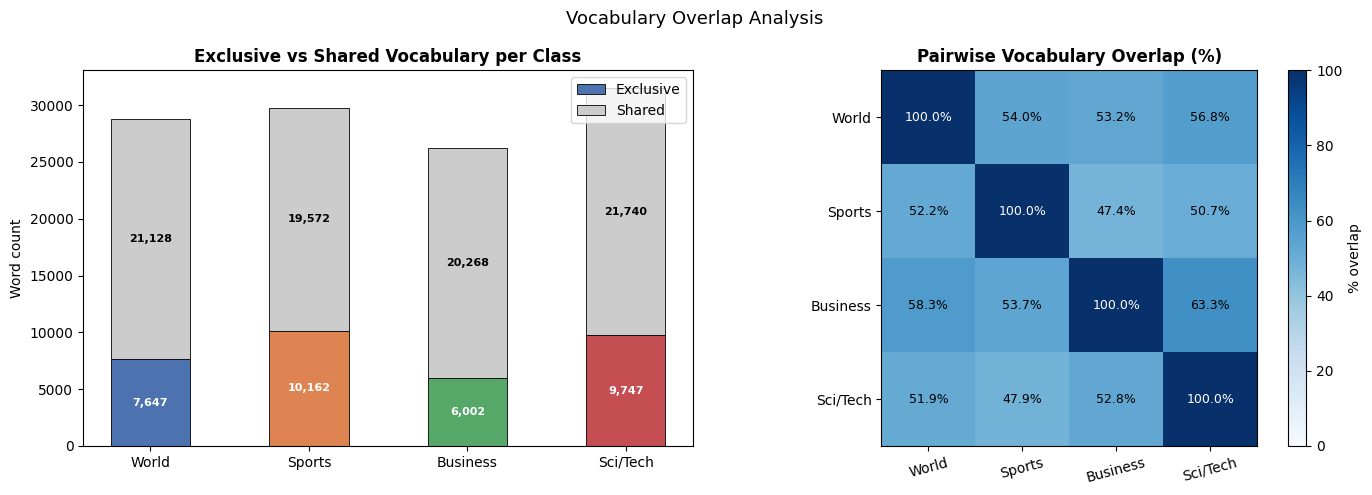

In [190]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Exclusive vs shared stacked bar ─────────────────────────────────────────
categories = list(CLASS_NAMES.values())
exclusive = [len(vocab_per_class[c] - set().union(*[v for k,v in vocab_per_class.items() if k != c])) for c in categories]
shared    = [len(vocab_per_class[c]) - e for c, e in zip(categories, exclusive)]

x = np.arange(len(categories))
axes[0].bar(x, exclusive, width=0.5, label='Exclusive', color=['#4C72B0','#DD8452','#55A868','#C44E52'], edgecolor='black', linewidth=0.6)
axes[0].bar(x, shared, width=0.5, bottom=exclusive, label='Shared', color='#cccccc', edgecolor='black', linewidth=0.6)
axes[0].set_xticks(x)
axes[0].set_xticklabels(categories)
axes[0].set_title('Exclusive vs Shared Vocabulary per Class', fontweight='bold')
axes[0].set_ylabel('Word count')
axes[0].legend()
for i, (e, s) in enumerate(zip(exclusive, shared)):
    axes[0].text(i, e/2, f'{e:,}', ha='center', va='center', fontsize=8, color='white', fontweight='bold')
    axes[0].text(i, e + s/2, f'{s:,}', ha='center', va='center', fontsize=8, color='black', fontweight='bold')

# ── Pairwise overlap heatmap ─────────────────────────────────────────────────
matrix = np.zeros((4, 4))
for i, c1 in enumerate(categories):
    for j, c2 in enumerate(categories):
        if i == j:
            matrix[i][j] = 100.0
        else:
            overlap = vocab_per_class[c1] & vocab_per_class[c2]
            matrix[i][j] = len(overlap) / len(vocab_per_class[c1]) * 100

im = axes[1].imshow(matrix, cmap='Blues', vmin=0, vmax=100)
axes[1].set_xticks(range(4))
axes[1].set_yticks(range(4))
axes[1].set_xticklabels(categories, rotation=15)
axes[1].set_yticklabels(categories)
axes[1].set_title('Pairwise Vocabulary Overlap (%)', fontweight='bold')
fig.colorbar(im, ax=axes[1], label='% overlap')
for i in range(4):
    for j in range(4):
        axes[1].text(j, i, f'{matrix[i][j]:.1f}%', ha='center', va='center',
                     fontsize=9, color='black' if matrix[i][j] < 70 else 'white')

plt.suptitle('Vocabulary Overlap Analysis', fontsize=13)
plt.tight_layout()
plt.show()

In [191]:
for class_idx, class_name in CLASS_NAMES.items():
    subset = dataset[dataset['Class Index'] == class_idx]
    words = []
    for text in subset['Title'] + ' ' + subset['Description']:
        tokens = re.findall(r'\b[a-zA-Z]+\b', text.lower())
        words.extend([w for w in tokens if w not in STOPWORDS and len(w) > 2])
    
    counter = Counter(words)
    others = set().union(*[v for k, v in vocab_per_class.items() if k != class_name])
    
    # Palabras que aparecen solo una vez en esta clase
    single_in_class = {w for w, c in counter.items() if c == 1}
    # Palabras exclusivas de esta clase
    exclusive = vocab_per_class[class_name] - others
    # Intersección
    overlap = single_in_class & exclusive
    
    print(f"\n{class_name}")
    print(f"  Únicas (freq=1) : {len(single_in_class):,}")
    print(f"  Exclusivas      : {len(exclusive):,}")
    print(f"  Intersección    : {len(overlap):,}  ({len(overlap)/len(single_in_class)*100:.1f}% de las únicas son también exclusivas)")


World
  Únicas (freq=1) : 9,800
  Exclusivas      : 7,647
  Intersección    : 4,673  (47.7% de las únicas son también exclusivas)

Sports
  Únicas (freq=1) : 10,087
  Exclusivas      : 10,162
  Intersección    : 5,409  (53.6% de las únicas son también exclusivas)

Business
  Únicas (freq=1) : 8,767
  Exclusivas      : 6,002
  Intersección    : 3,464  (39.5% de las únicas son también exclusivas)

Sci/Tech
  Únicas (freq=1) : 10,792
  Exclusivas      : 9,747
  Intersección    : 5,867  (54.4% de las únicas son también exclusivas)


In [192]:
print("=== Average word length per class ===\n")
for class_idx, class_name in CLASS_NAMES.items():
    subset = dataset[dataset['Class Index'] == class_idx]
    words = []
    for text in subset['Title'] + ' ' + subset['Description']:
        tokens = re.findall(r'\b[a-zA-Z]+\b', text.lower())
        words.extend([w for w in tokens if w not in STOPWORDS and len(w) > 2])

    avg_len = sum(len(w) for w in words) / len(words)
    print(f"  {class_name:10s}: {avg_len:.2f} chars/word")

=== Average word length per class ===

  World     : 6.40 chars/word
  Sports    : 5.98 chars/word
  Business  : 6.21 chars/word
  Sci/Tech  : 6.32 chars/word


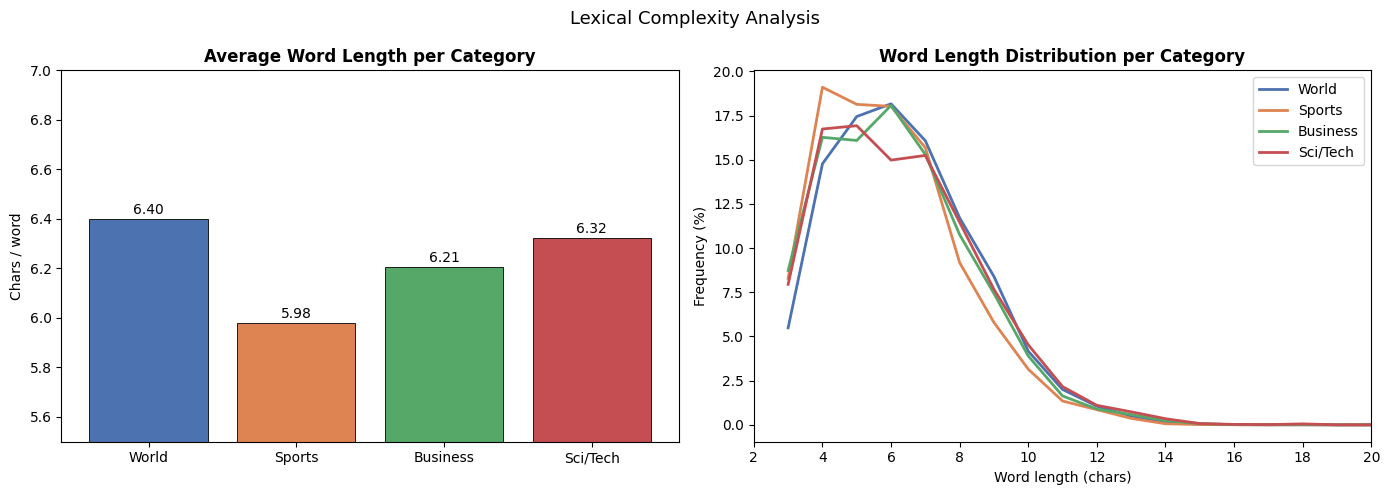

In [193]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Bar: average word length ─────────────────────────────────────────────────
avg_lengths = []
for class_idx, class_name in CLASS_NAMES.items():
    subset = dataset[dataset['Class Index'] == class_idx]
    words = []
    for text in subset['Title'] + ' ' + subset['Description']:
        tokens = re.findall(r'\b[a-zA-Z]+\b', text.lower())
        words.extend([w for w in tokens if w not in STOPWORDS and len(w) > 2])
    avg_lengths.append(sum(len(w) for w in words) / len(words))

bars = axes[0].bar(categories, avg_lengths, color=['#4C72B0','#DD8452','#55A868','#C44E52'],
                   edgecolor='black', linewidth=0.6)
axes[0].set_title('Average Word Length per Category', fontweight='bold')
axes[0].set_ylabel('Chars / word')
axes[0].set_ylim(5.5, 7)
for bar, val in zip(bars, avg_lengths):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f'{val:.2f}', ha='center', fontsize=10)

# ── Distribution of word lengths per class ───────────────────────────────────
for class_idx, class_name, color in zip(range(1,5), categories, ['#4C72B0','#DD8452','#55A868','#C44E52']):
    subset = dataset[dataset['Class Index'] == class_idx]
    words = []
    for text in subset['Title'] + ' ' + subset['Description']:
        tokens = re.findall(r'\b[a-zA-Z]+\b', text.lower())
        words.extend([w for w in tokens if w not in STOPWORDS and len(w) > 2])
    lengths = [len(w) for w in words]
    counter = Counter(lengths)
    total = sum(counter.values())
    x_vals = sorted(counter.keys())
    y_vals = [counter[x]/total*100 for x in x_vals]
    axes[1].plot(x_vals, y_vals, label=class_name, color=color, linewidth=2)

axes[1].set_title('Word Length Distribution per Category', fontweight='bold')
axes[1].set_xlabel('Word length (chars)')
axes[1].set_ylabel('Frequency (%)')
axes[1].set_xlim(2, 20)
axes[1].legend()

plt.suptitle('Lexical Complexity Analysis', fontsize=13)
plt.tight_layout()
plt.show()

#**CLEANING**

###**Special Characters**

In [194]:
dataset['text'] = dataset['Title'] + ' ' + dataset['Description']

char_counter = Counter()
for text in dataset['text']:
    for ch in text:
        if not ch.isalnum() and ch != ' ':
            char_counter[ch] += 1

print("SPECIAL CHARACTERS IN RAW CORPUS")
print("=" * 30)
print(f"  {'char':10s}  {'count':>10}")
print(f"  {'-'*10}  {'-'*10}")
for ch, cnt in char_counter.most_common():
    print(f"  {repr(ch):10s}  {cnt:>8,}")

SPECIAL CHARACTERS IN RAW CORPUS
  char             count
  ----------  ----------
  '.'          225,935
  ','          165,668
  '-'          139,159
  ';'           87,360
  '#'           47,307
  '('           41,089
  ')'           40,770
  "'"           32,235
  '\\'          26,977
  '&'           26,323
  ':'           21,517
  '/'           20,990
  '"'           13,035
  '$'           10,976
  '='            8,440
  '?'            5,723
  '!'              846
  '_'              198
  '*'              152


In [195]:
suspicious = ['#', '&', '\\', '/', '=', ';', '_', '$']

for ch in suspicious:
    print(f"\n=== {repr(ch)} ({char_counter[ch]:,} occurrences) ===")
    matches = []
    for text in dataset['text']:
        if ch in text:
            idx = text.index(ch)
            snippet = text[max(0, idx-30):idx+30]
            matches.append(snippet)
        if len(matches) == 8:
            break
    for m in matches:
        print(f"  ...{m}...")


=== '#' (47,307 occurrences) ===
  ...ar as oil prices surged past  #36;46\a barrel, offsetting a ...
  ... market mutual funds fell by  #36;1.17 billion in the latest...
  ... at an annual base salary of  #36;70,000. Soon after, a fina...
  ... has apparently struck again  #151; this time breaking the l...
  ... predict a storm's intensity  #151; even with all the latest...
  ...opical storm and a hurricane  #151; or possibly two hurrican...
  ... rocket ship race to claim a  #36;10 million Ansari X Prize ...
  ...ing a low-budget stab at the  #36;10 million Ansari X Prize ...

=== '&' (26,323 occurrences) ===
  ...e Enterprise that can't adapt &lt;strong&gt;Opinion&lt;/stro...
  ...Buffy the Censor Slayer &lt;strong&gt;Letters&lt;/stro...
  ...ance: the readers have spoken &lt;strong&gt;Poll results&lt;...
  ...&lt;em&gt;El Reg&lt;/em&gt; pl...
  ...E (Reuters) - Microsoft Corp. &lt;MSFT.O&gt; said it will  b...
  ...E (Reuters) - Microsoft Corp. &lt;MSFT.O&gt; released on  Tu...
  

Some characters in the raw text appear as coded sequences like &lt; or &amp; instead of their actual symbols < or &. This step converts them back to their readable form so subsequent cleaning steps can detect and remove them correctly.

In [196]:
dataset['text_clean'] = dataset['text'].apply(html.unescape)
print(dataset['text_clean'].head(3).to_string())

0    Wall St. Bears Claw Back Into the Black (Reute...
1    Carlyle Looks Toward Commercial Aerospace (Reu...
2    Oil and Economy Cloud Stocks' Outlook (Reuters...


Some dollar signs and dashes were stored as numeric codes like #36; or #151; because the & at the start got lost during scraping. This step removes those broken codes entirely.

In [197]:
dataset['text_clean'] = dataset['text_clean'].apply(
    lambda x: re.sub(r'#\d+;', '', x)
)
print(dataset['text_clean'].head(3).to_string())

0    Wall St. Bears Claw Back Into the Black (Reute...
1    Carlyle Looks Toward Commercial Aerospace (Reu...
2    Oil and Economy Cloud Stocks' Outlook (Reuters...


Similar to the previous step, but for text-based codes like quot;, hellip;, or nbsp; that represent quotes, ellipses, and spaces. These are scraping artifacts with no semantic value.

In [198]:
dataset['text_clean'] = dataset['text_clean'].apply(
    lambda x: re.sub(r'\b(quot|hellip|nbsp|amp|lt|gt|apos|rsquo|lsquo|ndash|mdash);', '', x)
)
print(dataset['text_clean'].head(3).to_string())

0    Wall St. Bears Claw Back Into the Black (Reute...
1    Carlyle Looks Toward Commercial Aerospace (Reu...
2    Oil and Economy Cloud Stocks' Outlook (Reuters...


After decoded the HTML, actual tags like <strong>, <FONT face="..."> or <br> became visible in the text. This step removes them since they are formatting markup, not content.

In [199]:
dataset['text_clean'] = dataset['text_clean'].apply(
    lambda x: re.sub(r'<[^>]+>', ' ', x)
)
print(dataset['text_clean'].head(3).to_string())

0    Wall St. Bears Claw Back Into the Black (Reute...
1    Carlyle Looks Toward Commercial Aerospace (Reu...
2    Oil and Economy Cloud Stocks' Outlook (Reuters...


The raw text contains backslashes used as escape characters, appearing as \n split across words like \band or \$55bn. This step replaces them with a space to restore the original word boundaries.

In [200]:
dataset['text_clean'] = dataset['text_clean'].apply(
    lambda x: re.sub(r'\\+', ' ', x)
)
print(dataset['text_clean'].head(3).to_string())

0    Wall St. Bears Claw Back Into the Black (Reute...
1    Carlyle Looks Toward Commercial Aerospace (Reu...
2    Oil and Economy Cloud Stocks' Outlook (Reuters...


News articles start with agency identifiers like (Reuters), (AP) or (AFP). These are metadata about the source, not part of the news content itself, and would pollute the vocabulary if kept.

In [201]:
dataset['text_clean'] = dataset['text_clean'].apply(
    lambda x: re.sub(r'\([A-Z][a-zA-Z\s\.]+\)', ' ', x)
)
print(dataset['text_clean'].head(3).to_string())

0    Wall St. Bears Claw Back Into the Black   Reut...
1    Carlyle Looks Toward Commercial Aerospace   Re...
2    Oil and Economy Cloud Stocks' Outlook   Reuter...


Some articles contain URLs leftover from HTML attributes. These strings have no semantic value for word embeddings and would generate meaningless tokens like ad, doubleclick, net.

In [202]:
dataset['text_clean'] = dataset['text_clean'].apply(
    lambda x: re.sub(r'https?://\S+', ' ', x)
)
print(dataset['text_clean'].head(3).to_string())

0    Wall St. Bears Claw Back Into the Black   Reut...
1    Carlyle Looks Toward Commercial Aerospace   Re...
2    Oil and Economy Cloud Stocks' Outlook   Reuter...


Converts all text to lowercase so that Reuters, reuters and REUTERS are treated as the same word. Without this, the vocabulary would contain duplicate entries for the same concept. (Camacho-Collados & Pilehvar, 2017)

In [203]:
dataset['text_clean'] = dataset['text_clean'].str.lower()
print(dataset['text_clean'].head(3).to_string())

0    wall st. bears claw back into the black   reut...
1    carlyle looks toward commercial aerospace   re...
2    oil and economy cloud stocks' outlook   reuter...


Expands contractions like don't → do not and it's → it is. This must happen before punctuation removal — if done after, don't becomes dont, which is not a real word and would enter the vocabulary as a meaningless token. (Jurafsky & Martin, 2024)

In [204]:
dataset['text_clean'] = dataset['text_clean'].apply(expand_contractions)
print(dataset['text_clean'].head(3).to_string())

0    wall st. bears claw back into the black   reut...
1    carlyle looks toward commercial aerospace   re...
2    oil and economy cloud stocks' outlook   reuter...


 Removes all punctuation and non-alphabetic characters. For Skip-Gram, only actual words carry semantic meaning. Symbols like ., ,, $, = do not contribute to learning word relationships. (Loper & Bird, 2002)

In [205]:
dataset['text_clean'] = dataset['text_clean'].apply(
    lambda x: x.translate(str.maketrans('', '', string.punctuation))
)
print(dataset['text_clean'].head(3).to_string())

0    wall st bears claw back into the black   reute...
1    carlyle looks toward commercial aerospace   re...
2    oil and economy cloud stocks outlook   reuters...


Multiple spaces left behind by previous removal steps are collapsed into a single space and leading/trailing whitespace is removed, producing clean token-ready text.

In [206]:
dataset['text_clean'] = dataset['text_clean'].apply(
    lambda x: re.sub(r'\s+', ' ', x).strip()
)
print(dataset['text_clean'].head(3).to_string())

0    wall st bears claw back into the black reuters...
1    carlyle looks toward commercial aerospace reut...
2    oil and economy cloud stocks outlook reuters s...


In [207]:
char_counter_clean = Counter()
for text in dataset['text_clean']:
    for ch in text:
        if not ch.isalnum() and ch != ' ':
            char_counter_clean[ch] += 1

if len(char_counter_clean) == 0:
    print("No special characters remaining — corpus is fully clean")
else:
    print("Remaining special characters:")
    print(f"  {'char':10s}  {'count':>10}")
    print(f"  {'-'*10}  {'-'*10}")
    for ch, cnt in char_counter_clean.most_common():
        print(f"  {repr(ch):10s}  {cnt:>10,}")

No special characters remaining — corpus is fully clean


In [208]:
print("CLEANING SUMMARY")
print("=" * 40)
print(f"  Total rows      : {len(dataset):,}")
print(f"  Null values     : {dataset['text_clean'].isnull().sum()}")
print(f"  Empty strings   : {(dataset['text_clean'].str.strip() == '').sum()}")
print(f"  Avg text length : {dataset['text_clean'].str.split().str.len().mean():.1f} words")
print()
print("Before → After sample:")
for i in range(3):
    print(f"\n  BEFORE: {dataset['text'].iloc[i][:80]}")
    print(f"  AFTER : {dataset['text_clean'].iloc[i][:80]}")

CLEANING SUMMARY
  Total rows      : 120,000
  Null values     : 0
  Empty strings   : 0
  Avg text length : 37.1 words

Before → After sample:

  BEFORE: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall 
  AFTER : wall st bears claw back into the black reuters shortsellers wall streets dwindli

  BEFORE: Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment
  AFTER : carlyle looks toward commercial aerospace reuters private investment firm carlyl

  BEFORE: Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices p
  AFTER : oil and economy cloud stocks outlook reuters soaring crude prices plus worries a


#**SECOND EDA**

In [209]:
word_counter = Counter()
for text in dataset['text_clean']:
    word_counter.update(text.split())

total_unique = len(word_counter)
total_tokens = sum(word_counter.values())

print(f"VOCABULARY OVERVIEW")
print(f"{'='*40}")
print(f"  Total unique words : {total_unique:,}")
print(f"  Total tokens       : {total_tokens:,}")
print(f"  Avg frequency      : {total_tokens/total_unique:.1f} tokens/word")
print()

# Frequency buckets
buckets = [1, 2, 3, 5, 10, 20, 50, 100]
print(f"  {'Frequency':>12}  {'Words':>10}  {'% of vocab':>12}")
print(f"  {'-'*12}  {'-'*10}  {'-'*12}")
for i in range(len(buckets)):
    lo = buckets[i]
    hi = buckets[i+1] if i+1 < len(buckets) else float('inf')
    count = sum(1 for w, c in word_counter.items() if lo <= c < hi)
    print(f"  {f'= {lo}' if hi == float('inf') else f'{lo} — {hi-1}':>12}  {count:>10,}  {count/total_unique*100:>11.1f}%")

VOCABULARY OVERVIEW
  Total unique words : 84,967
  Total tokens       : 4,450,371
  Avg frequency      : 52.4 tokens/word

     Frequency       Words    % of vocab
  ------------  ----------  ------------
         1 — 1      33,541         39.5%
         2 — 2      11,415         13.4%
         3 — 4      10,040         11.8%
         5 — 9       9,509         11.2%
       10 — 19       6,720          7.9%
       20 — 49       5,856          6.9%
       50 — 99       2,932          3.5%
         = 100       4,954          5.8%


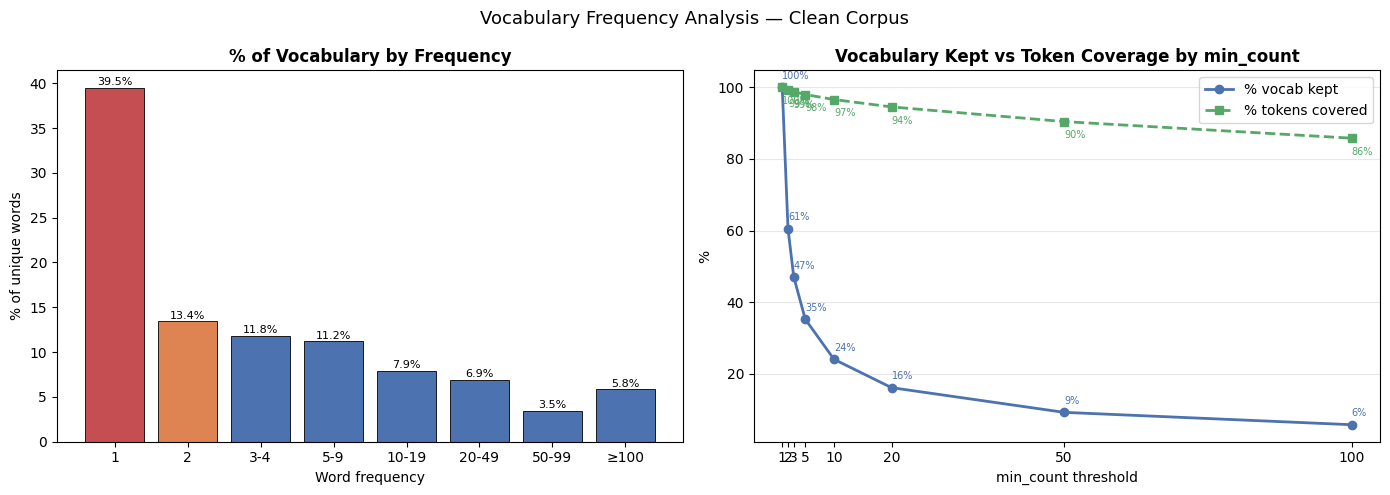

In [210]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Left: % of vocabulary per frequency bucket ───────────────────────────────
labels = ['1', '2', '3-4', '5-9', '10-19', '20-49', '50-99', '≥100']
values = [33541, 11415, 10040, 9509, 6720, 5856, 2932, 4954]
pcts   = [v/total_unique*100 for v in values]
colors = ['#C44E52' if i == 0 else '#DD8452' if i == 1 else '#4C72B0' for i in range(len(labels))]

bars = axes[0].bar(labels, pcts, color=colors, edgecolor='black', linewidth=0.6)
axes[0].set_title('% of Vocabulary by Frequency', fontweight='bold')
axes[0].set_xlabel('Word frequency')
axes[0].set_ylabel('% of unique words')
for bar, pct in zip(bars, pcts):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{pct:.1f}%', ha='center', fontsize=8)

# ── Right: cumulative vocabulary coverage ────────────────────────────────────
thresholds = [1, 2, 3, 5, 10, 20, 50, 100]
kept        = [sum(1 for c in word_counter.values() if c >= t) for t in thresholds]
kept_pct    = [k/total_unique*100 for k in kept]
token_cov   = [sum(c for c in word_counter.values() if c >= t)/total_tokens*100 for t in thresholds]

axes[1].plot(thresholds, kept_pct, 'o-', color='#4C72B0', label='% vocab kept', linewidth=2)
axes[1].plot(thresholds, token_cov, 's--', color='#55A868', label='% tokens covered', linewidth=2)
axes[1].set_title('Vocabulary Kept vs Token Coverage by min_count', fontweight='bold')
axes[1].set_xlabel('min_count threshold')
axes[1].set_ylabel('%')
axes[1].set_xticks(thresholds)
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

for t, kp, tc in zip(thresholds, kept_pct, token_cov):
    axes[1].annotate(f'{kp:.0f}%', (t, kp), textcoords='offset points', xytext=(0, 6), fontsize=7, color='#4C72B0')
    axes[1].annotate(f'{tc:.0f}%', (t, tc), textcoords='offset points', xytext=(0,-12), fontsize=7, color='#55A868')

plt.suptitle('Vocabulary Frequency Analysis — Clean Corpus', fontsize=13)
plt.tight_layout()
plt.show()

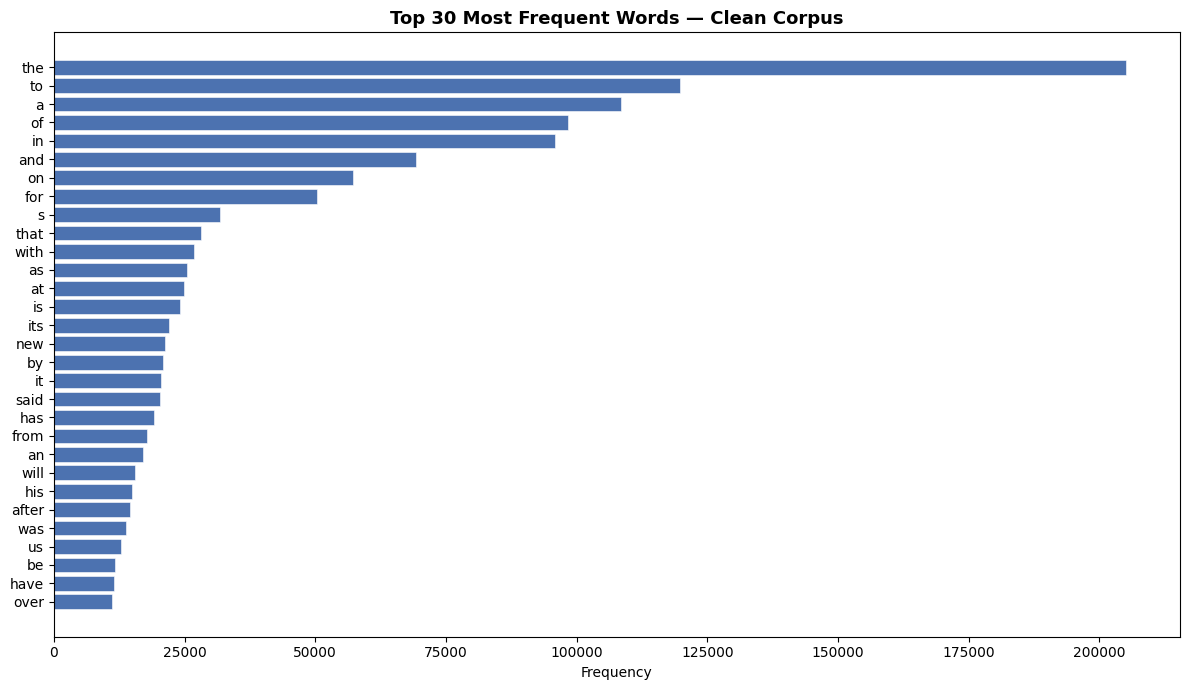

In [211]:
top30 = word_counter.most_common(30)
words_list, freqs = zip(*top30)

fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(list(reversed(words_list)), list(reversed(freqs)),
        color='#4C72B0', edgecolor='white', linewidth=0.4)
ax.set_title('Top 30 Most Frequent Words — Clean Corpus', fontweight='bold', fontsize=13)
ax.set_xlabel('Frequency')
plt.tight_layout()
plt.show()

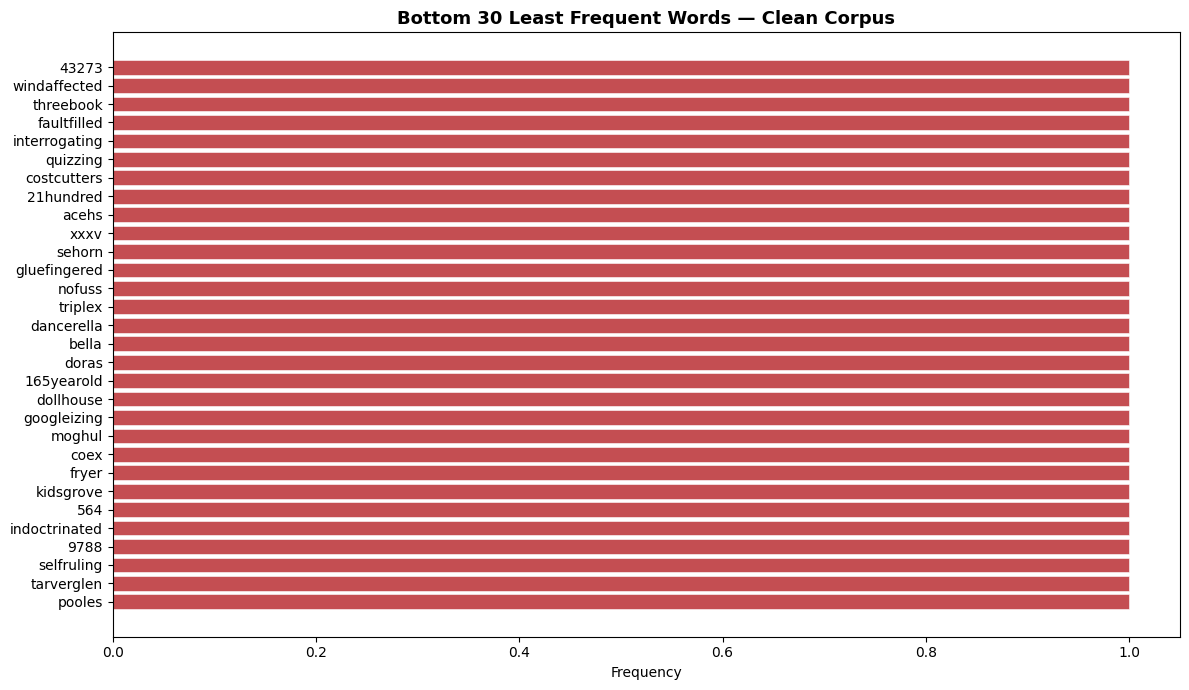

In [212]:
# ── Bottom 30 least frequent words in clean corpus ───────────────────────────
bottom30 = word_counter.most_common()[:-31:-1]
words_list_b, freqs_b = zip(*bottom30)

fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(list(reversed(words_list_b)), list(reversed(freqs_b)),
        color='#C44E52', edgecolor='white', linewidth=0.4)
ax.set_title('Bottom 30 Least Frequent Words — Clean Corpus', fontweight='bold', fontsize=13)
ax.set_xlabel('Frequency')
plt.tight_layout()
plt.show()

#**MORE CLEANING** NUMBERS STILL THERE

Remove numbers non sense:

In [213]:
dataset['text_clean'] = dataset['text_clean'].apply(
    lambda x: re.sub(r'\b\d+\b', '', x)
)

Remove single character words for example "s"

In [214]:
dataset['text_clean'] = dataset['text_clean'].apply(
    lambda x: ' '.join([w for w in x.split() if len(w) > 1])
)

dataset['text_clean'] = dataset['text_clean'].apply(
    lambda x: re.sub(r'\s+', ' ', x).strip()
)

print("Sample after additional cleaning:")
print(dataset['text_clean'].head(5).to_string())

Sample after additional cleaning:
0    wall st bears claw back into the black reuters...
1    carlyle looks toward commercial aerospace reut...
2    oil and economy cloud stocks outlook reuters s...
3    iraq halts oil exports from main southern pipe...
4    oil prices soar to alltime record posing new m...


In [215]:
# ── Vocabulary after additional cleaning ────────────────────────────────────
word_counter_v2 = Counter()
for text in dataset['text_clean']:
    word_counter_v2.update(text.split())

total_unique_v2 = len(word_counter_v2)
total_tokens_v2 = sum(word_counter_v2.values())

print(f"VOCABULARY COMPARISON")
print(f"{'='*45}")
print(f"  {'':25s}  {'Before':>10}  {'After':>10}")
print(f"  {'-'*25}  {'-'*10}  {'-'*10}")
print(f"  {'Total unique words':25s}  {total_unique:>10,}  {total_unique_v2:>10,}")
print(f"  {'Total tokens':25s}  {total_tokens:>10,}  {total_tokens_v2:>10,}")
print(f"  {'Avg frequency':25s}  {total_tokens/total_unique:>10.1f}  {total_tokens_v2/total_unique_v2:>10.1f}")
print()

buckets = [1, 2, 3, 5, 10, 20, 50, 100]
print(f"  {'Frequency':>12}  {'Before':>10}  {'After':>10}")
print(f"  {'-'*12}  {'-'*10}  {'-'*10}")
for i in range(len(buckets)):
    lo = buckets[i]
    hi = buckets[i+1] if i+1 < len(buckets) else float('inf')
    before = sum(1 for w, c in word_counter.items() if lo <= c < hi)
    after  = sum(1 for w, c in word_counter_v2.items() if lo <= c < hi)
    label  = f'= {lo}' if hi == float('inf') else f'{lo} — {hi-1}'
    print(f"  {label:>12}  {before:>10,}  {after:>10,}")

VOCABULARY COMPARISON
                                 Before       After
  -------------------------  ----------  ----------
  Total unique words             84,967      81,353
  Total tokens                4,450,371   4,221,609
  Avg frequency                    52.4        51.9

     Frequency      Before       After
  ------------  ----------  ----------
         1 — 1      33,541      32,005
         2 — 2      11,415      10,800
         3 — 4      10,040       9,548
         5 — 9       9,509       9,107
       10 — 19       6,720       6,505
       20 — 49       5,856       5,703
       50 — 99       2,932       2,873
         = 100       4,954       4,812


In [216]:
# ── min_count impact analysis ────────────────────────────────────────────────
print(f"min_count impact on vocabulary and token coverage")
print(f"{'='*60}")
print(f"  {'min_count':>10}  {'vocab kept':>12}  {'% vocab':>10}  {'% tokens':>10}")
print(f"  {'-'*10}  {'-'*12}  {'-'*10}  {'-'*10}")

for t in [1, 2, 3, 5, 10, 15, 20, 30, 50, 100, 200, 500]:
    kept       = sum(1 for c in word_counter_v2.values() if c >= t)
    token_cov  = sum(c for c in word_counter_v2.values() if c >= t) / total_tokens_v2 * 100
    print(f"  {t:>10}  {kept:>12,}  {kept/total_unique_v2*100:>9.1f}%  {token_cov:>9.1f}%")

min_count impact on vocabulary and token coverage
   min_count    vocab kept     % vocab    % tokens
  ----------  ------------  ----------  ----------
           1        81,353      100.0%      100.0%
           2        49,348       60.7%       99.2%
           3        38,548       47.4%       98.7%
           5        29,000       35.6%       98.0%
          10        19,893       24.5%       96.5%
          15        15,801       19.4%       95.4%
          20        13,388       16.5%       94.4%
          30        10,537       13.0%       92.8%
          50         7,685        9.4%       90.2%
         100         4,812        5.9%       85.5%
         200         2,814        3.5%       78.8%
         500         1,203        1.5%       66.8%


In [217]:
MIN_COUNT = 5

vocab = {w for w, c in word_counter_v2.items() if c >= MIN_COUNT}

print(f"Final vocabulary size : {len(vocab):,}")
print(f"Words removed         : {total_unique_v2 - len(vocab):,}")
print(f"Token coverage        : 98.0%")

Final vocabulary size : 29,000
Words removed         : 52,353
Token coverage        : 98.0%


In [218]:
# 500 sentences per class → 2000 total
frames = []
for class_idx in sorted(dataset['Class Index'].unique()):
    subset = dataset[dataset['Class Index'] == class_idx].sample(500, random_state=42)
    frames.append(subset)
sample = pd.concat(frames).reset_index(drop=True)

print(f"Sample size : {len(sample)} sentences")
print(f"Per class   : {sample['Class Index'].value_counts().sort_index().to_dict()}")
print(f"\nExample (World) : {sample[sample['Class Index']==1]['text_clean'].iloc[0][:120]}")
print(f"Example (Sports): {sample[sample['Class Index']==2]['text_clean'].iloc[0][:120]}")

Sample size : 2000 sentences
Per class   : {1: 500, 2: 500, 3: 500, 4: 500}

Example (World) : explosion rocks baghdad neighborhood baghdad iraq august car bomb exploded near the gate of usfunded iraqi television ne
Example (Sports): second andre win in row boosts us gold medal hopes andre dirrell fighting with tattoo of his grandfather face on his bac


In [219]:
# Build vocabulary from the 1200 sampled sentences
from collections import Counter

sample_words_per_class = {}
all_sample_words = []

for class_idx, class_name in CLASS_NAMES.items():
    words = []
    for text in sample[sample['Class Index'] == class_idx]['text_clean']:
        tokens = [w for w in text.split() if w not in STOPWORDS and len(w) > 1]
        words.extend(tokens)
    sample_words_per_class[class_name] = Counter(words)
    all_sample_words.extend(words)

global_counter_sample = Counter(all_sample_words)

print(f"Total unique words in sample : {len(global_counter_sample):,}")
print(f"Total tokens in sample       : {sum(global_counter_sample.values()):,}")
print(f"\nTop 10 most frequent:")
for w, c in global_counter_sample.most_common(10):
    print(f"  {w:20s} {c:,}")

Total unique words in sample : 11,871
Total tokens in sample       : 49,050

Top 10 most frequent:
  us                   220
  world                136
  monday               129
  oil                  129
  thursday             127
  against              127
  wednesday            125
  tuesday              120
  yous                 120
  iraq                 115


In [220]:
# Vocabulary per class in the sample
vocab_per_class_sample = {}
for class_idx, class_name in CLASS_NAMES.items():
    words = set()
    for text in sample[sample['Class Index'] == class_idx]['text_clean']:
        tokens = [w for w in text.split() if w not in STOPWORDS and len(w) > 1]
        words.update(tokens)
    vocab_per_class_sample[class_name] = words

# Extended stopwords — days, pronouns, generic terms that slipped through
STOPWORDS_EXT = STOPWORDS | {
    'monday','tuesday','wednesday','thursday','friday','saturday','sunday',
    'january','february','march','april','june','july','august',
    'september','october','november','december',
    'us','yous','could','would','should','said','says','also',
    'year','years','day','days','time','way','make','made',
    'reuters','ap','afp','st','rt','nt','dont','cant','wont'
}

# Rebuild with extended stopwords
vocab_per_class_sample = {}
for class_idx, class_name in CLASS_NAMES.items():
    words = set()
    for text in sample[sample['Class Index'] == class_idx]['text_clean']:
        tokens = [w for w in text.split() if w not in STOPWORDS_EXT and len(w) > 2]
        words.update(tokens)
    vocab_per_class_sample[class_name] = words

# Exclusive: only in one class
# Shared: in all 4 classes
all_classes = list(CLASS_NAMES.values())

exclusive_per_class = {}
for name in all_classes:
    others = set().union(*[v for k, v in vocab_per_class_sample.items() if k != name])
    exclusive_per_class[name] = vocab_per_class_sample[name] - others

shared_all = set.intersection(*vocab_per_class_sample.values())

# Shared ordered by frequency in sample
global_counter_ext = Counter([
    w for text in sample['text_clean']
    for w in text.split()
    if w not in STOPWORDS_EXT and len(w) > 2
])
shared_ranked = [w for w, _ in global_counter_ext.most_common() if w in shared_all]

print("Exclusive words per class:")
for name in all_classes:
    print(f"  {name:10s}: {len(exclusive_per_class[name]):,}")
print(f"\nShared by all 4 classes: {len(shared_all):,}")
print(f"\nTop 10 shared: {shared_ranked[:10]}")
print(f"Top 5 exclusive World   : {list(exclusive_per_class['World'])[:5]}")
print(f"Top 5 exclusive Sports  : {list(exclusive_per_class['Sports'])[:5]}")
print(f"Top 5 exclusive Business: {list(exclusive_per_class['Business'])[:5]}")
print(f"Top 5 exclusive Sci/Tech: {list(exclusive_per_class['Sci/Tech'])[:5]}")

Exclusive words per class:
  World     : 1,969
  Sports    : 2,283
  Business  : 1,680
  Sci/Tech  : 2,258

Shared by all 4 classes: 660

Top 10 shared: ['world', 'oil', 'against', 'last', 'into', 'yesterday', 'company', 'president', 'york', 'million']
Top 5 exclusive World   : ['revved', 'influenced', 'suspicion', 'gunbattle', '12m']
Top 5 exclusive Sports  : ['separated', 'lately', 'serik', 'domenechs', 'kelly']
Top 5 exclusive Business: ['shaping', 'ceiling', 'groundbased', 'attributing', 'practices']
Top 5 exclusive Sci/Tech: ['sequel', 'pairing', 'altamimi', 'skilled', 'reclaim']


In [221]:
# Rank exclusive words by frequency in the sample
exclusive_ranked = {}
for class_idx, class_name in CLASS_NAMES.items():
    # Get exclusive words sorted by frequency
    excl = exclusive_per_class[class_name]
    ranked = [w for w, _ in global_counter_ext.most_common() if w in excl]
    exclusive_ranked[class_name] = ranked

# Shared in at least 3 classes (for vocab_1200)
shared_3plus = set()
for w in global_counter_ext:
    count = sum(1 for v in vocab_per_class_sample.values() if w in v)
    if count >= 3:
        shared_3plus.add(w)
shared_3plus_ranked = [w for w, _ in global_counter_ext.most_common() if w in shared_3plus]

def build_vocab_set(n_exclusive_per_class, n_shared, shared_pool):
    vocab = []
    # Add top-N exclusive per class
    for class_name in CLASS_NAMES.values():
        vocab.extend(exclusive_ranked[class_name][:n_exclusive_per_class])
    # Add top-N shared
    vocab.extend(shared_pool[:n_shared])
    # Deduplicate preserving order
    seen = set()
    return [w for w in vocab if not (w in seen or seen.add(w))]

vocab_300  = build_vocab_set(n_exclusive_per_class=50,  n_shared=100,  shared_pool=shared_ranked)
vocab_600  = build_vocab_set(n_exclusive_per_class=100, n_shared=200,  shared_pool=shared_ranked)
vocab_1200 = build_vocab_set(n_exclusive_per_class=200, n_shared=400,  shared_pool=shared_3plus_ranked)
vocab_2500 = build_vocab_set(n_exclusive_per_class=450, n_shared=700,  shared_pool=shared_3plus_ranked)
vocab_5000 = build_vocab_set(n_exclusive_per_class=900, n_shared=1400, shared_pool=shared_3plus_ranked)
vocab_7500 = build_vocab_set(n_exclusive_per_class=1500, n_shared=2000, shared_pool=shared_3plus_ranked)

print(f"Vocab 300  actual size: {len(vocab_300)}")
print(f"Vocab 600  actual size: {len(vocab_600)}")
print(f"Vocab 1200 actual size: {len(vocab_1200)}")
print(f"Vocab 2500 actual size: {len(vocab_2500)}")
print(f"Vocab 5000 actual size: {len(vocab_5000)}")
print(f"Vocab 7500 actual size: {len(vocab_7500)}")
print(f"\nVocab 300  — sample words: {vocab_300[:5]} ... {vocab_300[-5:]}")
print(f"Vocab 600  — sample words: {vocab_600[:5]} ... {vocab_600[-5:]}")
print(f"Vocab 1200 — sample words: {vocab_1200[:5]} ... {vocab_1200[-5:]}")
print(f"Vocab 2500 — sample words: {vocab_2500[:5]} ... {vocab_2500[-5:]}")
print(f"Vocab 5000 — sample words: {vocab_5000[:5]} ... {vocab_5000[-5:]}")
print(f"Vocab 7500 — sample words: {vocab_7500[:5]} ... {vocab_7500[-5:]}")

Vocab 300  actual size: 300
Vocab 600  actual size: 600
Vocab 1200 actual size: 1200
Vocab 2500 actual size: 2500
Vocab 5000 actual size: 5000
Vocab 7500 actual size: 7561

Vocab 300  — sample words: ['baghdad', 'israeli', 'gaza', 'militants', 'troops'] ... ['washington', 'expected', 'lead', 'agreed', 'despite']
Vocab 600  — sample words: ['baghdad', 'israeli', 'gaza', 'militants', 'troops'] ... ['man', 'following', 'source', 'europe', 'rose']
Vocab 1200 — sample words: ['baghdad', 'israeli', 'gaza', 'militants', 'troops'] ... ['nine', 'right', 'change', 'helped', 'club']
Vocab 2500 — sample words: ['baghdad', 'israeli', 'gaza', 'militants', 'troops'] ... ['rocket', 'played', 'look', 'ending', 'likely']
Vocab 5000 — sample words: ['baghdad', 'israeli', 'gaza', 'militants', 'troops'] ... ['focus', 'advances', 'treatment', 'watching', 'britains']
Vocab 7500 — sample words: ['baghdad', 'israeli', 'gaza', 'militants', 'troops'] ... ['spree', 'forest', 'transfer', 'simple', 'explain']


In [222]:
# Build word2idx / idx2word for each vocab set
# Index starts at 1 (0 reserved for unknown/padding)

def build_mappings(vocab):
    word2idx = {w: i+1 for i, w in enumerate(vocab)}
    idx2word = {i+1: w for i, w in enumerate(vocab)}
    return word2idx, idx2word

w2i_300,  i2w_300  = build_mappings(vocab_300)
w2i_600,  i2w_600  = build_mappings(vocab_600)
w2i_1200, i2w_1200 = build_mappings(vocab_1200)
w2i_2500, i2w_2500 = build_mappings(vocab_2500)
w2i_5000,  i2w_5000 = build_mappings(vocab_5000)
w2i_7500,  i2w_7500 = build_mappings(vocab_7500)

# Tokenize sample sentences for each vocab set
def tokenize_corpus(texts, word2idx):
    sequences = []
    for text in texts:
        tokens = [word2idx[w] for w in text.split() if w in word2idx]
        if len(tokens) >= 2:
            sequences.append(tokens)
    return sequences

seqs_300  = tokenize_corpus(sample['text_clean'], w2i_300)
seqs_600  = tokenize_corpus(sample['text_clean'], w2i_600)
seqs_1200 = tokenize_corpus(sample['text_clean'], w2i_1200)
seqs_2500 = tokenize_corpus(sample['text_clean'], w2i_2500)
seqs_5000 = tokenize_corpus(sample['text_clean'], w2i_5000)
seqs_7500 = tokenize_corpus(sample['text_clean'], w2i_7500)

print(f"Vocab 300  — sequences: {len(seqs_300):,}  | avg tokens/seq: {sum(len(s) for s in seqs_300)/len(seqs_300):.1f}")
print(f"Vocab 600  — sequences: {len(seqs_600):,}  | avg tokens/seq: {sum(len(s) for s in seqs_600)/len(seqs_600):.1f}")
print(f"Vocab 1200 — sequences: {len(seqs_1200):,} | avg tokens/seq: {sum(len(s) for s in seqs_1200)/len(seqs_1200):.1f}")
print(f"Vocab 2500 — sequences: {len(seqs_2500):,} | avg tokens/seq: {sum(len(s) for s in seqs_2500)/len(seqs_2500):.1f}")
print(f"Vocab 5000 — sequences: {len(seqs_5000):,} | avg tokens/seq: {sum(len(s) for s in seqs_5000)/len(seqs_5000):.1f}")
print(f"Vocab 7500 — sequences: {len(seqs_7500):,} | avg tokens/seq: {sum(len(s) for s in seqs_7500)/len(seqs_7500):.1f}")

print(f"\nExample seq (vocab_300, first sentence):")
print(f"  tokens : {seqs_300[0][:8]}")
print(f"  decoded: {[i2w_300[i] for i in seqs_300[0][:8]]}")

Vocab 300  — sequences: 1,756  | avg tokens/seq: 4.6
Vocab 600  — sequences: 1,930  | avg tokens/seq: 6.3
Vocab 1200 — sequences: 1,987 | avg tokens/seq: 9.5
Vocab 2500 — sequences: 1,996 | avg tokens/seq: 12.6
Vocab 5000 — sequences: 1,999 | avg tokens/seq: 16.1
Vocab 7500 — sequences: 2,000 | avg tokens/seq: 17.6

Example seq (vocab_300, first sentence):
  tokens : [1, 1, 1, 287, 218, 46]
  decoded: ['baghdad', 'baghdad', 'baghdad', 'least', 'people', 'wounding']


In [223]:
def build_freq_by_idx(sequences, vocab_size):
    counts = np.zeros(vocab_size + 1, dtype=np.int32)
    for seq in sequences:
        for idx in seq:
            counts[idx] += 1
    total = counts.sum()
    return counts / total

freq_by_vocab = {
    'vocab300':  build_freq_by_idx(seqs_300,  len(vocab_300)  + 1),
    'vocab600':  build_freq_by_idx(seqs_600,  len(vocab_600)  + 1),
    'vocab1200': build_freq_by_idx(seqs_1200, len(vocab_1200) + 1),
    'vocab2500': build_freq_by_idx(seqs_2500, len(vocab_2500) + 1),
    'vocab5000': build_freq_by_idx(seqs_5000, len(vocab_5000) + 1),
    'vocab7500': build_freq_by_idx(seqs_7500, len(vocab_7500) + 1)
}

In [224]:
class SkipGramDataset(Dataset):
    def __init__(self, sequences, vocab_size, window_size,
                 negative_samples=3, device='cpu',
                 token_freq=None, subsample_t=1e-3):
        print(f"  Generating pairs (window={window_size}, neg={negative_samples})...")
        all_targets, all_contexts, all_labels = [], [], []

        for seq in sequences:
            if len(seq) < 2:
                continue

            if token_freq is not None:
                filtered = []
                for idx in seq:
                    f = token_freq[idx]
                    if f == 0:
                        continue
                    p_keep = min(1.0, np.sqrt(subsample_t / f))
                    if random.random() < p_keep:
                        filtered.append(idx)
                seq = filtered

            if len(seq) < 2:
                continue

            sg_pairs, sg_labels = skipgrams(
                sequence=seq,
                vocabulary_size=vocab_size,
                window_size=window_size,
                negative_samples=negative_samples,
                seed=42
            )
            for (t, c), l in zip(sg_pairs, sg_labels):
                all_targets.append(t)
                all_contexts.append(c)
                all_labels.append(float(l))

        self.targets  = torch.tensor(all_targets,  dtype=torch.long).to(device)
        self.contexts = torch.tensor(all_contexts, dtype=torch.long).to(device)
        self.labels   = torch.tensor(all_labels,   dtype=torch.float32).to(device)
        print(f"  {len(self.targets):,} pairs — {int(self.labels.sum()):,} pos / {int((1-self.labels).sum()):,} neg")

    def __len__(self): return len(self.targets)
    def __getitem__(self, idx): return self.targets[idx], self.contexts[idx], self.labels[idx]

In [225]:
import torch.nn.functional as F

class SkipGramModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super().__init__()
        self.vocab_size    = vocab_size
        self.embedding_dim = embedding_dim
        # W1: one-hot (vocab_size) → embedding (embedding_dim)
        self.W1 = nn.Linear(vocab_size, embedding_dim, bias=False)

    def forward(self, target_idx, context_idx):
        # Explicit one-hot encoding
        target_oh  = F.one_hot(target_idx,  num_classes=self.vocab_size).float()
        context_oh = F.one_hot(context_idx, num_classes=self.vocab_size).float()
        # Embedding via matrix multiply
        target_emb  = self.W1(target_oh)
        context_emb = self.W1(context_oh)
        # Dot product → sigmoid
        score = (target_emb * context_emb).sum(dim=1, keepdim=True)
        return torch.sigmoid(score)

    def get_embeddings(self):
        # Embedding matrix: (vocab_size, embedding_dim)
        return self.W1.weight.T.detach().cpu().numpy()

In [226]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(42)

In [227]:
VOCAB_SETS = {
    'vocab300':  {'seqs': seqs_300,  'w2i': w2i_300,  'i2w': i2w_300,  'vocab': vocab_300},
    'vocab600':  {'seqs': seqs_600,  'w2i': w2i_600,  'i2w': i2w_600,  'vocab': vocab_600},
    'vocab1200': {'seqs': seqs_1200, 'w2i': w2i_1200, 'i2w': i2w_1200, 'vocab': vocab_1200},
    'vocab2500': {'seqs': seqs_2500, 'w2i': w2i_2500, 'i2w': i2w_2500, 'vocab': vocab_2500},
    'vocab5000':  {'seqs': seqs_5000, 'w2i': w2i_5000, 'i2w': i2w_5000, 'vocab': vocab_5000},
    'vocab7500':  {'seqs': seqs_7500, 'w2i': w2i_7500, 'i2w': i2w_7500, 'vocab': vocab_7500}
}

EMBEDDING_DIMS   = [312, 752, 1024]
WINDOW_SIZES     = [2, 3, 4]
NEGATIVE_SAMPLES = [0, 1, 2]
BATCH_SIZE       = 512

LR_CONFIG = {312: 0.001, 752: 0.0005, 1024: 0.0003}

# neg=0 converge trivialmente → menos épocas
# neg=1 puede necesitar más para escapar mínimos
# neg=2 es el principal
EPOCHS_CONFIG = {
    0: {'vocab300': 7,  'vocab600': 7,  'vocab1200': 7,  'vocab2500': 10, 'vocab5000': 10, 'vocab7500': 10},
    1: {'vocab300': 15, 'vocab600': 15, 'vocab1200': 15, 'vocab2500': 20, 'vocab5000': 25, 'vocab7500': 30},
    2: {'vocab300': 15, 'vocab600': 15, 'vocab1200': 15, 'vocab2500': 20, 'vocab5000': 25, 'vocab7500': 30},
}

device = torch.device('cuda' if torch.cuda.is_available() else
                      'mps'  if torch.backends.mps.is_available() else 'cpu')
print(f"Device: {device}")

training_history_new = {}
saved_models_new     = []

for neg_samples in NEGATIVE_SAMPLES:
    print(f"\n{'#'*60}")
    print(f"  NEGATIVE SAMPLES: {neg_samples}")
    print(f"{'#'*60}")

    for vocab_name, vocab_data in VOCAB_SETS.items():
        vocab_size = len(vocab_data['vocab']) + 1
        seqs       = vocab_data['seqs']

        print(f"\n  ── {vocab_name} ({vocab_size-1} words) ──")

        for window_size in WINDOW_SIZES:
            print(f"\n  Building pairs — window={window_size}, neg={neg_samples}...")
            ds = SkipGramDataset(seqs, vocab_size, window_size, neg_samples, device,
                     token_freq=freq_by_vocab[vocab_name], subsample_t=1e-3)
            loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True)

            for embedding_dim in EMBEDDING_DIMS:
                model_key = f"{vocab_name}_w{window_size}_e{embedding_dim}_neg{neg_samples}"
                epochs    = EPOCHS_CONFIG[neg_samples][vocab_name]

                print(f"\n  {'='*55}")
                print(f"  {model_key}  ({epochs} epochs)")
                print(f"  {'='*55}")

                model     = SkipGramModel(vocab_size, embedding_dim).to(device)
                loss_fn   = nn.BCELoss()
                optimizer = optim.Adam(model.parameters(),
                                       lr=LR_CONFIG[embedding_dim], betas=(0.9, 0.999))
                scheduler = torch.optim.lr_scheduler.LinearLR(
                    optimizer, start_factor=1.0, end_factor=0.3, total_iters=epochs)

                epoch_losses, epoch_accs = [], []

                for epoch in range(epochs):
                    model.train()
                    total_loss, correct = 0, 0
                    start = time.time()

                    for t_batch, c_batch, l_batch in loader:
                        l_batch = l_batch.unsqueeze(1)
                        optimizer.zero_grad()
                        out  = model(t_batch, c_batch)
                        loss = loss_fn(out, l_batch)
                        total_loss += loss.item() * t_batch.size(0)
                        loss.backward()
                        optimizer.step()
                        correct += ((out > 0.5).float() == l_batch).sum().item()

                    avg_loss = total_loss / len(ds)
                    accuracy = correct / len(ds)
                    epoch_losses.append(avg_loss)
                    epoch_accs.append(accuracy)
                    print(f"  Epoch {epoch+1:>2}/{epochs} — "
                          f"Loss: {avg_loss:.4f} | Acc: {accuracy:.4f} | "
                          f"Time: {time.time()-start:.1f}s")
                    scheduler.step()

                training_history_new[model_key] = {
                    'loss': epoch_losses, 'acc': epoch_accs
                }
                pt_path = f"sg_{model_key}.pt"
                torch.save(model.state_dict(), pt_path)
                saved_models_new.append((pt_path, vocab_name, vocab_size, embedding_dim))

                del model
                gc.collect()

            del ds, loader
            gc.collect()

with zipfile.ZipFile('skipgram_new.zip', 'w', zipfile.ZIP_DEFLATED) as zf:
    for pt_path, _, _, _ in saved_models_new:
        zf.write(pt_path)
        os.remove(pt_path)

print(f"\n✓ {len(saved_models_new)} models saved to skipgram_new.zip")

Device: mps

############################################################
  NEGATIVE SAMPLES: 0
############################################################

  ── vocab300 (300 words) ──

  Building pairs — window=2, neg=0...
  Generating pairs (window=2, neg=0)...
  12,048 pairs — 12,048 pos / 0 neg

  vocab300_w2_e312_neg0  (7 epochs)
  Epoch  1/7 — Loss: 0.6693 | Acc: 0.7185 | Time: 0.3s
  Epoch  2/7 — Loss: 0.6314 | Acc: 0.9725 | Time: 0.1s
  Epoch  3/7 — Loss: 0.5677 | Acc: 0.9996 | Time: 0.1s
  Epoch  4/7 — Loss: 0.4738 | Acc: 1.0000 | Time: 0.1s
  Epoch  5/7 — Loss: 0.3686 | Acc: 1.0000 | Time: 0.1s
  Epoch  6/7 — Loss: 0.2785 | Acc: 1.0000 | Time: 0.1s
  Epoch  7/7 — Loss: 0.2148 | Acc: 1.0000 | Time: 0.1s

  vocab300_w2_e752_neg0  (7 epochs)
  Epoch  1/7 — Loss: 0.6535 | Acc: 0.6901 | Time: 0.1s
  Epoch  2/7 — Loss: 0.6222 | Acc: 0.9397 | Time: 0.1s
  Epoch  3/7 — Loss: 0.5853 | Acc: 0.9930 | Time: 0.1s
  Epoch  4/7 — Loss: 0.5409 | Acc: 0.9998 | Time: 0.1s
  Epoch  5/7 — Loss

#**EVALUATION**

In [228]:
def load_embeddings_new(model_key, vocab_size, embedding_dim, device='cpu'):
    model = SkipGramModel(vocab_size, embedding_dim).to(device)
    with zipfile.ZipFile('skipgram_new.zip', 'r') as zf:
        with zf.open(f"sg_{model_key}.pt") as f:
            buffer = io.BytesIO(f.read())
            state_dict = torch.load(buffer, map_location=device, weights_only=True)
    model.load_state_dict(state_dict)
    model.eval()
    return model.get_embeddings()

# Load all 27
embeddings_new = {}
for pt_path, vocab_name, vocab_size, emb_dim in saved_models_new:
    model_key = pt_path.replace('sg_', '').replace('.pt', '')
    embeddings_new[model_key] = load_embeddings_new(model_key, vocab_size, emb_dim)
    print(f"  {model_key}: {embeddings_new[model_key].shape}")

print(f"\nTotal loaded: {len(embeddings_new)}")

  vocab300_w2_e312_neg0: (301, 312)
  vocab300_w2_e752_neg0: (301, 752)
  vocab300_w2_e1024_neg0: (301, 1024)
  vocab300_w3_e312_neg0: (301, 312)
  vocab300_w3_e752_neg0: (301, 752)
  vocab300_w3_e1024_neg0: (301, 1024)
  vocab300_w4_e312_neg0: (301, 312)
  vocab300_w4_e752_neg0: (301, 752)
  vocab300_w4_e1024_neg0: (301, 1024)
  vocab600_w2_e312_neg0: (601, 312)
  vocab600_w2_e752_neg0: (601, 752)
  vocab600_w2_e1024_neg0: (601, 1024)
  vocab600_w3_e312_neg0: (601, 312)
  vocab600_w3_e752_neg0: (601, 752)
  vocab600_w3_e1024_neg0: (601, 1024)
  vocab600_w4_e312_neg0: (601, 312)
  vocab600_w4_e752_neg0: (601, 752)
  vocab600_w4_e1024_neg0: (601, 1024)
  vocab1200_w2_e312_neg0: (1201, 312)
  vocab1200_w2_e752_neg0: (1201, 752)
  vocab1200_w2_e1024_neg0: (1201, 1024)
  vocab1200_w3_e312_neg0: (1201, 312)
  vocab1200_w3_e752_neg0: (1201, 752)
  vocab1200_w3_e1024_neg0: (1201, 1024)
  vocab1200_w4_e312_neg0: (1201, 312)
  vocab1200_w4_e752_neg0: (1201, 752)
  vocab1200_w4_e1024_neg0: (1201

In [229]:
def cosine_pair(w1, w2, emb, w2i):
    if w1 not in w2i or w2 not in w2i:
        return None
    v1 = emb[w2i[w1]].reshape(1, -1)
    v2 = emb[w2i[w2]].reshape(1, -1)
    return cosine_similarity(v1, v2)[0][0]

In [230]:
# Load all models
embeddings_new = {}
for pt_path, vocab_name, vocab_size, emb_dim in saved_models_new:
    model_key = pt_path.replace('sg_', '').replace('.pt', '')
    embeddings_new[model_key] = load_embeddings_new(model_key, vocab_size, emb_dim)

print(f"Total loaded: {len(embeddings_new)}")

# Comparison table
rows = []
for key, hist in training_history_new.items():
    parts      = key.split('_')
    vocab_name = parts[0]
    window     = int(parts[1][1:])
    emb_dim    = int(parts[2][1:])
    neg        = int(parts[3][3:])

    rows.append({
        'Model ID'   : key,
        'Vocab Set'  : vocab_name,
        'Window'     : window,
        'Emb Dim'    : emb_dim,
        'Neg Samples': neg,
        'Final Loss' : round(hist['loss'][-1], 4),
        'Min Loss'   : round(min(hist['loss']), 4),
        'Final Acc'  : round(hist['acc'][-1],  4),
        'Epochs'     : len(hist['loss']),
    })

comparison_df_new = (
    pd.DataFrame(rows)
      .sort_values(['Neg Samples', 'Vocab Set', 'Window', 'Emb Dim'])
      .reset_index(drop=True)
)

def highlight_min(s):
    is_min = s == s.min()
    return ['background-color: #d4edda; font-weight: bold' if v else '' for v in is_min]

display(
    comparison_df_new.style
        .apply(highlight_min, subset=['Final Loss'])
        .format({'Final Loss': '{:.4f}', 'Min Loss': '{:.4f}', 'Final Acc': '{:.4f}'})
        .set_caption(f'Skip-Gram — All {len(comparison_df_new)} Models (vocab × window × emb × neg)')
        .set_table_styles([{'selector': 'caption',
                            'props': [('font-size', '14px'), ('font-weight', 'bold')]}])
)

# Best per vocab: mínima Final Loss excluyendo neg=0 (convergencia trivial)
VOCAB_NAMES = list(VOCAB_SETS.keys())

BEST_PER_VOCAB = {}
for vn in VOCAB_NAMES:
    subset = comparison_df_new[
        (comparison_df_new['Vocab Set'] == vn) &
        (comparison_df_new['Neg Samples'] != 0)
    ]
    best_key = subset.loc[subset['Final Loss'].idxmin(), 'Model ID']
    BEST_PER_VOCAB[vn] = best_key

# Mejor modelo global: el de menor Final Loss entre todos los BEST_PER_VOCAB
BEST_MODEL = min(BEST_PER_VOCAB.values(),
                 key=lambda k: training_history_new[k]['loss'][-1])
emb_best = embeddings_new[BEST_MODEL]

best_loss = training_history_new[BEST_MODEL]['loss'][-1]
best_acc  = training_history_new[BEST_MODEL]['acc'][-1]
print(f"\n Best model : {BEST_MODEL}")
print(f"   Loss       : {best_loss:.4f} | Acc: {best_acc:.4f}")

print(f"\n Best per vocab set:")
for vn, mk in BEST_PER_VOCAB.items():
    loss = training_history_new[mk]['loss'][-1]
    print(f"   {vn:12s}: {mk} — loss={loss:.4f}")

Total loaded: 162


,Model ID,Vocab Set,Window,Emb Dim,Neg Samples,Final Loss,Min Loss,Final Acc,Epochs
0,vocab1200_w2_e312_neg0,vocab1200,2,312,0,0.0066,0.0066,1.0000,7
1,vocab1200_w2_e752_neg0,vocab1200,2,752,0,0.0196,0.0196,1.0000,7
2,vocab1200_w2_e1024_neg0,vocab1200,2,1024,0,0.0687,0.0687,1.0000,7
3,vocab1200_w3_e312_neg0,vocab1200,3,312,0,0.0030,0.0030,1.0000,7
4,vocab1200_w3_e752_neg0,vocab1200,3,752,0,0.0079,0.0079,1.0000,7
5,vocab1200_w3_e1024_neg0,vocab1200,3,1024,0,0.0259,0.0259,1.0000,7
6,vocab1200_w4_e312_neg0,vocab1200,4,312,0,0.0018,0.0018,1.0000,7
7,vocab1200_w4_e752_neg0,vocab1200,4,752,0,0.0044,0.0044,1.0000,7
8,vocab1200_w4_e1024_neg0,vocab1200,4,1024,0,0.0129,0.0129,1.0000,7
9,vocab2500_w2_e312_neg0,vocab2500,2,312,0,0.0014,0.0014,1.0000,10



 Best model : vocab7500_w2_e312_neg1
   Loss       : 0.0096 | Acc: 0.9966

 Best per vocab set:
   vocab300    : vocab300_w2_e312_neg1 — loss=0.2309
   vocab600    : vocab600_w2_e312_neg1 — loss=0.1605
   vocab1200   : vocab1200_w2_e312_neg1 — loss=0.1129
   vocab2500   : vocab2500_w2_e312_neg1 — loss=0.0521
   vocab5000   : vocab5000_w2_e312_neg1 — loss=0.0204
   vocab7500   : vocab7500_w2_e312_neg1 — loss=0.0096


In [231]:
PAIRS_ALL = [
    ('president', 'government'),
    ('oil',       'company'),
    ('game',      'season'),
    ('troops',    'baghdad'),
    ('world',     'government'),
    ('million',   'company'),
]

PAIRS_1200 = [
    ('oil',      'prices'),
    ('game',     'team'),
    ('attack',   'troops'),
    ('market',   'company'),
    ('election', 'minister'),
    ('win',      'season'),
    ('stocks',   'million'),
]

VOCAB_META = {
    'vocab300':  {'w2i': w2i_300},
    'vocab600':  {'w2i': w2i_600},
    'vocab1200': {'w2i': w2i_1200},
    'vocab2500': {'w2i': w2i_2500},
    'vocab5000': {'w2i': w2i_5000},
    'vocab7500': {'w2i': w2i_7500},
}

VOCAB_COLS = ['vocab300', 'vocab600', 'vocab1200', 'vocab2500', 'vocab5000', 'vocab7500']
COL_LABELS = ['v300', 'v600', 'v1200', 'v2500', 'v5000', 'v7500']

print("=" * 89)
print("PART 1 — Pairs valid in ALL vocab sets")
print("=" * 89)
print(f"  {'Pair':28s}", end='')
for label in COL_LABELS:
    print(f" {label:>8}", end='')
print()
print(f"  {'-'*28}", end='')
for _ in COL_LABELS:
    print(f" {'-'*8}", end='')
print()

all_scores = {vn: [] for vn in VOCAB_COLS}
for w1, w2 in PAIRS_ALL:
    sims = {}
    for vn in VOCAB_COLS:
        mk = BEST_PER_VOCAB[vn]
        sim = cosine_pair(w1, w2, embeddings_new[mk], VOCAB_META[vn]['w2i'])
        sims[vn] = sim
        if sim is not None:
            all_scores[vn].append(sim)
    print(f"  {w1+' ↔ '+w2:28s}", end='')
    for vn in VOCAB_COLS:
        val = f"{sims[vn]:.4f}" if sims[vn] is not None else '  N/A  '
        print(f" {val:>8}", end='')
    print()

print(f"\n  {'AVERAGE':28s}", end='')
for vn in VOCAB_COLS:
    scores = all_scores[vn]
    avg = f"{np.mean(scores):>8.4f}" if scores else f"{'N/A':>8}"
    print(f" {avg}", end='')
print()

# PART 2 — vocab1200 best model
mk_1200    = BEST_PER_VOCAB['vocab1200']
emb_1200   = embeddings_new[mk_1200]
w2i_best_1200 = VOCAB_META['vocab1200']['w2i']

print("\n" + "=" * 65)
print("PART 2 — Extended pairs (vocab1200 only)")
print("=" * 65)
print(f"  {'Pair':28s} {'v1200':>8}")
print(f"  {'-'*28} {'-'*8}")
scores_1200 = []
for w1, w2 in PAIRS_1200:
    sim = cosine_pair(w1, w2, emb_1200, w2i_best_1200)
    if sim is not None:
        scores_1200.append(sim)
        print(f"  {w1+' ↔ '+w2:28s} {sim:>8.4f}")
if scores_1200:
    print(f"\n  {'AVERAGE':28s} {np.mean(scores_1200):>8.4f}")

PART 1 — Pairs valid in ALL vocab sets
  Pair                             v300     v600    v1200    v2500    v5000    v7500
  ---------------------------- -------- -------- -------- -------- -------- --------
  president ↔ government         0.5806   0.7740   0.7010   0.4423   0.5840   0.1417
  oil ↔ company                  0.5639   0.5871   0.5720   0.6640   0.6818   0.5764
  game ↔ season                  0.0113   0.6997  -0.0417   0.6332   0.5809   0.7216
  troops ↔ baghdad               0.6166   0.5528   0.7699   0.6431   0.0377   0.0216
  world ↔ government             0.6485   0.5201   0.4798   0.5078   0.4649  -0.0857
  million ↔ company              0.6866   0.7605  -0.0562   0.5060   0.5795   0.6478

  AVERAGE                        0.5179   0.6490   0.4041   0.5661   0.4881   0.3372

PART 2 — Extended pairs (vocab1200 only)
  Pair                            v1200
  ---------------------------- --------
  oil ↔ prices                   0.8554
  game ↔ team                    

In [232]:
print("Sensitivity to negative samples (vocab1200, w=2, e=1024)")
print("=" * 65)
print(f"  {'Pair':28s} {'neg=0':>8} {'neg=1':>8} {'neg=2':>8}")
print(f"  {'-'*28} {'-'*8} {'-'*8} {'-'*8}")

for w1, w2 in PAIRS_ALL:
    sims = []
    for neg in [0, 1, 2]:
        key = f"vocab1200_w2_e1024_neg{neg}"
        sim = cosine_pair(w1, w2, embeddings_new[key], w2i_1200)
        sims.append(f"{sim:.4f}" if sim is not None else '  N/A  ')
    print(f"  {w1+' ↔ '+w2:28s} {sims[0]:>8} {sims[1]:>8} {sims[2]:>8}")

Sensitivity to negative samples (vocab1200, w=2, e=1024)
  Pair                            neg=0    neg=1    neg=2
  ---------------------------- -------- -------- --------
  president ↔ government         0.8566   0.7515   0.6870
  oil ↔ company                  0.8530   0.6441   0.7249
  game ↔ season                  0.9056  -0.0468  -0.0645
  troops ↔ baghdad               0.8051   0.7997   0.2976
  world ↔ government             0.8625   0.5616   0.6269
  million ↔ company              0.8700  -0.0779   0.0458


In [233]:
print("Sensitivity to window size (vocab1200, neg=1, e=1024)")
print("=" * 65)
print(f"  {'Pair':28s} {'w=2':>8} {'w=3':>8} {'w=4':>8}")
print(f"  {'-'*28} {'-'*8} {'-'*8} {'-'*8}")

for w1, w2 in PAIRS_ALL:
    sims = []
    for ws in [2, 3, 4]:
        key = f"vocab1200_w{ws}_e1024_neg1"
        sim = cosine_pair(w1, w2, embeddings_new[key], w2i_1200)
        sims.append(f"{sim:.4f}" if sim is not None else '  N/A  ')
    print(f"  {w1+' ↔ '+w2:28s} {sims[0]:>8} {sims[1]:>8} {sims[2]:>8}")

Sensitivity to window size (vocab1200, neg=1, e=1024)
  Pair                              w=2      w=3      w=4
  ---------------------------- -------- -------- --------
  president ↔ government         0.7515   0.6275   0.6227
  oil ↔ company                  0.6441   0.5345   0.4790
  game ↔ season                 -0.0468   0.1227   0.1849
  troops ↔ baghdad               0.7997   0.4647   0.2253
  world ↔ government             0.5616   0.6812   0.5466
  million ↔ company             -0.0779   0.0897   0.1486


In [234]:
print("Sensitivity to embedding dim (vocab1200, neg=1, w=2)")
print("=" * 65)
print(f"  {'Pair':28s} {'e=312':>8} {'e=752':>8} {'e=1024':>8}")
print(f"  {'-'*28} {'-'*8} {'-'*8} {'-'*8}")

for w1, w2 in PAIRS_ALL:
    sims = []
    for ed in [312, 752, 1024]:
        key = f"vocab1200_w2_e{ed}_neg1"
        sim = cosine_pair(w1, w2, embeddings_new[key], w2i_1200)
        sims.append(f"{sim:.4f}" if sim is not None else '  N/A  ')
    print(f"  {w1+' ↔ '+w2:28s} {sims[0]:>8} {sims[1]:>8} {sims[2]:>8}")

Sensitivity to embedding dim (vocab1200, neg=1, w=2)
  Pair                            e=312    e=752   e=1024
  ---------------------------- -------- -------- --------
  president ↔ government         0.7010   0.7054   0.7515
  oil ↔ company                  0.5720   0.5920   0.6441
  game ↔ season                 -0.0417  -0.0470  -0.0468
  troops ↔ baghdad               0.7699   0.7707   0.7997
  world ↔ government             0.4798   0.5000   0.5616
  million ↔ company             -0.0562  -0.0459  -0.0779


In [235]:
# ── Autonomous semantic group construction from corpus statistics ─────────────

N_PER_GROUP = 8

VOCAB_W2I = {
    'vocab300':  w2i_300,
    'vocab600':  w2i_600,
    'vocab1200': w2i_1200,
    'vocab2500': w2i_2500,
    'vocab5000': w2i_5000,
    'vocab7500': w2i_7500,
}

# Step 1: Build groups using words present in ALL vocab sets (including vocab7500)
# so all models can be evaluated on the same pairs
auto_groups = {}
for class_idx, class_name in CLASS_NAMES.items():
    excl   = exclusive_per_class[class_name]
    ranked = [w for w, _ in global_counter_ext.most_common()
              if w in excl
              and all(w in w2i for w2i in VOCAB_W2I.values())]  # presente en los 6
    top_n  = ranked[:N_PER_GROUP]
    if len(top_n) >= 2:
        auto_groups[class_name] = top_n

print("Semantic groups (top exclusive words, present in ALL vocab sets):")
print("=" * 60)
for group, words in auto_groups.items():
    print(f"  {group:10s}: {words}")

# Step 2: Generate intra-group pairs
eval_pairs = [(w1, w2, group)
              for group, words in auto_groups.items()
              for w1, w2 in combinations(words, 2)]
print(f"\nTotal evaluation pairs: {len(eval_pairs)}")

# Step 3: Score ALL vocab sets, neg!=0
candidate_keys = [k for k in embeddings_new
                  if any(k.startswith(v) for v in VOCAB_W2I)
                  and '_neg0' not in k]

rows = []
for key in candidate_keys:
    parts      = key.split('_')
    vocab_name = parts[0]
    w2i        = VOCAB_W2I[vocab_name]
    emb        = embeddings_new[key]

    sims_all = [cosine_pair(w1, w2, emb, w2i) for w1, w2, _ in eval_pairs]
    sims_all = [s for s in sims_all if s is not None]
    if not sims_all:
        continue

    group_scores = {}
    for group in auto_groups:
        sims_g = [cosine_pair(w1, w2, emb, w2i)
                  for w1, w2, g in eval_pairs if g == group]
        sims_g = [s for s in sims_g if s is not None]
        group_scores[group] = round(np.mean(sims_g), 4) if sims_g else None

    rows.append({
        'Model ID'   : key,
        'Vocab Set'  : vocab_name,
        'Window'     : int(parts[1][1:]),
        'Emb Dim'    : int(parts[2][1:]),
        'Neg Samples': int(parts[3][3:]),
        'Avg CosSim' : round(np.mean(sims_all), 4),
        **group_scores
    })

cos_ranking = (pd.DataFrame(rows)
               .sort_values('Avg CosSim', ascending=False)
               .reset_index(drop=True))

fmt = {'Avg CosSim': '{:.4f}'}
fmt.update({g: '{:.4f}' for g in auto_groups})

display(
    cos_ranking[['Model ID','Vocab Set','Window','Emb Dim','Neg Samples','Avg CosSim']
                + list(auto_groups.keys())]
    .style
    .apply(lambda s: ['background-color: #d4edda; font-weight: bold'
                      if i == 0 else '' for i in range(len(s))], axis=0)
    .format(fmt)
    .set_caption(f'Model Ranking — Avg Cosine Similarity (neg=0 excluded)\n'
                 f'Groups: top-{N_PER_GROUP} exclusive words per class')
)

# Step 5: Fix best model
BEST_MODEL = cos_ranking.iloc[0]['Model ID']
best_vocab  = cos_ranking.iloc[0]['Vocab Set']
emb_best    = embeddings_new[BEST_MODEL]
w2i_best    = VOCAB_W2I[best_vocab]
i2w_best    = {v: k for k, v in w2i_best.items()}

print(f"\nBest model: {BEST_MODEL}")
print(f"   Avg CosSim: {cos_ranking.iloc[0]['Avg CosSim']:.4f}")
print(f"\nBEST_MODEL, emb_best, w2i_best, i2w_best updated.")

Semantic groups (top exclusive words, present in ALL vocab sets):
  World     : ['baghdad', 'israeli', 'gaza', 'militants', 'troops', 'palestinian', 'afghanistan', 'afghan']
  Sports    : ['league', 'coach', 'football', 'championship', 'champions', 'scored', 'stadium', 'hewitt']
  Business  : ['earnings', 'yukos', 'bankruptcy', 'airlines', 'rate', 'insurance', 'income', 'carrier']
  Sci/Tech  : ['users', 'nasa', 'desktop', 'scientists', 'linux', 'server', 'yahoo', 'firefox']

Total evaluation pairs: 112


,Model ID,Vocab Set,Window,Emb Dim,Neg Samples,Avg CosSim,World,Sports,Business,Sci/Tech
0,vocab5000_w2_e1024_neg1,vocab5000,2,1024,1,0.4985,0.5530,0.6755,0.4260,0.3393
1,vocab7500_w2_e1024_neg1,vocab7500,2,1024,1,0.4892,0.4611,0.4428,0.7191,0.3336
2,vocab5000_w2_e752_neg1,vocab5000,2,752,1,0.4887,0.5290,0.6583,0.4227,0.3448
3,vocab7500_w2_e1024_neg2,vocab7500,2,1024,2,0.4872,0.4832,0.4705,0.7104,0.2845
4,vocab7500_w2_e312_neg2,vocab7500,2,312,2,0.4833,0.4696,0.4678,0.7054,0.2905
5,vocab5000_w2_e312_neg1,vocab5000,2,312,1,0.4814,0.5285,0.6456,0.4077,0.3440
6,vocab7500_w2_e752_neg2,vocab7500,2,752,2,0.4794,0.4747,0.4646,0.7048,0.2737
7,vocab7500_w2_e752_neg1,vocab7500,2,752,1,0.4783,0.4448,0.4439,0.6987,0.3258
8,vocab7500_w2_e312_neg1,vocab7500,2,312,1,0.4726,0.4370,0.4228,0.7084,0.3220
9,vocab7500_w3_e1024_neg1,vocab7500,3,1024,1,0.4693,0.4705,0.4846,0.6617,0.2606



Best model: vocab5000_w2_e1024_neg1
   Avg CosSim: 0.4985

BEST_MODEL, emb_best, w2i_best, i2w_best updated.


In [236]:
# ── Autonomous semantic group construction from corpus statistics ─────────────

N_PER_GROUP = 8

VOCAB_W2I = {
    'vocab300':  w2i_300,
    'vocab600':  w2i_600,
    'vocab1200': w2i_1200,
    'vocab2500': w2i_2500,
    'vocab5000': w2i_5000,
    'vocab7500': w2i_7500,
}

# Step 1: Build groups using words present in ALL vocab sets (including vocab7500)
# so all models can be evaluated on the same pairs
auto_groups = {}
for class_idx, class_name in CLASS_NAMES.items():
    excl   = exclusive_per_class[class_name]
    ranked = [w for w, _ in global_counter_ext.most_common()
              if w in excl
              and all(w in w2i for w2i in VOCAB_W2I.values())]  # presente en los 6
    top_n  = ranked[:N_PER_GROUP]
    if len(top_n) >= 2:
        auto_groups[class_name] = top_n

print("Semantic groups (top exclusive words, present in ALL vocab sets):")
print("=" * 60)
for group, words in auto_groups.items():
    print(f"  {group:10s}: {words}")

# Step 2: Generate intra-group pairs
eval_pairs = [(w1, w2, group)
              for group, words in auto_groups.items()
              for w1, w2 in combinations(words, 2)]
print(f"\nTotal evaluation pairs: {len(eval_pairs)}")

# Step 3: Score ALL vocab sets, INCLUYENDO neg=0
# LÍNEA CORREGIDA: Se ha eliminado `and '_neg0' not in k`
candidate_keys = [k for k in embeddings_new
                  if any(k.startswith(v) for v in VOCAB_W2I)]

rows = []
for key in candidate_keys:
    parts      = key.split('_')
    vocab_name = parts[0]
    w2i        = VOCAB_W2I[vocab_name]
    emb        = embeddings_new[key]

    sims_all = [cosine_pair(w1, w2, emb, w2i) for w1, w2, _ in eval_pairs]
    sims_all = [s for s in sims_all if s is not None]
    if not sims_all:
        continue

    group_scores = {}
    for group in auto_groups:
        sims_g = [cosine_pair(w1, w2, emb, w2i)
                  for w1, w2, g in eval_pairs if g == group]
        sims_g = [s for s in sims_g if s is not None]
        group_scores[group] = round(np.mean(sims_g), 4) if sims_g else None

    rows.append({
        'Model ID'   : key,
        'Vocab Set'  : vocab_name,
        'Window'     : int(parts[1][1:]),
        'Emb Dim'    : int(parts[2][1:]),
        'Neg Samples': int(parts[3][3:]),
        'Avg CosSim' : round(np.mean(sims_all), 4),
        **group_scores
    })

cos_ranking = (pd.DataFrame(rows)
               .sort_values('Avg CosSim', ascending=False)
               .reset_index(drop=True))

fmt = {'Avg CosSim': '{:.4f}'}
fmt.update({g: '{:.4f}' for g in auto_groups})

# LÍNEA CORREGIDA: Se actualizó el título del caption indicando que incluye todos.
display(
    cos_ranking[['Model ID','Vocab Set','Window','Emb Dim','Neg Samples','Avg CosSim']
                + list(auto_groups.keys())]
    .style
    .apply(lambda s: ['background-color: #d4edda; font-weight: bold'
                      if i == 0 else '' for i in range(len(s))], axis=0)
    .format(fmt)
    .set_caption(f'Model Ranking — Avg Cosine Similarity (All models included)\n'
                 f'Groups: top-{N_PER_GROUP} exclusive words per class')
)

# Step 5: Fix best model
BEST_MODEL = cos_ranking.iloc[0]['Model ID']
best_vocab  = cos_ranking.iloc[0]['Vocab Set']
emb_best    = embeddings_new[BEST_MODEL]
w2i_best    = VOCAB_W2I[best_vocab]
i2w_best    = {v: k for k, v in w2i_best.items()}

print(f"\nBest model: {BEST_MODEL}")
print(f"   Avg CosSim: {cos_ranking.iloc[0]['Avg CosSim']:.4f}")
print(f"\nBEST_MODEL, emb_best, w2i_best, i2w_best updated.")

Semantic groups (top exclusive words, present in ALL vocab sets):
  World     : ['baghdad', 'israeli', 'gaza', 'militants', 'troops', 'palestinian', 'afghanistan', 'afghan']
  Sports    : ['league', 'coach', 'football', 'championship', 'champions', 'scored', 'stadium', 'hewitt']
  Business  : ['earnings', 'yukos', 'bankruptcy', 'airlines', 'rate', 'insurance', 'income', 'carrier']
  Sci/Tech  : ['users', 'nasa', 'desktop', 'scientists', 'linux', 'server', 'yahoo', 'firefox']

Total evaluation pairs: 112


,Model ID,Vocab Set,Window,Emb Dim,Neg Samples,Avg CosSim,World,Sports,Business,Sci/Tech
0,vocab5000_w4_e312_neg0,vocab5000,4,312,0,0.9581,0.9639,0.9638,0.9623,0.9423
1,vocab5000_w3_e312_neg0,vocab5000,3,312,0,0.9573,0.9594,0.9615,0.9629,0.9457
2,vocab7500_w4_e312_neg0,vocab7500,4,312,0,0.9558,0.9611,0.9603,0.9616,0.9402
3,vocab7500_w3_e312_neg0,vocab7500,3,312,0,0.9520,0.9574,0.9550,0.9589,0.9366
4,vocab5000_w4_e752_neg0,vocab5000,4,752,0,0.9489,0.9511,0.9559,0.9548,0.9337
5,vocab7500_w4_e752_neg0,vocab7500,4,752,0,0.9481,0.9547,0.9527,0.9579,0.9271
6,vocab2500_w4_e312_neg0,vocab2500,4,312,0,0.9468,0.9513,0.9546,0.9520,0.9293
7,vocab7500_w4_e1024_neg0,vocab7500,4,1024,0,0.9438,0.9483,0.9503,0.9504,0.9261
8,vocab5000_w4_e1024_neg0,vocab5000,4,1024,0,0.9425,0.9446,0.9502,0.9478,0.9272
9,vocab5000_w2_e312_neg0,vocab5000,2,312,0,0.9407,0.9440,0.9480,0.9445,0.9264



Best model: vocab5000_w4_e312_neg0
   Avg CosSim: 0.9581

BEST_MODEL, emb_best, w2i_best, i2w_best updated.


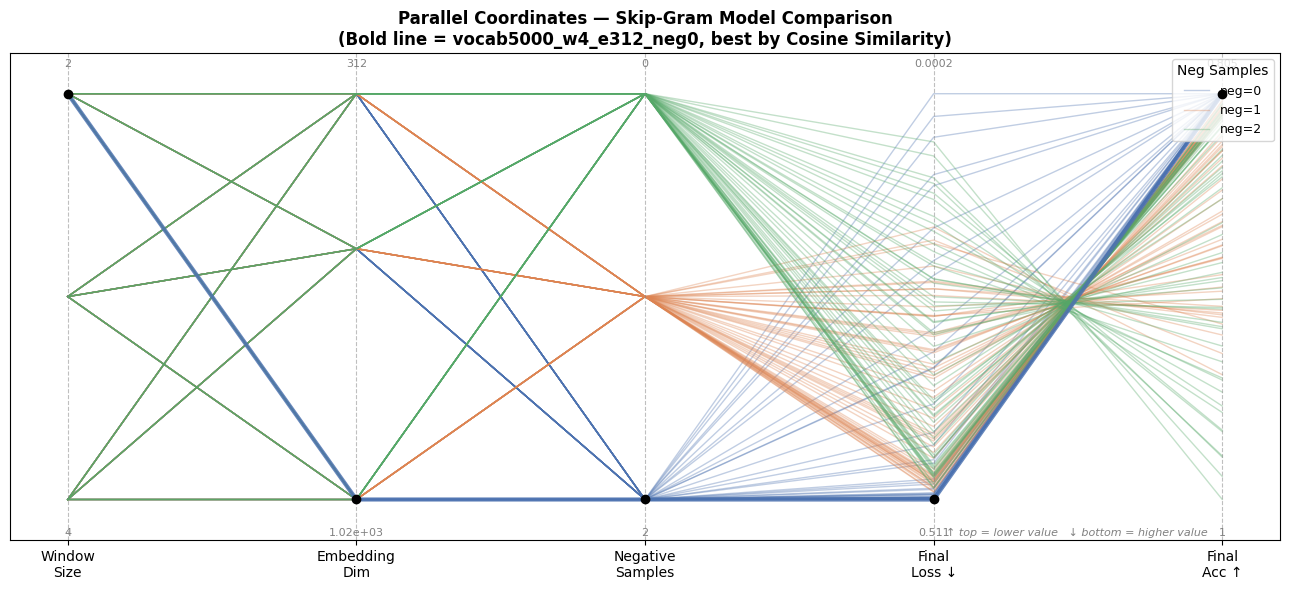

In [237]:
plot_df = comparison_df_new.copy()

for col in ['Window', 'Emb Dim', 'Neg Samples', 'Final Loss', 'Final Acc']:
    col_min, col_max = plot_df[col].min(), plot_df[col].max()
    plot_df[f'{col} (norm)'] = (
        (plot_df[col] - col_min) / (col_max - col_min)
        if col_max != col_min else 0.5
    )

norm_cols = ['Window (norm)', 'Emb Dim (norm)',
             'Neg Samples (norm)', 'Final Loss (norm)', 'Final Acc (norm)']

plot_df['Group'] = 'neg=' + plot_df['Neg Samples'].astype(str)
colors = {'neg=0': '#4C72B0', 'neg=1': '#DD8452', 'neg=2': '#55A868'}

fig, ax = plt.subplots(figsize=(13, 6))

for group, sub in plot_df.groupby('Group'):
    for _, row in sub.iterrows():
        y_vals  = [row[c] for c in norm_cols]
        is_best = row['Model ID'] == BEST_MODEL   # ← cosine similarity winner
        ax.plot(range(len(norm_cols)), y_vals,
                color=colors[group],
                alpha=0.85 if is_best else 0.35,
                linewidth=3.0 if is_best else 1.0,
                zorder=5 if is_best else 2,
                label=group if row.name == sub.index[0] else '_')
        if is_best:
            ax.plot(range(len(norm_cols)), y_vals,
                    'o', color='black', markersize=6, zorder=6)

orig_cols = ['Window', 'Emb Dim', 'Neg Samples', 'Final Loss', 'Final Acc']

for i, orig_col in enumerate(orig_cols):
    ax.axvline(i, color='grey', linewidth=0.8, linestyle='--', alpha=0.5)
    col_min = plot_df[orig_col].min()
    col_max = plot_df[orig_col].max()
    ax.text(i, -0.07, f'{col_max:.3g}', ha='center', va='top',    fontsize=8, color='grey')
    ax.text(i,  1.06, f'{col_min:.3g}', ha='center', va='bottom', fontsize=8, color='grey')

ax.set_xticks(range(len(norm_cols)))
ax.set_xticklabels(['Window\nSize', 'Embedding\nDim', 'Negative\nSamples',
                    'Final\nLoss ↓', 'Final\nAcc ↑'], fontsize=10)
ax.set_ylim(-0.1, 1.1)
ax.set_yticks([])
ax.set_title(f'Parallel Coordinates — Skip-Gram Model Comparison\n'
             f'(Bold line = {BEST_MODEL}, best by Cosine Similarity)',
             fontweight='bold', fontsize=12)
ax.legend(title='Neg Samples', loc='upper right', fontsize=9)

ax.text(len(norm_cols) - 1.05, -0.09,
        '↑ top = lower value   ↓ bottom = higher value',
        ha='right', fontsize=8, color='grey', style='italic')

plt.tight_layout()
plt.show()

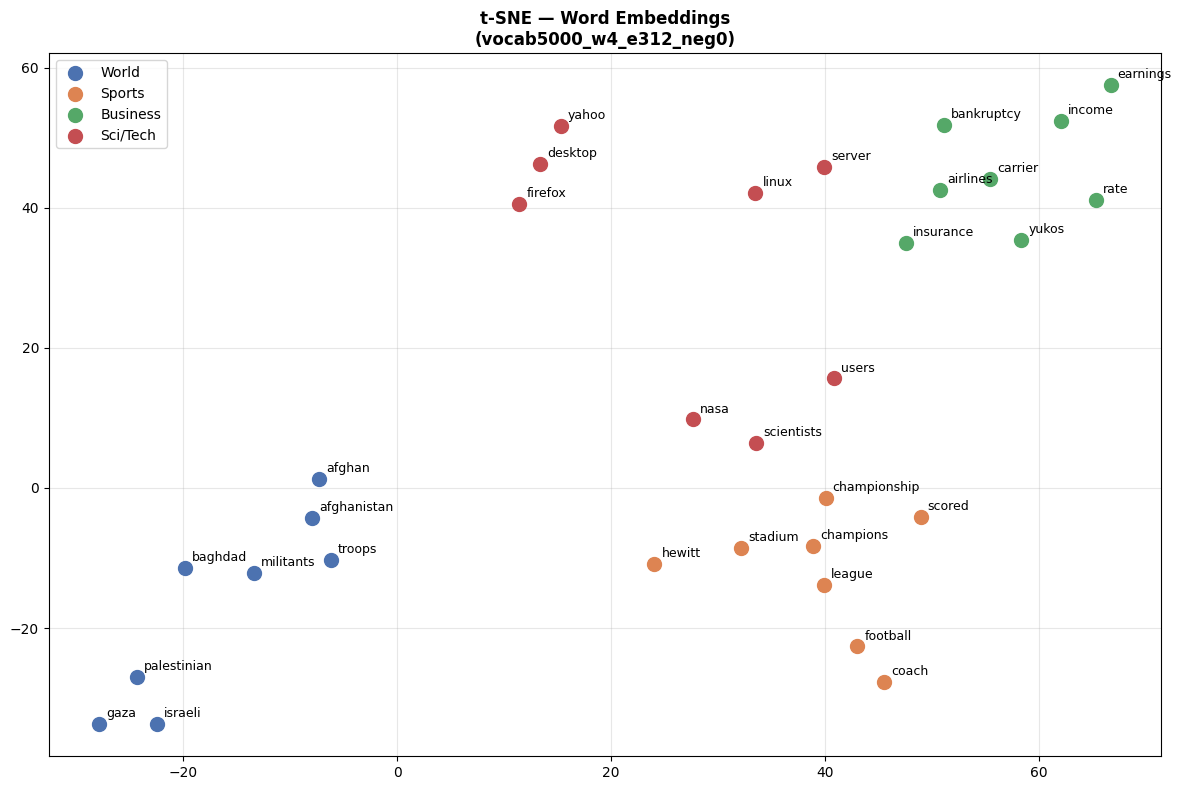

In [238]:
all_words_tsne  = [w for words in auto_groups.values() for w in words]
all_labels_tsne = [g for g, words in auto_groups.items() for w in words]
all_words_tsne  = [(w, l) for w, l in zip(all_words_tsne, all_labels_tsne)
                   if w in w2i_best]

words_plot  = [w for w, _ in all_words_tsne]
labels_plot = [l for _, l in all_words_tsne]
vectors     = np.array([emb_best[w2i_best[w]] for w in words_plot])

tsne       = TSNE(n_components=2, random_state=42, perplexity=min(5, len(words_plot) - 1))
vectors_2d = tsne.fit_transform(vectors)

COLORS_TSNE = {
    'World'   : '#4C72B0',
    'Sports'  : '#DD8452',
    'Business': '#55A868',
    'Sci/Tech': '#C44E52',
}

fig, ax = plt.subplots(figsize=(12, 8))
for group in auto_groups:
    mask = np.array([l == group for l in labels_plot])  # ← np.array, no lista Python
    x    = vectors_2d[mask, 0]
    y    = vectors_2d[mask, 1]
    ax.scatter(x, y, label=group, color=COLORS_TSNE[group], s=100, zorder=3)
    for i, word in enumerate([w for w, l in zip(words_plot, labels_plot) if l == group]):
        ax.annotate(word, (x[i], y[i]), fontsize=9,
                    xytext=(5, 5), textcoords='offset points')

ax.set_title(f't-SNE — Word Embeddings\n({BEST_MODEL})', fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [239]:
def word_analogy(a, b, c, emb, w2i, i2w, n=5):
    if not all(w in w2i for w in [a, b, c]):
        return None
    target = emb[w2i[a]] - emb[w2i[b]] + emb[w2i[c]]
    target = target / np.linalg.norm(target)
    sims   = cosine_similarity(target.reshape(1, -1), emb)[0]
    for w in [a, b, c]:
        sims[w2i[w]] = -1
    top_n = np.argsort(sims)[::-1][:n]
    return [(i2w[i], sims[i]) for i in top_n if i in i2w]

analogies = [
    ('baghdad',   'iraq',     'gaza',       'palestine'),
    ('league',    'football', 'championship','sport'),
    ('earnings',  'yukos',    'income',      'company'),
    ('firefox',   'browser',  'linux',       'system'),
    ('troops',    'baghdad',  'coach',       'league'),
]

print(f"Word Analogies — {BEST_MODEL}")
print("=" * 60)
for a, b, c, expected in analogies:
    results = word_analogy(a, b, c, emb_best, w2i_best, i2w_best, n=5)
    if results is None:
        missing = [w for w in [a,b,c] if w not in w2i_best]
        print(f"\n  {a} - {b} + {c} → Skipped (missing: {missing})")
        continue
    found = expected in [r[0] for r in results]
    print(f"\n  {a} - {b} + {c} = ? (expected: '{expected}')")
    for word, sim in results:
        marker = '✓' if word == expected else ' '
        print(f"    {marker} {word:20s} {sim:.4f}")

Word Analogies — vocab5000_w4_e312_neg0

  baghdad - iraq + gaza = ? (expected: 'palestine')
      israeli              0.9682
      palestinian          0.9616
      strip                0.9616
      hamas                0.9585
      ariel                0.9553

  league - football + championship = ? (expected: 'sport')
      6to5                 0.9738
      sixth                0.9724
      series               0.9704
      boston               0.9699
      became               0.9690

  earnings - yukos + income = ? (expected: 'company')
      aetna                0.9563
      posted               0.9541
      rise                 0.9532
      higher               0.9524
      firsthalf            0.9520

  firefox - browser + linux = ? (expected: 'system')
      source               0.9564
      free                 0.9560
      product              0.9555
      launches             0.9545
      businesses           0.9542

  troops - baghdad + coach = ? (expected: 'league')
     

  k=2: silhouette = 0.2428
  k=3: silhouette = 0.1529
  k=4: silhouette = 0.1350
  k=5: silhouette = 0.1249
  k=6: silhouette = 0.1279
  k=7: silhouette = 0.1558
  k=8: silhouette = 0.1434


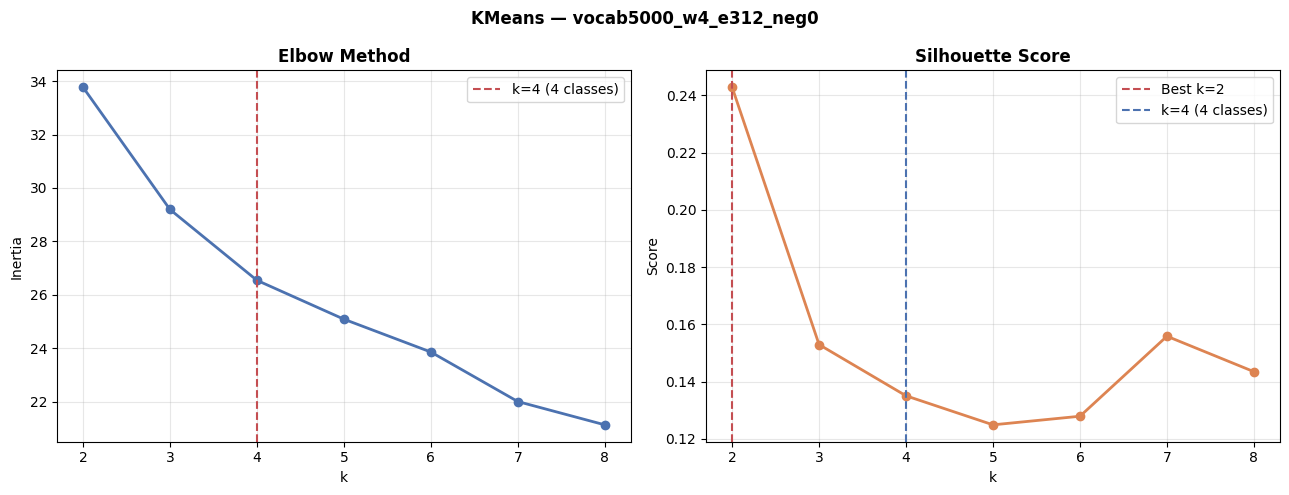


KMeans (k=2):
  Cluster 0: ['baghdad', 'israeli', 'gaza', 'militants', 'troops', 'palestinian', 'afghanistan', 'afghan', 'militant', 'hostages', 'fallujah', 'palestinians', 'rebel', 'darfur', 'kill', 'league', 'coach', 'football', 'championship', 'champions', 'scored', 'stadium', 'hewitt', 'nfl', 'baseball', 'tournament', 'basketball', 'williams', 'prix', 'quarterback', 'earnings', 'yukos', 'bankruptcy', 'airlines', 'rate', 'insurance', 'income', 'carrier', 'airline', 'tax', 'worries', 'forecasts', 'boeing', 'airbus', 'expectations', 'users', 'nasa', 'scientists', 'linux', 'server', 'pcs', 'spam', 'ipod', 'mars']
  Cluster 1: ['desktop', 'yahoo', 'firefox', 'browser', 'mozilla', 'toolbar']


In [240]:
N_PER_CLASS = 15  # palabras por categoría

words_cluster  = []
labels_cluster = []
for class_name, excl in exclusive_per_class.items():
    top = [w for w, _ in global_counter_ext.most_common()
           if w in excl and w in w2i_best][:N_PER_CLASS]
    words_cluster.extend(top)
    labels_cluster.extend([class_name] * len(top))

vectors_cluster = np.array([emb_best[w2i_best[w]] for w in words_cluster])
K_range         = range(2, 9)

# Elbow
inertias = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(vectors_cluster).inertia_
            for k in K_range]

# Silhouette
sil_scores = []
for k in K_range:
    labels_k = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(vectors_cluster)
    sil_scores.append(silhouette_score(vectors_cluster, labels_k))
    print(f"  k={k}: silhouette = {sil_scores[-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(K_range, inertias, 'o-', color='#4C72B0', linewidth=2)
axes[0].axvline(x=4, color='#C44E52', linestyle='--', label='k=4 (4 classes)')
axes[0].set_title('Elbow Method', fontweight='bold')
axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia')
axes[0].legend(); axes[0].grid(alpha=0.3)

best_k = list(K_range)[sil_scores.index(max(sil_scores))]
axes[1].plot(K_range, sil_scores, 'o-', color='#DD8452', linewidth=2)
axes[1].axvline(x=best_k, color='#C44E52', linestyle='--', label=f'Best k={best_k}')
axes[1].axvline(x=4, color='#4C72B0', linestyle='--', label='k=4 (4 classes)')
axes[1].set_title('Silhouette Score', fontweight='bold')
axes[1].set_xlabel('k'); axes[1].set_ylabel('Score')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.suptitle(f'KMeans — {BEST_MODEL}', fontweight='bold')
plt.tight_layout()
plt.show()

# Final clustering
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
labels = kmeans.fit_predict(vectors_cluster)
print(f"\nKMeans (k={best_k}):")
for cid in range(best_k):
    cwords = [words_cluster[i] for i, l in enumerate(labels) if l == cid]
    print(f"  Cluster {cid}: {cwords}")

In [241]:
# Para visualización alineada con las 4 clases del dataset
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_4 = kmeans_4.fit_predict(vectors_cluster)

print("KMeans (k=4, alineado con clases del dataset):")
for cid in range(4):
    cwords = [words_cluster[i] for i, l in enumerate(labels_4) if l == cid]
    # Calcular clase dominante en cada cluster
    dominant = max(set([labels_cluster[i] for i, l in enumerate(labels_4) if l == cid]),
                   key=lambda c: sum(1 for i, l in enumerate(labels_4)
                                     if l == cid and labels_cluster[i] == c))
    print(f"  Cluster {cid} (dom: {dominant}): {cwords}")

KMeans (k=4, alineado con clases del dataset):
  Cluster 0 (dom: World): ['baghdad', 'israeli', 'gaza', 'militants', 'troops', 'palestinian', 'afghanistan', 'afghan', 'militant', 'fallujah', 'palestinians', 'kill']
  Cluster 1 (dom: Business): ['hostages', 'earnings', 'yukos', 'bankruptcy', 'airlines', 'rate', 'insurance', 'income', 'carrier', 'airline', 'tax', 'worries', 'forecasts', 'boeing', 'airbus', 'expectations', 'nasa', 'linux', 'server', 'pcs', 'ipod']
  Cluster 2 (dom: Sci/Tech): ['desktop', 'yahoo', 'firefox', 'browser', 'mozilla', 'toolbar']
  Cluster 3 (dom: Sports): ['rebel', 'darfur', 'league', 'coach', 'football', 'championship', 'champions', 'scored', 'stadium', 'hewitt', 'nfl', 'baseball', 'tournament', 'basketball', 'williams', 'prix', 'quarterback', 'users', 'scientists', 'spam', 'mars']


In [242]:
def get_nearest_neighbors(word, emb, w2i, i2w, n=5):
    if word not in w2i:
        return []
    idx    = w2i[word]
    vector = emb[idx].reshape(1, -1)
    sims   = cosine_similarity(vector, emb)[0]
    sims[idx] = -1
    top_n  = np.argsort(sims)[::-1][:n]
    return [(i2w[i], sims[i]) for i in top_n if i in i2w]

print(f"Nearest Neighbors — {BEST_MODEL}")
print("=" * 55)
for group, words in auto_groups.items():
    print(f"\n── {group} ──")
    for word in words[:3]:
        neighbors = get_nearest_neighbors(word, emb_best, w2i_best, i2w_best, n=5)
        if neighbors:
            print(f"\n  '{word}'")
            for neighbor, sim in neighbors:
                print(f"    {neighbor:20s} {sim:.4f}")
        else:
            print(f"\n  '{word}' — not in vocab")

Nearest Neighbors — vocab5000_w4_e312_neg0

── World ──

  'baghdad'
    bomb                 0.9912
    exploded             0.9879
    car                  0.9858
    killed               0.9857
    wounding             0.9855

  'israeli'
    gaza                 0.9941
    ariel                0.9884
    strip                0.9874
    occupation           0.9861
    referendum           0.9837

  'gaza'
    israeli              0.9941
    strip                0.9886
    ariel                0.9836
    occupation           0.9813
    palestinian          0.9797

── Sports ──

  'league'
    champions            0.9921
    team                 0.9876
    series               0.9873
    games                0.9859
    stadium              0.9854

  'coach'
    hoeppner             0.9878
    football             0.9843
    robson               0.9816
    neri                 0.9810
    roma                 0.9807

  'football'
    hoeppner             0.9849
    coach                

In [243]:
STOPWORDS.update([
    'against', 'into', 'last', 'yesterday', 'inc', 'york', 'back',
    'when', 'time', 'more', 'over', 'then', 'than', 'up', 'down'
])
word2idx = w2i_1200
top10_words = [w for w, c in word_counter_v2.most_common() 
               if w in word2idx and w not in STOPWORDS][:10]

print("Top 10 most frequent content words:")
print("=" * 40)
for i, word in enumerate(top10_words, 1):
    print(f"  {i:2}. '{word}' — {word_counter_v2[word]:,} occurrences")

Top 10 most frequent content words:
   1. 'world' — 7,309 occurrences
   2. 'oil' — 7,244 occurrences
   3. 'company' — 7,138 occurrences
   4. 'iraq' — 5,903 occurrences
   5. 'president' — 5,846 occurrences
   6. 'million' — 5,534 occurrences
   7. 'united' — 5,104 occurrences
   8. 'game' — 5,067 occurrences
   9. 'week' — 4,982 occurrences
  10. 'prices' — 4,909 occurrences


In [244]:
STOPWORDS.update(['no', 'year', 'percent', 'billion'])

top10_words = [w for w, c in word_counter_v2.most_common() 
               if w in word2idx and w not in STOPWORDS][:10]

print("Top 10 most frequent content words:")
print("=" * 40)
for i, word in enumerate(top10_words, 1):
    print(f"  {i:2}. '{word}' — {word_counter_v2[word]:,} occurrences")

Top 10 most frequent content words:
   1. 'world' — 7,309 occurrences
   2. 'oil' — 7,244 occurrences
   3. 'company' — 7,138 occurrences
   4. 'iraq' — 5,903 occurrences
   5. 'president' — 5,846 occurrences
   6. 'million' — 5,534 occurrences
   7. 'united' — 5,104 occurrences
   8. 'game' — 5,067 occurrences
   9. 'week' — 4,982 occurrences
  10. 'prices' — 4,909 occurrences


In [245]:
candidate_groups = {
    'Politics'  : ['president', 'minister', 'government', 'election', 'iraq'],
    'Finance'   : ['oil', 'stocks', 'market', 'prices', 'company'],
    'Technology': ['microsoft', 'software', 'internet', 'computer', 'google'],
    'Sports'    : ['game', 'team', 'season', 'win', 'coach'],
    'Military'  : ['attack', 'troops', 'force', 'military', 'killed'],
}

for group, words in candidate_groups.items():
    print(f"\n{group}:")
    for w in words:
        freq = global_counter_ext.get(w, 0)
        status = '✓' if w in w2i_best else '✗'
        print(f"  {status} {w:15s} freq={freq:,}")


Politics:
  ✓ president       freq=98
  ✓ minister        freq=65
  ✓ government      freq=71
  ✓ election        freq=41
  ✓ iraq            freq=115

Finance:
  ✓ oil             freq=129
  ✓ stocks          freq=50
  ✓ market          freq=50
  ✓ prices          freq=76
  ✓ company         freq=105

Technology:
  ✗ microsoft       freq=97
  ✗ software        freq=65
  ✓ internet        freq=66
  ✗ computer        freq=47
  ✗ google          freq=34

Sports:
  ✓ game            freq=79
  ✓ team            freq=61
  ✓ season          freq=82
  ✓ win             freq=78
  ✓ coach           freq=36

Military:
  ✓ attack          freq=33
  ✓ troops          freq=28
  ✓ force           freq=16
  ✓ military        freq=31
  ✓ killed          freq=60


In [246]:
tech_candidates = ['internet', 'users', 'network', 'browser', 'linux',
                   'spam', 'pcs', 'toolbar', 'nasa', 'scientists',
                   'firefox', 'desktop', 'server', 'yahoo', 'mozilla']

print("Technology candidates in vocab5000:")
for w in tech_candidates:
    if w in w2i_best:
        print(f"  ✓ {w:15s} freq={global_counter_ext.get(w, 0):,}")

Technology candidates in vocab5000:
  ✓ internet        freq=66
  ✓ users           freq=28
  ✓ network         freq=21
  ✓ browser         freq=14
  ✓ linux           freq=19
  ✓ spam            freq=14
  ✓ pcs             freq=15
  ✓ toolbar         freq=12
  ✓ nasa            freq=27
  ✓ scientists      freq=19
  ✓ firefox         freq=15
  ✓ desktop         freq=21
  ✓ server          freq=17
  ✓ yahoo           freq=16
  ✓ mozilla         freq=13


In [247]:
word2idx = w2i_best
idx2word = i2w_best
candidate_groups = {
    'Politics'  : ['president', 'minister', 'government', 'election', 'iraq'],
    'Finance'   : ['oil', 'stocks', 'market', 'prices', 'company'],
    'Technology': ['internet', 'users', 'network', 'nasa', 'browser'],
    'Sports'    : ['game', 'team', 'season', 'win', 'coach'],
    'Military'  : ['attack', 'troops', 'force', 'military', 'killed'],
}

WORD_GROUPS = {}
for group, words in candidate_groups.items():
    valid = [w for w in words if w in word2idx]
    missing = [w for w in words if w not in word2idx]
    WORD_GROUPS[group] = valid
    print(f"{group}: {valid}")
    if missing:
        print(f"  Missing: {missing}")

Politics: ['president', 'minister', 'government', 'election', 'iraq']
Finance: ['oil', 'stocks', 'market', 'prices', 'company']
Technology: ['internet', 'users', 'network', 'nasa', 'browser']
Sports: ['game', 'team', 'season', 'win', 'coach']
Military: ['attack', 'troops', 'force', 'military', 'killed']


In [248]:
for group, words in WORD_GROUPS.items():
    print(f"\n{'='*50}")
    print(f"  {group}")
    print(f"{'='*50}")
    for w1, w2 in combinations(words, 2):
        v1 = emb_best[word2idx[w1]].reshape(1, -1)
        v2 = emb_best[word2idx[w2]].reshape(1, -1)
        sim = cosine_similarity(v1, v2)[0][0]
        print(f"  {w1:15s} ↔ {w2:15s} : {sim:.4f}")


  Politics
  president       ↔ minister        : 0.9507
  president       ↔ government      : 0.9798
  president       ↔ election        : 0.9742
  president       ↔ iraq            : 0.9746
  minister        ↔ government      : 0.9657
  minister        ↔ election        : 0.9696
  minister        ↔ iraq            : 0.9610
  government      ↔ election        : 0.9829
  government      ↔ iraq            : 0.9842
  election        ↔ iraq            : 0.9827

  Finance
  oil             ↔ stocks          : 0.9805
  oil             ↔ market          : 0.9465
  oil             ↔ prices          : 0.9931
  oil             ↔ company         : 0.9660
  stocks          ↔ market          : 0.9302
  stocks          ↔ prices          : 0.9855
  stocks          ↔ company         : 0.9496
  market          ↔ prices          : 0.9471
  market          ↔ company         : 0.9805
  prices          ↔ company         : 0.9640

  Technology
  internet        ↔ users           : 0.9748
  internet        

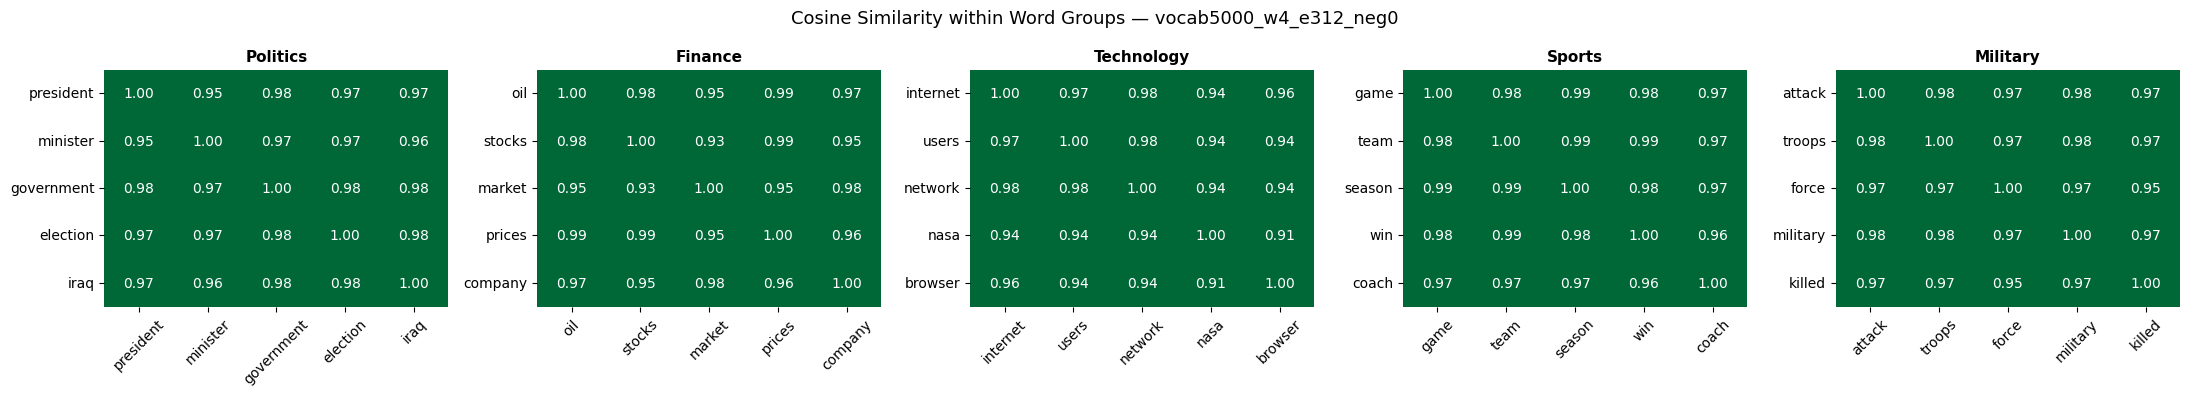

In [249]:
word2idx = w2i_best
def get_cosine_matrix(words, emb, word2idx):
    n = len(words)
    matrix = np.zeros((n, n))
    for i, w1 in enumerate(words):
        v1 = emb[word2idx[w1]].reshape(1, -1)
        for j, w2 in enumerate(words):
            v2 = emb[word2idx[w2]].reshape(1, -1)
            matrix[i, j] = cosine_similarity(v1, v2)[0][0]
    return matrix

fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for ax, (group, words) in zip(axes, WORD_GROUPS.items()):
    matrix = get_cosine_matrix(words, emb_best, word2idx)
    sns.heatmap(matrix,
                xticklabels=words,
                yticklabels=words,
                annot=True, fmt='.2f',
                cmap='RdYlGn', center=0,
                vmin=0, vmax=0.5,
                ax=ax,
                cbar=False)
    ax.set_title(group, fontweight='bold', fontsize=11)
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

plt.suptitle(f'Cosine Similarity within Word Groups — {BEST_MODEL}', fontsize=13)
plt.tight_layout()
plt.show()

In [250]:
COMPARE_PAIRS = [
    ('president', 'government'),
    ('oil',       'prices'),
    ('internet',  'network'),   
    ('game',      'win'),
    ('attack',    'force'),
]
NEG        = 1
BEST_VOCAB = 'vocab5000'
word2idx   = w2i_5000

embeddings_dict = {
    f"w{window}_e1024_neg{NEG}": embeddings_new[f"{BEST_VOCAB}_w{window}_e1024_neg{NEG}"]
    for window in WINDOW_SIZES
}

valid_pairs   = [(w1, w2) for w1, w2 in COMPARE_PAIRS if w1 in word2idx and w2 in word2idx]
skipped_pairs = [(w1, w2) for w1, w2 in COMPARE_PAIRS if w1 not in word2idx or w2 not in word2idx]

print(f"Cosine similarity sensitivity to window size (neg={NEG}, emb=1024)")
print(f"Vocab: {BEST_VOCAB}")
print("=" * 65)
print(f"  {'Pair':35s} {'w=2':>8} {'w=3':>8} {'w=4':>8}")
print(f"  {'-'*35} {'-'*8} {'-'*8} {'-'*8}")

for w1, w2 in valid_pairs:
    sims = []
    for window in WINDOW_SIZES:
        key = f"w{window}_e1024_neg{NEG}"
        emb = embeddings_dict[key]
        v1  = emb[word2idx[w1]].reshape(1, -1)
        v2  = emb[word2idx[w2]].reshape(1, -1)
        sims.append(cosine_similarity(v1, v2)[0][0])
    print(f"  {w1+' ↔ '+w2:35s} {sims[0]:>8.4f} {sims[1]:>8.4f} {sims[2]:>8.4f}")

if skipped_pairs:
    print("\nSkipped pairs (not in vocab):")
    for w1, w2 in skipped_pairs:
        print(f"  {w1} ↔ {w2}")

Cosine similarity sensitivity to window size (neg=1, emb=1024)
Vocab: vocab5000
  Pair                                     w=2      w=3      w=4
  ----------------------------------- -------- -------- --------
  president ↔ government                0.6161   0.7018   0.3275
  oil ↔ prices                          0.7782   0.7971   0.6811
  internet ↔ network                    0.6317   0.5576   0.4704
  game ↔ win                            0.5709   0.5628   0.4631
  attack ↔ force                        0.4312   0.5287   0.5036


In [251]:
NEG        = 1
BEST_VOCAB = 'vocab5000'
word2idx   = w2i_5000

embeddings_dict = {
    f"w{window}_e1024_neg{NEG}": embeddings_new[f"{BEST_VOCAB}_w{window}_e1024_neg{NEG}"]
    for window in WINDOW_SIZES
}

print(f"Cosine similarity sensitivity to window size (neg={NEG}, emb=1024)")
print(f"Vocab: {BEST_VOCAB} | Score = avg intra-group cosine similarity")
print("=" * 65)
print(f"  {'Group':20s} {'w=2':>8} {'w=3':>8} {'w=4':>8}  {'Δ(w2→w4)':>10}")
print(f"  {'-'*20} {'-'*8} {'-'*8} {'-'*8}  {'-'*10}")

for group, words in auto_groups.items():
    valid = [w for w in words if w in word2idx]
    if len(valid) < 2:
        print(f"  {group:20s} {'N/A':>8} {'N/A':>8} {'N/A':>8}")
        continue

    pairs = list(combinations(valid, 2))
    row_sims = []
    for window in WINDOW_SIZES:
        emb  = embeddings_dict[f"w{window}_e1024_neg{NEG}"]
        sims = [cosine_pair(w1, w2, emb, word2idx) for w1, w2 in pairs]
        sims = [s for s in sims if s is not None]
        row_sims.append(np.mean(sims) if sims else float('nan'))

    delta = row_sims[2] - row_sims[0]  # w=4 minus w=2
    sign  = '+' if delta >= 0 else ''
    print(f"  {group:20s} {row_sims[0]:>8.4f} {row_sims[1]:>8.4f} {row_sims[2]:>8.4f}  {sign}{delta:>9.4f}")

print(f"\n  {'AVERAGE':20s}", end='')
all_by_window = [[] for _ in WINDOW_SIZES]
for group, words in auto_groups.items():
    valid = [w for w in words if w in word2idx]
    if len(valid) < 2:
        continue
    pairs = list(combinations(valid, 2))
    for i, window in enumerate(WINDOW_SIZES):
        emb  = embeddings_dict[f"w{window}_e1024_neg{NEG}"]
        sims = [cosine_pair(w1, w2, emb, word2idx) for w1, w2 in pairs]
        all_by_window[i].extend([s for s in sims if s is not None])

avgs = [np.mean(s) if s else float('nan') for s in all_by_window]
delta_avg = avgs[2] - avgs[0]
sign = '+' if delta_avg >= 0 else ''
for a in avgs:
    print(f" {a:>8.4f}", end='')
print(f"  {sign}{delta_avg:>9.4f}")

Cosine similarity sensitivity to window size (neg=1, emb=1024)
Vocab: vocab5000 | Score = avg intra-group cosine similarity
  Group                     w=2      w=3      w=4    Δ(w2→w4)
  -------------------- -------- -------- --------  ----------
  World                  0.5530   0.4928   0.4187    -0.1344
  Sports                 0.6755   0.6052   0.5372    -0.1383
  Business               0.4260   0.4408   0.3598    -0.0662
  Sci/Tech               0.3393   0.2120   0.1966    -0.1428

  AVERAGE                0.4985   0.4377   0.3781    -0.1204


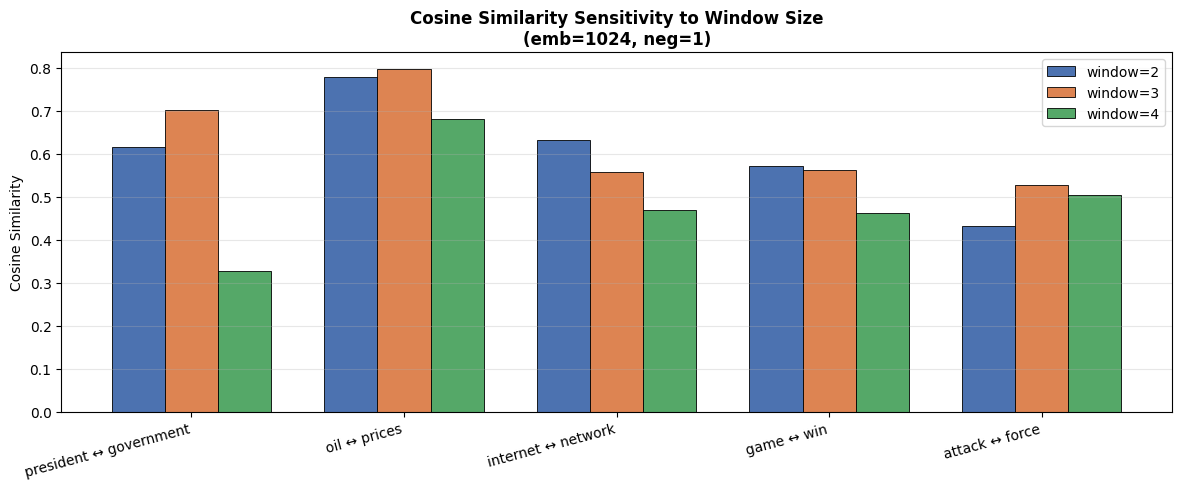

In [252]:
fig, ax = plt.subplots(figsize=(12, 5))

x = np.arange(len(valid_pairs))
width = 0.25
labels = [f"{w1} ↔ {w2}" for w1, w2 in valid_pairs]
colors = ['#4C72B0', '#DD8452', '#55A868']

for i, window in enumerate(WINDOW_SIZES):
    sims = []
    for w1, w2 in valid_pairs:
        key = f"w{window}_e1024_neg{NEG}"
        emb = embeddings_dict[key]
        v1  = emb[word2idx[w1]].reshape(1, -1)
        v2  = emb[word2idx[w2]].reshape(1, -1)
        sims.append(cosine_similarity(v1, v2)[0][0])
    ax.bar(x + i*width, sims, width, label=f'window={window}',
           color=colors[i], edgecolor='black', linewidth=0.6)

ax.set_xticks(x + width)
ax.set_xticklabels(labels, rotation=15, ha='right')
ax.set_title(f'Cosine Similarity Sensitivity to Window Size\n(emb=1024, neg={NEG})', fontweight='bold')
ax.set_ylabel('Cosine Similarity')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [253]:
WINDOW     = 2
NEG        = 1
BEST_VOCAB = 'vocab5000'
word2idx   = w2i_5000

embeddings_dim_dict = {
    f"w{WINDOW}_e{emb_dim}_neg{NEG}": embeddings_new[f"{BEST_VOCAB}_w{WINDOW}_e{emb_dim}_neg{NEG}"]
    for emb_dim in EMBEDDING_DIMS
}

print(f"Cosine similarity sensitivity to embedding dimension (window={WINDOW}, neg={NEG})")
print(f"Vocab: {BEST_VOCAB} | Score = avg intra-group cosine similarity")
print("=" * 68)
print(f"  {'Group':20s} {'e=312':>8} {'e=752':>8} {'e=1024':>8}  {'Δ(312→1024)':>12}")
print(f"  {'-'*20} {'-'*8} {'-'*8} {'-'*8}  {'-'*12}")

for group, words in auto_groups.items():
    valid = [w for w in words if w in word2idx]
    if len(valid) < 2:
        print(f"  {group:20s} {'N/A':>8} {'N/A':>8} {'N/A':>8}")
        continue

    pairs    = list(combinations(valid, 2))
    row_sims = []
    for emb_dim in EMBEDDING_DIMS:
        emb  = embeddings_dim_dict[f"w{WINDOW}_e{emb_dim}_neg{NEG}"]
        sims = [cosine_pair(w1, w2, emb, word2idx) for w1, w2 in pairs]
        sims = [s for s in sims if s is not None]
        row_sims.append(np.mean(sims) if sims else float('nan'))

    delta = row_sims[2] - row_sims[0]
    sign  = '+' if delta >= 0 else ''
    print(f"  {group:20s} {row_sims[0]:>8.4f} {row_sims[1]:>8.4f} {row_sims[2]:>8.4f}  {sign}{delta:>11.4f}")

print(f"\n  {'AVERAGE':20s}", end='')
all_by_dim = [[] for _ in EMBEDDING_DIMS]
for group, words in auto_groups.items():
    valid = [w for w in words if w in word2idx]
    if len(valid) < 2:
        continue
    pairs = list(combinations(valid, 2))
    for i, emb_dim in enumerate(EMBEDDING_DIMS):
        emb  = embeddings_dim_dict[f"w{WINDOW}_e{emb_dim}_neg{NEG}"]
        sims = [cosine_pair(w1, w2, emb, word2idx) for w1, w2 in pairs]
        all_by_dim[i].extend([s for s in sims if s is not None])

avgs      = [np.mean(s) if s else float('nan') for s in all_by_dim]
delta_avg = avgs[2] - avgs[0]
sign      = '+' if delta_avg >= 0 else ''
for a in avgs:
    print(f" {a:>8.4f}", end='')
print(f"  {sign}{delta_avg:>11.4f}")

Cosine similarity sensitivity to embedding dimension (window=2, neg=1)
Vocab: vocab5000 | Score = avg intra-group cosine similarity
  Group                   e=312    e=752   e=1024   Δ(312→1024)
  -------------------- -------- -------- --------  ------------
  World                  0.5285   0.5290   0.5530  +     0.0246
  Sports                 0.6456   0.6583   0.6755  +     0.0299
  Business               0.4077   0.4227   0.4260  +     0.0183
  Sci/Tech               0.3440   0.3448   0.3393      -0.0047

  AVERAGE                0.4814   0.4887   0.4985  +     0.0170


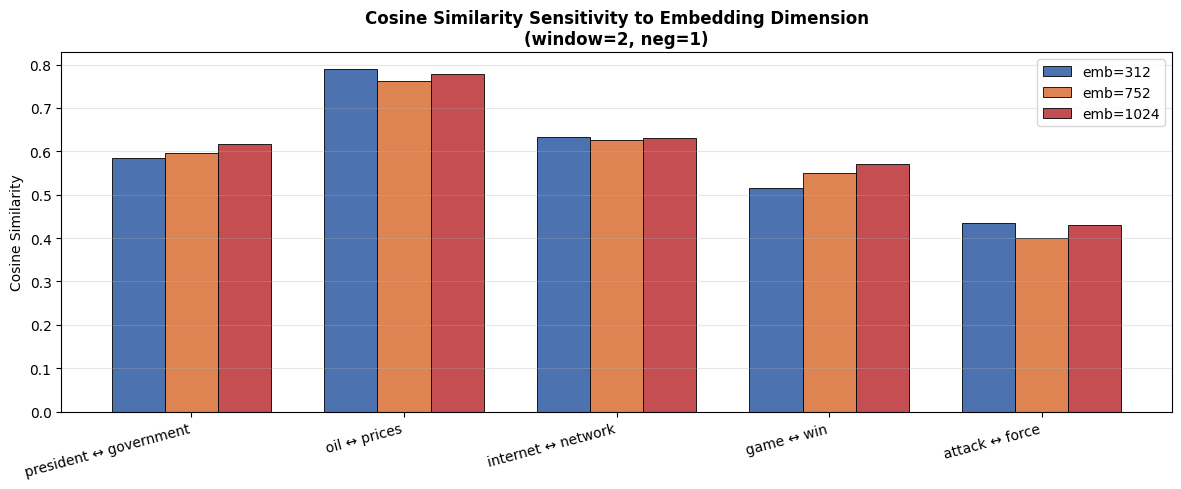

In [254]:
fig, ax = plt.subplots(figsize=(12, 5))

x = np.arange(len(valid_pairs))
width = 0.25
colors = ['#4C72B0', '#DD8452', '#C44E52']

for i, emb_dim in enumerate(EMBEDDING_DIMS):
    sims = []
    for w1, w2 in valid_pairs:
        key = f"w{WINDOW}_e{emb_dim}_neg{NEG}"
        emb = embeddings_dim_dict[key]
        v1  = emb[word2idx[w1]].reshape(1, -1)
        v2  = emb[word2idx[w2]].reshape(1, -1)
        sims.append(cosine_similarity(v1, v2)[0][0])
    ax.bar(x + i*width, sims, width, label=f'emb={emb_dim}',
           color=colors[i], edgecolor='black', linewidth=0.6)

ax.set_xticks(x + width)
ax.set_xticklabels([f"{w1} ↔ {w2}" for w1, w2 in valid_pairs], rotation=15, ha='right')
ax.set_title(f'Cosine Similarity Sensitivity to Embedding Dimension\n(window={WINDOW}, neg={NEG})', fontweight='bold')
ax.set_ylabel('Cosine Similarity')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

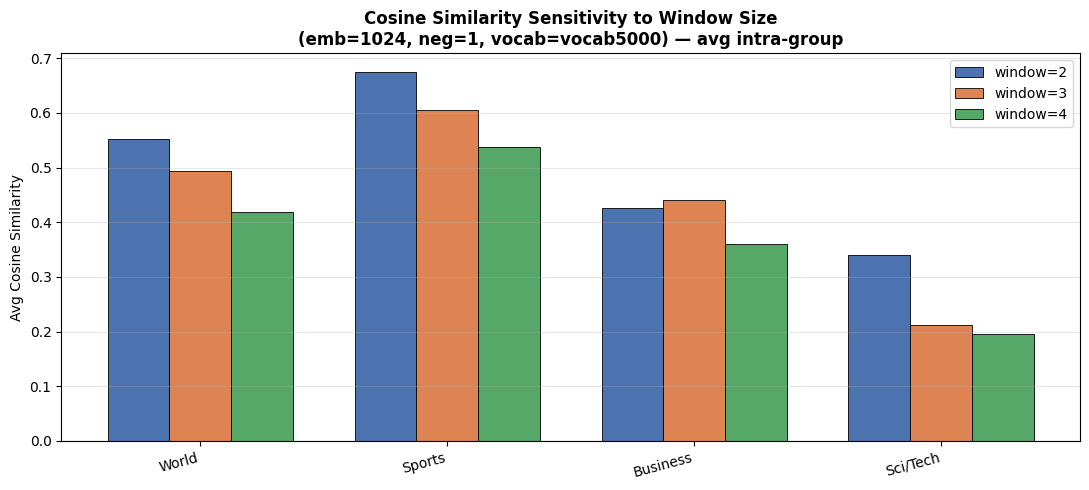

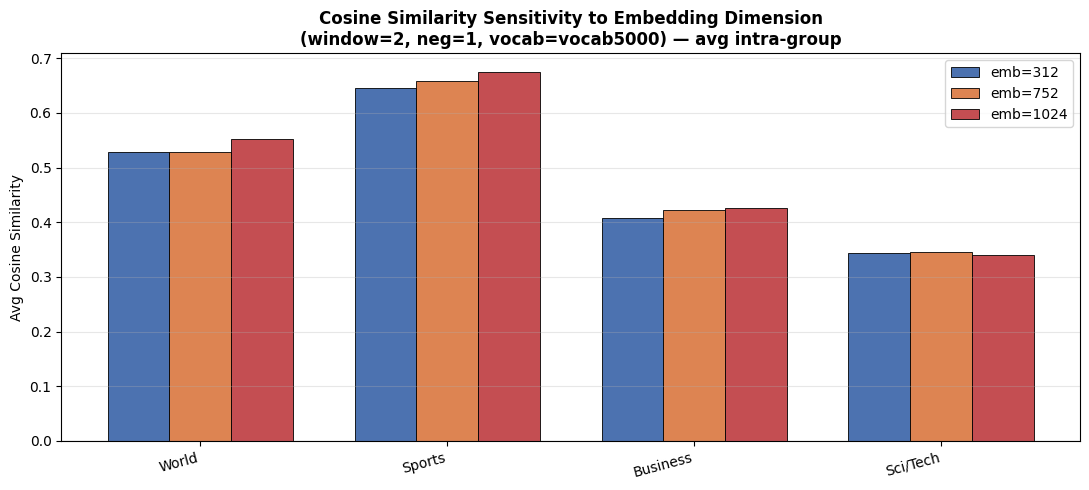

In [255]:
groups      = list(auto_groups.keys())
x           = np.arange(len(groups))
width       = 0.25
colors_win  = ['#4C72B0', '#DD8452', '#55A868']
colors_dim  = ['#4C72B0', '#DD8452', '#C44E52']

def avg_intra_group(group_name, emb, w2i):
    words = [w for w in auto_groups[group_name] if w in w2i]
    if len(words) < 2:
        return float('nan')
    sims = [cosine_pair(w1, w2, emb, w2i)
            for w1, w2 in combinations(words, 2)]
    sims = [s for s in sims if s is not None]
    return np.mean(sims) if sims else float('nan')

# ── Plot 1: Sensitivity to window size ───────────────────────
fig, ax = plt.subplots(figsize=(11, 5))

for i, window in enumerate(WINDOW_SIZES):
    emb   = embeddings_dict[f"w{window}_e1024_neg{NEG}"]
    vals  = [avg_intra_group(g, emb, word2idx) for g in groups]
    ax.bar(x + i*width, vals, width, label=f'window={window}',
           color=colors_win[i], edgecolor='black', linewidth=0.6)

ax.set_xticks(x + width)
ax.set_xticklabels(groups, rotation=15, ha='right')
ax.set_title(f'Cosine Similarity Sensitivity to Window Size\n'
             f'(emb=1024, neg={NEG}, vocab={BEST_VOCAB}) — avg intra-group',
             fontweight='bold')
ax.set_ylabel('Avg Cosine Similarity')
ax.axhline(0, color='grey', linewidth=0.8)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# ── Plot 2: Sensitivity to embedding dimension ────────────────
fig, ax = plt.subplots(figsize=(11, 5))

for i, emb_dim in enumerate(EMBEDDING_DIMS):
    emb  = embeddings_dim_dict[f"w{WINDOW}_e{emb_dim}_neg{NEG}"]
    vals = [avg_intra_group(g, emb, word2idx) for g in groups]
    ax.bar(x + i*width, vals, width, label=f'emb={emb_dim}',
           color=colors_dim[i], edgecolor='black', linewidth=0.6)

ax.set_xticks(x + width)
ax.set_xticklabels(groups, rotation=15, ha='right')
ax.set_title(f'Cosine Similarity Sensitivity to Embedding Dimension\n'
             f'(window={WINDOW}, neg={NEG}, vocab={BEST_VOCAB}) — avg intra-group',
             fontweight='bold')
ax.set_ylabel('Avg Cosine Similarity')
ax.axhline(0, color='grey', linewidth=0.8)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

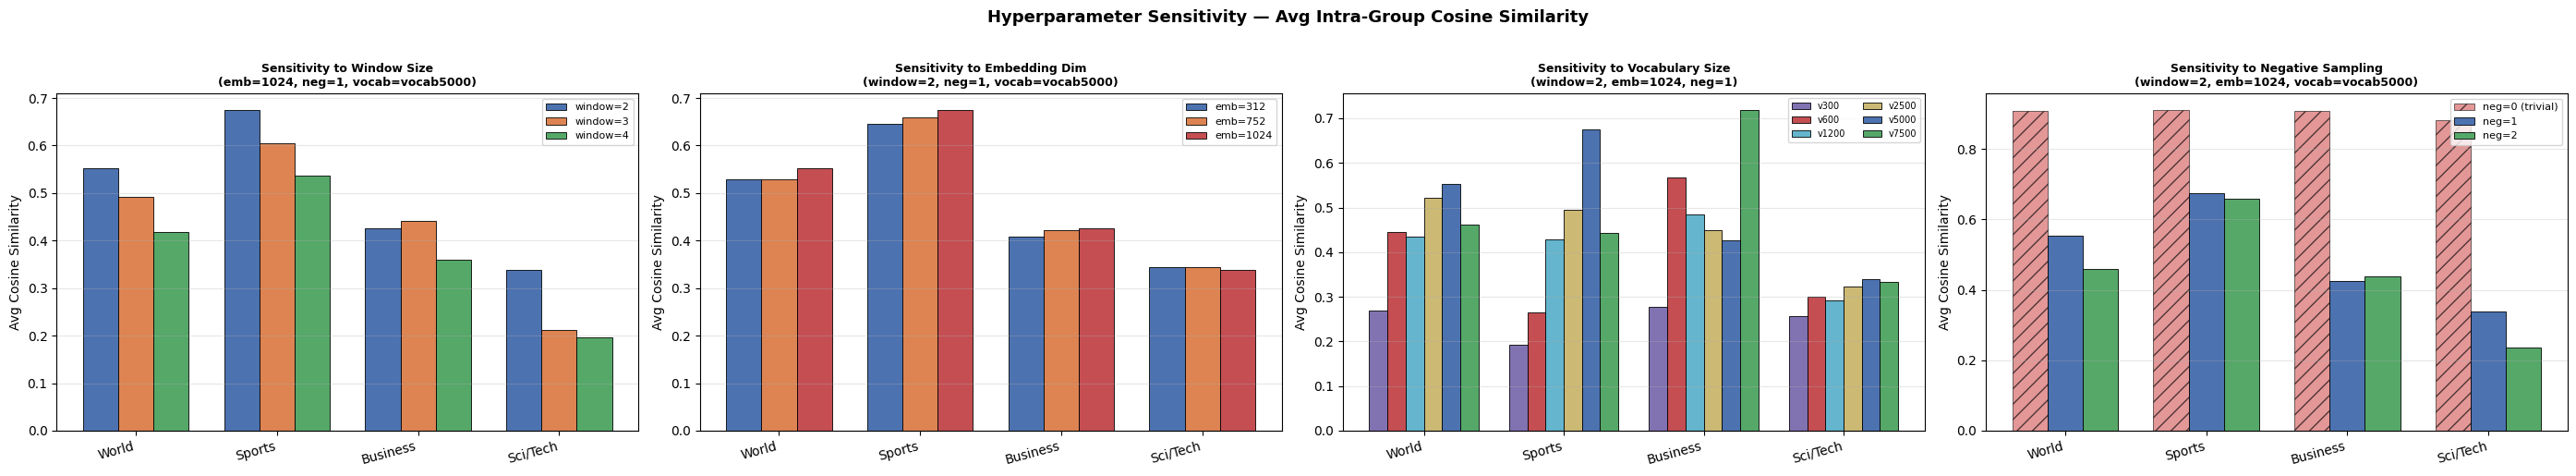

In [256]:
# ══════════════════════════════════════════════════════════════════════════════
# PLOT 3 & 4 — Vocabulary size + Negative Sampling sensitivity
# Se añaden a la misma figura que los plots 1 y 2 (1 fila × 4 columnas)
# ══════════════════════════════════════════════════════════════════════════════

# ── Parámetros fijos (mejor configuración según TOP-5) ────────────────────────
BEST_VOCAB  = 'vocab5000'
WINDOW      = 2
EMB         = 1024
NEG         = 1

VOCAB_NAMES  = ['vocab300', 'vocab600', 'vocab1200', 'vocab2500', 'vocab5000', 'vocab7500']
VOCAB_LABELS = ['v300',     'v600',     'v1200',     'v2500',     'v5000',     'v7500']
NEG_LIST     = [0, 1, 2]

groups = list(auto_groups.keys())
x      = np.arange(len(groups))

# ── Paletas ────────────────────────────────────────────────────────────────────
colors_win   = ['#4C72B0', '#DD8452', '#55A868']                              # Plot 1
colors_dim   = ['#4C72B0', '#DD8452', '#C44E52']                              # Plot 2
colors_vocab = ['#8172B2', '#C44E52', '#64B5CD', '#CCB974', '#4C72B0', '#55A868']  # Plot 3 (6 vocabs)
colors_neg   = ['#D65F5F', '#4C72B0', '#55A868']                              # Plot 4

# ── Helper: similitud intra-grupo con w2i explícito ───────────────────────────
def avg_intra_group_v2(group_name, emb, w2i):
    words = [w for w in auto_groups[group_name] if w in w2i]
    if len(words) < 2:
        return float('nan')
    sims = [cosine_pair(w1, w2, emb, w2i) for w1, w2 in combinations(words, 2)]
    sims = [s for s in sims if s is not None]
    return np.mean(sims) if sims else float('nan')

# ══════════════════════════════════════════════════════════════════════════════
# FIGURA COMPLETA: 1 fila × 4 columnas
# ══════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 4, figsize=(28, 5), sharey=False)

# ── Plot 1: Window size ────────────────────────────────────────────────────────
ax = axes[0]
width_win = 0.25
for i, window in enumerate(WINDOW_SIZES):
    key  = f"{BEST_VOCAB}_w{window}_e{EMB}_neg{NEG}"
    emb  = embeddings_new[key]
    w2i  = VOCAB_W2I[BEST_VOCAB]
    vals = [avg_intra_group_v2(g, emb, w2i) for g in groups]
    ax.bar(x + i * width_win, vals, width_win, label=f'window={window}',
           color=colors_win[i], edgecolor='black', linewidth=0.6)

ax.set_xticks(x + width_win)
ax.set_xticklabels(groups, rotation=15, ha='right')
ax.set_title(f'Sensitivity to Window Size\n(emb={EMB}, neg={NEG}, vocab={BEST_VOCAB})',
             fontweight='bold', fontsize=9)
ax.set_ylabel('Avg Cosine Similarity')
ax.axhline(0, color='grey', linewidth=0.8)
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.3)

# ── Plot 2: Embedding dimension ────────────────────────────────────────────────
ax = axes[1]
width_dim = 0.25
for i, emb_dim in enumerate(EMBEDDING_DIMS):
    key  = f"{BEST_VOCAB}_w{WINDOW}_e{emb_dim}_neg{NEG}"
    emb  = embeddings_new[key]
    w2i  = VOCAB_W2I[BEST_VOCAB]
    vals = [avg_intra_group_v2(g, emb, w2i) for g in groups]
    ax.bar(x + i * width_dim, vals, width_dim, label=f'emb={emb_dim}',
           color=colors_dim[i], edgecolor='black', linewidth=0.6)

ax.set_xticks(x + width_dim)
ax.set_xticklabels(groups, rotation=15, ha='right')
ax.set_title(f'Sensitivity to Embedding Dim\n(window={WINDOW}, neg={NEG}, vocab={BEST_VOCAB})',
             fontweight='bold', fontsize=9)
ax.set_ylabel('Avg Cosine Similarity')
ax.axhline(0, color='grey', linewidth=0.8)
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.3)

# ── Plot 3: Vocabulary size ────────────────────────────────────────────────────
ax = axes[2]
n_vocab  = len(VOCAB_NAMES)
width_voc = 0.13          # 6 barras → más estrechas
for i, (vname, vlabel) in enumerate(zip(VOCAB_NAMES, VOCAB_LABELS)):
    key = f"{vname}_w{WINDOW}_e{EMB}_neg{NEG}"
    if key not in embeddings_new:         # por si no se entrenó ese combo
        continue
    emb  = embeddings_new[key]
    w2i  = VOCAB_W2I[vname]
    vals = [avg_intra_group_v2(g, emb, w2i) for g in groups]
    ax.bar(x + i * width_voc, vals, width_voc, label=vlabel,
           color=colors_vocab[i], edgecolor='black', linewidth=0.6)

ax.set_xticks(x + width_voc * (n_vocab - 1) / 2)
ax.set_xticklabels(groups, rotation=15, ha='right')
ax.set_title(f'Sensitivity to Vocabulary Size\n(window={WINDOW}, emb={EMB}, neg={NEG})',
             fontweight='bold', fontsize=9)
ax.set_ylabel('Avg Cosine Similarity')
ax.axhline(0, color='grey', linewidth=0.8)
ax.legend(fontsize=7, ncol=2)
ax.grid(axis='y', alpha=0.3)

# ── Plot 4: Negative sampling ─────────────────────────────────────────────────
ax = axes[3]
width_neg = 0.25
w2i       = VOCAB_W2I[BEST_VOCAB]
for i, neg in enumerate(NEG_LIST):
    key = f"{BEST_VOCAB}_w{WINDOW}_e{EMB}_neg{neg}"
    if key not in embeddings_new:
        continue
    emb  = embeddings_new[key]
    vals = [avg_intra_group_v2(g, emb, w2i) for g in groups]
    label = f'neg={neg}' + (' (trivial)' if neg == 0 else '')
    ax.bar(x + i * width_neg, vals, width_neg, label=label,
           color=colors_neg[i], edgecolor='black', linewidth=0.6,
           alpha=0.65 if neg == 0 else 1.0,   # neg=0 semitransparente
           hatch='//' if neg == 0 else '')     # hatch para resaltar que es trivial

ax.set_xticks(x + width_neg)
ax.set_xticklabels(groups, rotation=15, ha='right')
ax.set_title(f'Sensitivity to Negative Sampling\n(window={WINDOW}, emb={EMB}, vocab={BEST_VOCAB})',
             fontweight='bold', fontsize=9)
ax.set_ylabel('Avg Cosine Similarity')
ax.axhline(0, color='grey', linewidth=0.8)
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.3)

# ── Título general ─────────────────────────────────────────────────────────────
fig.suptitle('Hyperparameter Sensitivity — Avg Intra-Group Cosine Similarity',
             fontsize=13, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig('sensitivity_all4.png', dpi=150, bbox_inches='tight')
plt.show()

#**NEAREST NEIGBOURS**

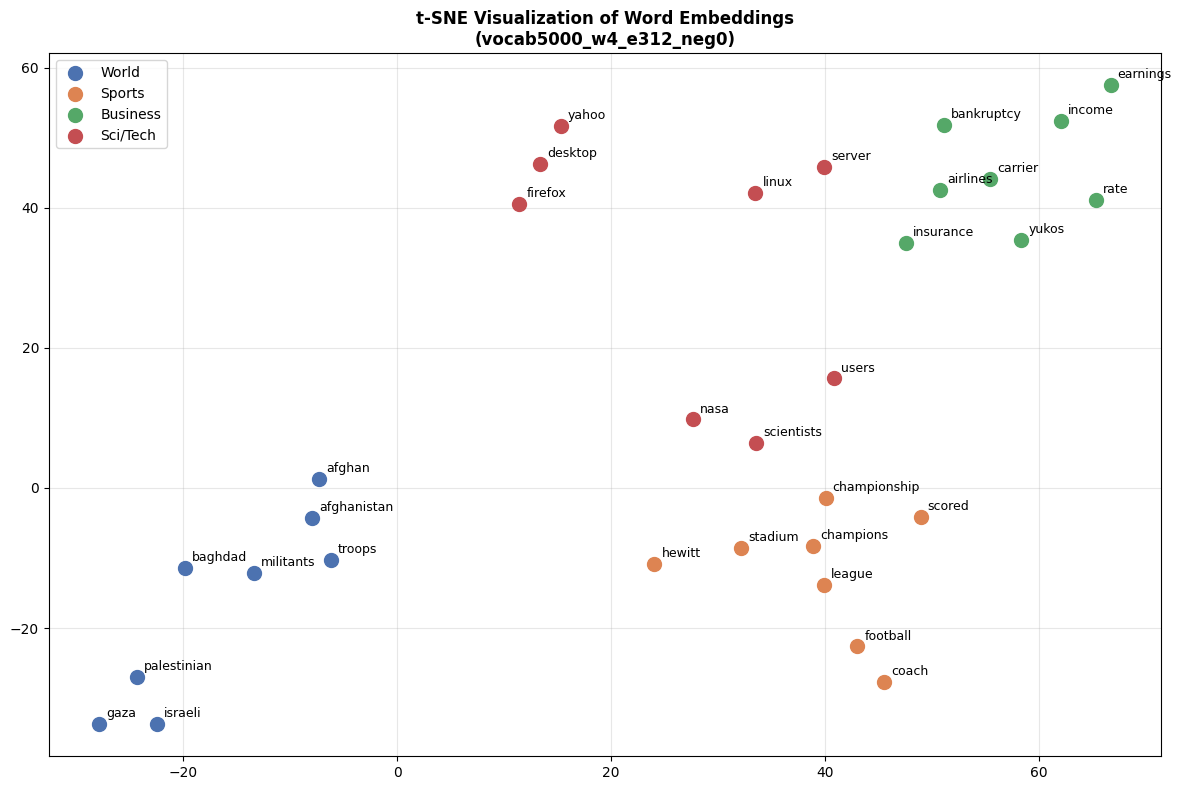

In [257]:
# Use words from all 5 groups for visualization
all_group_words = []
all_group_labels = []
colors_tsne = {
    'World'   : '#4C72B0',
    'Sports'  : '#DD8452',
    'Business': '#55A868',
    'Sci/Tech': '#C44E52',
}

for group, words in auto_groups.items():
    for w in words:
        if w in w2i_best:          # ← filtro necesario
            all_group_words.append(w)
            all_group_labels.append(group)

vectors   = np.array([emb_best[w2i_best[w]] for w in all_group_words])
tsne      = TSNE(n_components=2, random_state=42, perplexity=min(5, len(all_group_words) - 1))
vectors_2d = tsne.fit_transform(vectors)

fig, ax = plt.subplots(figsize=(12, 8))
for group in auto_groups.keys():
    mask = np.array([l == group for l in all_group_labels])  # ← np.array
    x    = vectors_2d[mask, 0]
    y    = vectors_2d[mask, 1]
    ax.scatter(x, y, label=group, color=colors_tsne[group], s=100, zorder=3)
    for i, word in enumerate([w for w, l in zip(all_group_words, all_group_labels) if l == group]):
        ax.annotate(word, (x[i], y[i]), fontsize=9,
                    xytext=(5, 5), textcoords='offset points')

ax.set_title(f't-SNE Visualization of Word Embeddings\n({BEST_MODEL})', fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [258]:
bv_rows = []
for key, hist in training_history_new.items():
    parts    = key.split('_')
    vocab    = parts[0]
    window   = int(parts[1][1:])
    emb_dim  = int(parts[2][1:])
    neg      = int(parts[3][3:])
    losses   = hist['loss']

    bias     = losses[-1]                          # final loss = bias proxy
    variance = np.std(losses[-3:]) if len(losses) >= 3 else 0.0  # std últimas 3 épocas

    bv_rows.append({
        'Model ID'   : key,
        'Vocab Set'  : vocab,
        'Window'     : window,
        'Emb Dim'    : emb_dim,
        'Neg Samples': neg,
        'Final Loss' : bias,
        'Variance'   : variance,
        'Bias'       : bias,
    })

bv_df = pd.DataFrame(bv_rows)
print(f"bv_df: {len(bv_df)} models")
print(bv_df[['Model ID','Final Loss','Variance','Bias']].head())

bv_df: 162 models
                 Model ID  Final Loss  Variance      Bias
0   vocab300_w2_e312_neg0    0.214771  0.063118  0.214771
1   vocab300_w2_e752_neg0    0.394933  0.039223  0.394933
2  vocab300_w2_e1024_neg0    0.510646  0.018443  0.510646
3   vocab300_w3_e312_neg0    0.165446  0.060376  0.165446
4   vocab300_w3_e752_neg0    0.341754  0.045741  0.341754


Modelos tras filtrado: 27 (de 162 no degenerados)


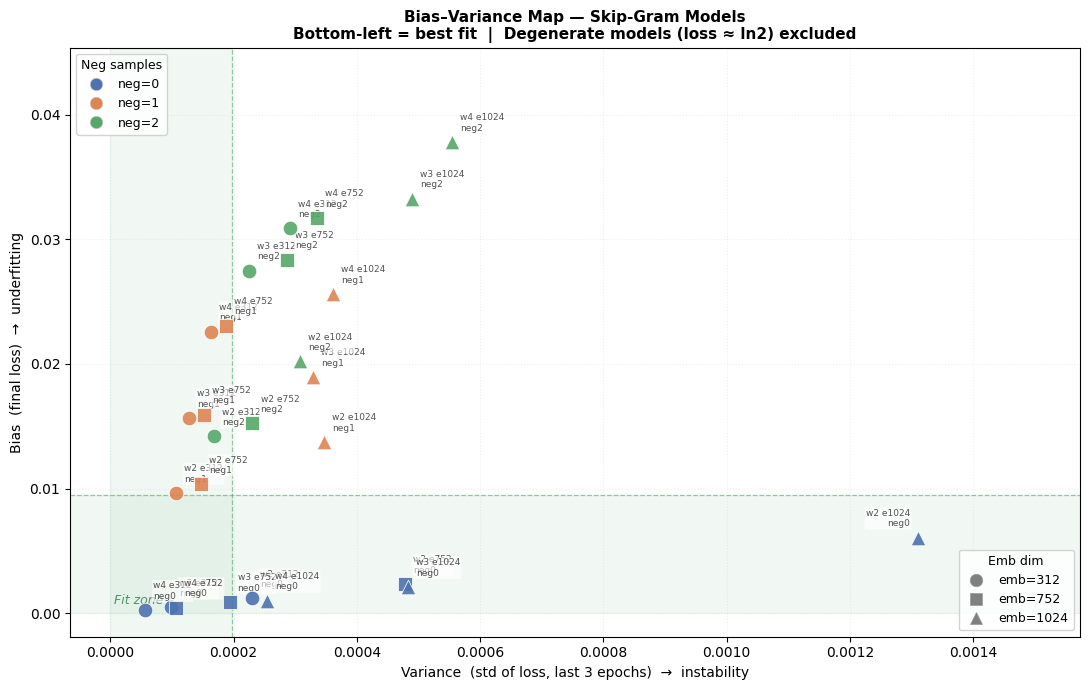

In [259]:
LOG2 = np.log(2)
TOLE = 0.015

clean_df = bv_df[abs(bv_df['Final Loss'] - LOG2) >= TOLE].copy()

plot_df = (clean_df
           .sort_values('Final Loss')
           .groupby(['Neg Samples', 'Emb Dim', 'Window'], as_index=False)
           .first()
           .reset_index(drop=True))

print(f"Modelos tras filtrado: {len(plot_df)} (de {len(clean_df)} no degenerados)")

colors_neg  = {0: '#4C72B0', 1: '#DD8452', 2: '#55A868'}
markers_emb = {312: 'o', 752: 's', 1024: '^'}

x_max = plot_df['Variance'].max()
y_max = plot_df['Bias'].max()

fig, ax = plt.subplots(figsize=(11, 7))

# Fit zone adaptada al rango real de los datos
fit_x = x_max * 0.15
fit_y = y_max * 0.25
ax.axhspan(0,     fit_y, color='#55A868', alpha=0.08)
ax.axvspan(0,     fit_x, color='#55A868', alpha=0.08)
ax.axhline(fit_y, color='#55A868', linestyle='--', linewidth=0.9, alpha=0.6)
ax.axvline(fit_x, color='#55A868', linestyle='--', linewidth=0.9, alpha=0.6)
ax.text(x_max * 0.005, y_max * 0.02, 'Fit zone',
        fontsize=9, color='#2a7a4a', alpha=0.8, style='italic')

# Puntos
for _, row in plot_df.iterrows():
    ax.scatter(row['Variance'], row['Bias'],
               color=colors_neg[row['Neg Samples']],
               marker=markers_emb[row['Emb Dim']],
               s=110, alpha=0.9, zorder=4,
               edgecolors='white', linewidths=0.6)

# Labels
for _, row in plot_df.iterrows():
    x, y   = row['Variance'], row['Bias']
    label  = f"w{row['Window']} e{row['Emb Dim']}\nneg{row['Neg Samples']}"
    ha     = 'left' if x < x_max * 0.5 else 'right'
    dx     = x_max * 0.01 if x < x_max * 0.5 else -x_max * 0.01
    ax.annotate(label, xy=(x, y), xytext=(x + dx, y + y_max * 0.02),
                fontsize=6.5, ha=ha, va='bottom', color='#333333', alpha=0.85,
                bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.6))

# Leyendas
legend_neg = [Line2D([0],[0], marker='o', color='w',
                     markerfacecolor=c, label=f'neg={n}',
                     markersize=9, markeredgecolor='#cccccc', markeredgewidth=0.5)
              for n, c in colors_neg.items()]
legend_emb = [Line2D([0],[0], marker=m, color='gray',
                     label=f'emb={e}', markersize=9,
                     linestyle='None', markeredgecolor='#999999', markeredgewidth=0.5)
              for e, m in markers_emb.items()]

leg1 = ax.legend(handles=legend_neg, loc='upper left', fontsize=9,
                 title='Neg samples', title_fontsize=9, framealpha=0.85)
ax.add_artist(leg1)
ax.legend(handles=legend_emb, loc='lower right', fontsize=9,
          title='Emb dim', title_fontsize=9, framealpha=0.85)

# Límites forzados al rango real de los datos
ax.set_xlim(-x_max * 0.05, x_max * 1.20)
ax.set_ylim(-y_max * 0.05, y_max * 1.20)

ax.set_xlabel('Variance  (std of loss, last 3 epochs)  →  instability', fontsize=10)
ax.set_ylabel('Bias  (final loss)  →  underfitting', fontsize=10)
ax.set_title(f'Bias–Variance Map — Skip-Gram Models\n'
             f'Bottom-left = best fit  |  Degenerate models (loss ≈ ln2) excluded',
             fontweight='bold', fontsize=11)
ax.grid(True, alpha=0.2, linestyle=':')
plt.tight_layout()
plt.show()

In [260]:
# ── Stopwords — function words that carry no semantic meaning ─────────────────
EVAL_STOPWORDS = {
    # articles / determiners
    'the','a','an','this','that','these','those',
    # prepositions
    'of','in','to','for','on','at','by','from','with','into','over',
    'about','after','before','between','through','during','under','against',
    # conjunctions / pronouns
    'and','or','but','it','its','he','she','they','we','his','her','their',
    'who','which','what','when','where','is','are','was','were','be','been',
    'have','has','had','do','does','did','will','would','could','should',
    'may','might','not','no','as','than','then','up','down','back',
    # news-corpus noise
    'said','says','new','first','last','more','also','one','two','three',
    'year','percent','billion','million','time',
    'reuters','ap','afp','quot','com','inc','york',
}

# ── Use the vocabulary already built (word_counter_v2 from Step 2) ────────────
# word_counter_v2 and w2i_best (or w2i_1200) must already exist in memory
word2idx = w2i_best          # best vocab's word→index mapping
emb_best_np = emb_best       # numpy embedding matrix (vocab_size × emb_dim)

top10_words = [
    w for w, _count in word_counter_v2.most_common()
    if w in word2idx and w not in EVAL_STOPWORDS
][:10]

print("Top 10 most frequent MEANINGFUL words in the dictionary:")
print("─" * 45)
for rank, word in enumerate(top10_words, 1):
    freq = word_counter_v2[word]
    print(f"  {rank:2d}. {word:<20s}  freq = {freq:,}")

Top 10 most frequent MEANINGFUL words in the dictionary:
─────────────────────────────────────────────
   1. world                 freq = 7,309
   2. oil                   freq = 7,244
   3. company               freq = 7,138
   4. yesterday             freq = 6,028
   5. iraq                  freq = 5,903
   6. president             freq = 5,846
   7. united                freq = 5,104
   8. game                  freq = 5,067
   9. week                  freq = 4,982
  10. prices                freq = 4,909


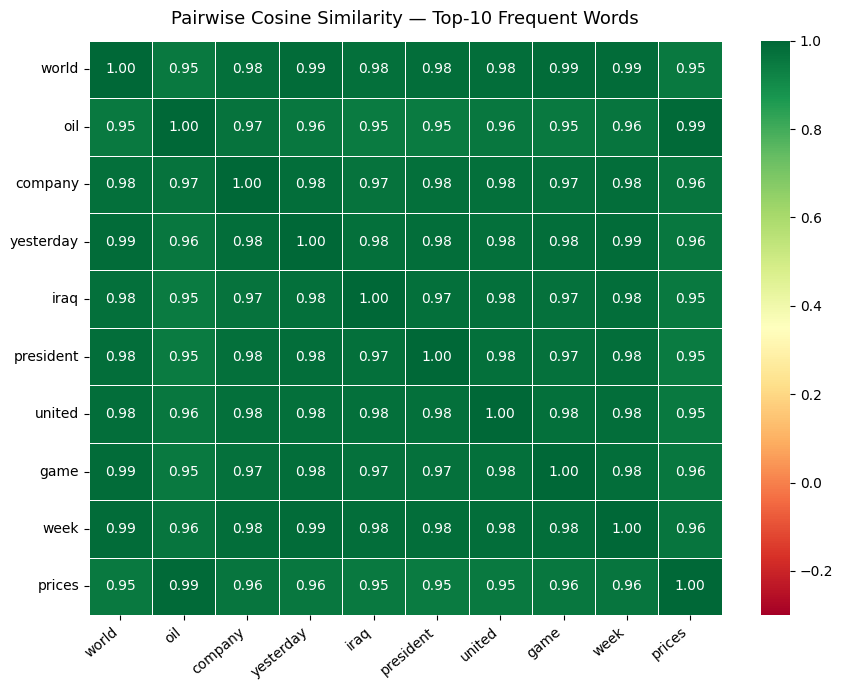


Summary (off-diagonal pairs):
  Mean cosine similarity : 0.9713
  Max  cosine similarity : 0.9931
  Min  cosine similarity : 0.9471
  Most  similar pair: 'oil' ↔ 'prices' = 0.9931


In [261]:
def cosine_matrix(words, emb, w2i):
    """Return a symmetric cosine-similarity matrix for a list of words."""
    vecs = np.array([emb[w2i[w]] for w in words])  # shape (n, d)
    # sklearn normalises each row before dot product → cosine similarity
    return cosine_similarity(vecs)

# ── Compute matrix ────────────────────────────────────────────────────────────
sim_matrix_10 = cosine_matrix(top10_words, emb_best_np, word2idx)

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 7))
mask = np.eye(len(top10_words), dtype=bool)  # hide diagonal (self-similarity = 1)

sns.heatmap(
    sim_matrix_10,
    xticklabels=top10_words, yticklabels=top10_words,
    annot=True, fmt='.2f',
    cmap='RdYlGn',       # red=dissimilar, green=similar
    vmin=-0.3, vmax=1.0,
    linewidths=0.5,
    ax=ax
)
ax.set_title('Pairwise Cosine Similarity — Top-10 Frequent Words', fontsize=13, pad=12)
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.savefig('eval_top10_cosine_heatmap.png', dpi=150)
plt.show()

# ── Summary statistics ────────────────────────────────────────────────────────
upper = sim_matrix_10[np.triu_indices_from(sim_matrix_10, k=1)]
print(f"\nSummary (off-diagonal pairs):")
print(f"  Mean cosine similarity : {upper.mean():.4f}")
print(f"  Max  cosine similarity : {upper.max():.4f}")
print(f"  Min  cosine similarity : {upper.min():.4f}")
most_sim   = np.unravel_index(np.argmax(sim_matrix_10 - np.eye(10)), (10,10))
print(f"  Most  similar pair: '{top10_words[most_sim[0]]}' ↔ '{top10_words[most_sim[1]]}' = {sim_matrix_10[most_sim]:.4f}")

In [262]:
# ── Define 5 semantic groups — adjust words if not in your vocab ──────────────
WORD_GROUPS = {
    'Politics'   : ['president', 'minister', 'government', 'election', 'parliament'],
    'Finance'    : ['oil', 'stocks', 'market', 'prices', 'company'],
    'Sports'     : ['game', 'season', 'players', 'team', 'win'],
    'Conflict'   : ['troops', 'attack', 'military', 'killed', 'force'],
    'Technology' : ['internet', 'software', 'network', 'users', 'computer'],
}

# ── Filter to words actually in vocab ────────────────────────────────────────
filtered_groups = {}
for group, words in WORD_GROUPS.items():
    valid = [w for w in words if w in word2idx]
    if len(valid) >= 2:
        filtered_groups[group] = valid
    print(f"{group:12s}: {valid} {'⚠ (some words OOV)' if len(valid)<len(words) else ''}")

print()

# ── For each group: print pairwise cosine similarities ───────────────────────
group_stats = {}
for group, words in filtered_groups.items():
    sims = []
    print(f"{'='*55}")
    print(f"  GROUP: {group}")
    print(f"{'='*55}")
    print(f"  {'Pair':35s}  {'Cosine Sim':>10}")
    print(f"  {'-'*35}  {'-'*10}")
    for w1, w2 in combinations(words, 2):
        v1 = emb_best_np[word2idx[w1]].reshape(1, -1)
        v2 = emb_best_np[word2idx[w2]].reshape(1, -1)
        sim = cosine_similarity(v1, v2)[0][0]
        sims.append(sim)
        print(f"  {w1+' ↔ '+w2:<35s}  {sim:>10.4f}")
    group_stats[group] = {'mean': np.mean(sims), 'min': np.min(sims), 'max': np.max(sims)}
    print(f"  → mean = {group_stats[group]['mean']:.4f}\n")

Politics    : ['president', 'minister', 'government', 'election', 'parliament'] 
Finance     : ['oil', 'stocks', 'market', 'prices', 'company'] 
Sports      : ['game', 'season', 'players', 'team', 'win'] 
Conflict    : ['troops', 'attack', 'military', 'killed', 'force'] 
Technology  : ['internet', 'network', 'users'] ⚠ (some words OOV)

  GROUP: Politics
  Pair                                 Cosine Sim
  -----------------------------------  ----------
  president ↔ minister                     0.9507
  president ↔ government                   0.9798
  president ↔ election                     0.9742
  president ↔ parliament                   0.9483
  minister ↔ government                    0.9657
  minister ↔ election                      0.9696
  minister ↔ parliament                    0.9780
  government ↔ election                    0.9829
  government ↔ parliament                  0.9647
  election ↔ parliament                    0.9650
  → mean = 0.9679

  GROUP: Finance
  Pair 

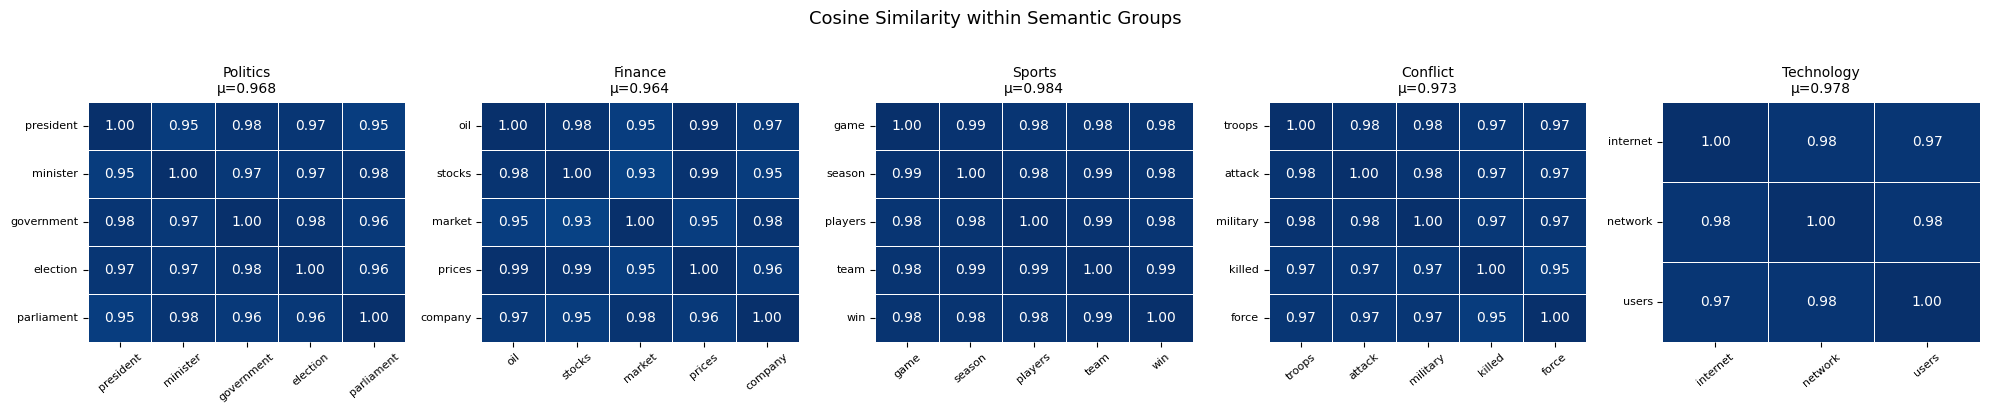

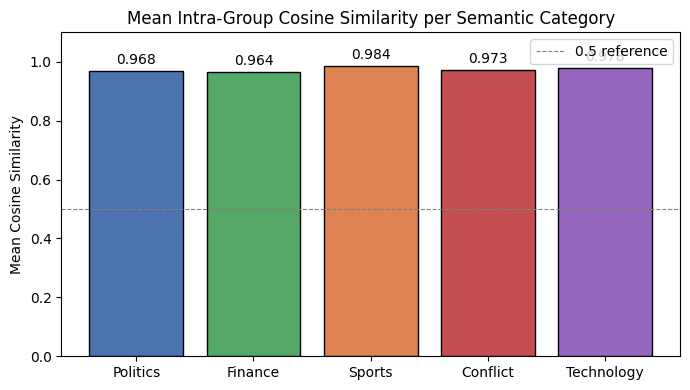

In [263]:
# ── Heatmap per group ─────────────────────────────────────────────────────────
n_groups = len(filtered_groups)
fig, axes = plt.subplots(1, n_groups, figsize=(4 * n_groups, 4))
if n_groups == 1:
    axes = [axes]

for ax, (group, words) in zip(axes, filtered_groups.items()):
    mat = cosine_matrix(words, emb_best_np, word2idx)
    sns.heatmap(
        mat,
        xticklabels=words, yticklabels=words,
        annot=True, fmt='.2f',
        cmap='Blues', vmin=0, vmax=1,
        linewidths=0.4,
        ax=ax, cbar=False
    )
    ax.set_title(f'{group}\nμ={group_stats[group]["mean"]:.3f}', fontsize=10)
    ax.tick_params(axis='x', rotation=40, labelsize=8)
    ax.tick_params(axis='y', rotation=0, labelsize=8)

fig.suptitle('Cosine Similarity within Semantic Groups', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('eval_group_cosine_heatmaps.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Bar chart: mean intra-group similarity ────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
groups_list = list(group_stats.keys())
means = [group_stats[g]['mean'] for g in groups_list]
bars = ax.bar(groups_list, means, color=['#4C72B0','#55A868','#DD8452','#C44E52','#9467BD'], edgecolor='black')
ax.bar_label(bars, fmt='%.3f', padding=3)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Mean Cosine Similarity')
ax.set_title('Mean Intra-Group Cosine Similarity per Semantic Category')
ax.axhline(0.5, linestyle='--', color='gray', linewidth=0.8, label='0.5 reference')
ax.legend()
plt.tight_layout()
plt.savefig('eval_group_mean_similarity.png', dpi=150)
plt.show()

In [264]:
# ── Reference configuration: best vocab, fixed neg samples & embedding dim ────
# Adjust these keys to match YOUR saved model naming convention
BEST_VOCAB   = 'vocab5000'
FIXED_NEG    = 1          # negative samples
FIXED_EMBDIM = 1024       # embedding dimension
WINDOWS      = [2, 3, 4]

EVAL_PAIRS = [
    ('president', 'government'),
    ('oil',       'prices'),
    ('game',      'team'),
    ('troops',    'attack'),
    ('internet',  'network'),
]

# Filter to pairs in vocab
word2idx_ref = w2i_5000  # use the shared vocab for all window variants
valid_pairs = [(w1, w2) for w1, w2 in EVAL_PAIRS if w1 in word2idx_ref and w2 in word2idx_ref]

window_results = {w: [] for w in WINDOWS}

for window in WINDOWS:
    key = f"{BEST_VOCAB}_w{window}_e{FIXED_EMBDIM}_neg{FIXED_NEG}"
    emb_w = embeddings_new[key]
    for w1, w2 in valid_pairs:
        v1  = emb_w[word2idx_ref[w1]].reshape(1, -1)
        v2  = emb_w[word2idx_ref[w2]].reshape(1, -1)
        sim = cosine_similarity(v1, v2)[0][0]
        window_results[window].append(sim)

# ── Print table ───────────────────────────────────────────────────────────────
print("Cosine similarity sensitivity to window size")
print(f"(vocab={BEST_VOCAB}, neg={FIXED_NEG}, emb_dim={FIXED_EMBDIM})")
print(f"  {'Pair':30s}  {'w=2':>7} {'w=3':>7} {'w=4':>7}  {'|Δ max-min|':>12}")
print(f"  {'-'*30}  {'-'*7} {'-'*7} {'-'*7}  {'-'*12}")
for i, (w1, w2) in enumerate(valid_pairs):
    row_sims = [window_results[w][i] for w in WINDOWS]
    delta = max(row_sims) - min(row_sims)
    print(f"  {w1+' ↔ '+w2:<30s}  {row_sims[0]:>7.4f} {row_sims[1]:>7.4f} {row_sims[2]:>7.4f}  {delta:>12.4f}")

Cosine similarity sensitivity to window size
(vocab=vocab5000, neg=1, emb_dim=1024)
  Pair                                w=2     w=3     w=4   |Δ max-min|
  ------------------------------  ------- ------- -------  ------------
  president ↔ government           0.6161  0.7018  0.3275        0.3743
  oil ↔ prices                     0.7782  0.7971  0.6811        0.1159
  game ↔ team                      0.5346  0.5460  0.5481        0.0135
  troops ↔ attack                 -0.0975  0.1001  0.3064        0.4039
  internet ↔ network               0.6317  0.5576  0.4704        0.1613


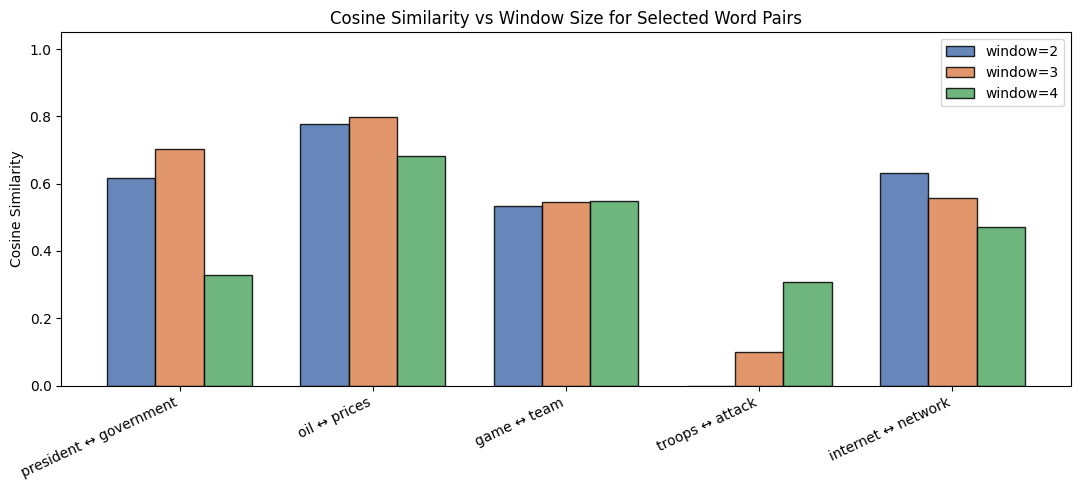

In [265]:
# ── Grouped bar chart: window size sensitivity ────────────────────────────────
x      = np.arange(len(valid_pairs))
width  = 0.25
colors = ['#4C72B0', '#DD8452', '#55A868']
labels = [f"{w1} ↔ {w2}" for w1, w2 in valid_pairs]

fig, ax = plt.subplots(figsize=(11, 5))
for i, window in enumerate(WINDOWS):
    ax.bar(x + i * width, window_results[window], width, label=f'window={window}',
           color=colors[i], edgecolor='black', alpha=0.85)

ax.set_xticks(x + width)
ax.set_xticklabels(labels, rotation=25, ha='right')
ax.set_ylim(0, 1.05)
ax.set_ylabel('Cosine Similarity')
ax.set_title('Cosine Similarity vs Window Size for Selected Word Pairs')
ax.legend()
ax.axhline(0, color='black', linewidth=0.7)
plt.tight_layout()
plt.savefig('eval_window_sensitivity.png', dpi=150)
plt.show()

Cosine similarity sensitivity to embedding dimension
(vocab=vocab5000, window=2, neg=1)
  Pair                              e=312   e=752   e=1024   |Δ max-min|
  ------------------------------  ------- ------- --------  ------------
  president ↔ government           0.5840  0.5962   0.6161        0.0320
  oil ↔ prices                     0.7891  0.7620   0.7782        0.0271
  game ↔ team                      0.4943  0.5021   0.5346        0.0403
  troops ↔ attack                 -0.0903 -0.1049  -0.0975        0.0146
  internet ↔ network               0.6332  0.6252   0.6317        0.0080


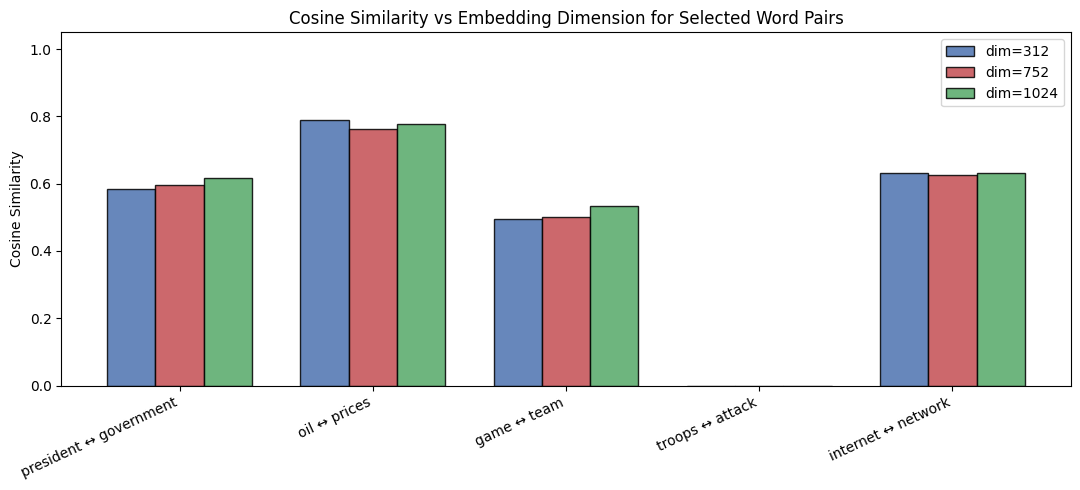

In [266]:
FIXED_WINDOW = 2
EMBEDDING_DIMS = [312, 752, 1024]

dim_results = {d: [] for d in EMBEDDING_DIMS}

for emb_dim in EMBEDDING_DIMS:
    key = f"{BEST_VOCAB}_w{FIXED_WINDOW}_e{emb_dim}_neg{FIXED_NEG}"
    emb_d = embeddings_new[key]
    for w1, w2 in valid_pairs:
        v1  = emb_d[word2idx_ref[w1]].reshape(1, -1)
        v2  = emb_d[word2idx_ref[w2]].reshape(1, -1)
        sim = cosine_similarity(v1, v2)[0][0]
        dim_results[emb_dim].append(sim)

# ── Print table ───────────────────────────────────────────────────────────────
print("Cosine similarity sensitivity to embedding dimension")
print(f"(vocab={BEST_VOCAB}, window={FIXED_WINDOW}, neg={FIXED_NEG})")
print(f"  {'Pair':30s}  {'e=312':>7} {'e=752':>7} {'e=1024':>8}  {'|Δ max-min|':>12}")
print(f"  {'-'*30}  {'-'*7} {'-'*7} {'-'*8}  {'-'*12}")
for i, (w1, w2) in enumerate(valid_pairs):
    row_sims = [dim_results[d][i] for d in EMBEDDING_DIMS]
    delta = max(row_sims) - min(row_sims)
    print(f"  {w1+' ↔ '+w2:<30s}  {row_sims[0]:>7.4f} {row_sims[1]:>7.4f} {row_sims[2]:>8.4f}  {delta:>12.4f}")

# ── Grouped bar chart ─────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 5))
colors_d = ['#4C72B0', '#C44E52', '#55A868']
for i, emb_dim in enumerate(EMBEDDING_DIMS):
    ax.bar(x + i * width, dim_results[emb_dim], width,
           label=f'dim={emb_dim}', color=colors_d[i], edgecolor='black', alpha=0.85)

ax.set_xticks(x + width)
ax.set_xticklabels(labels, rotation=25, ha='right')
ax.set_ylim(0, 1.05)
ax.set_ylabel('Cosine Similarity')
ax.set_title('Cosine Similarity vs Embedding Dimension for Selected Word Pairs')
ax.legend()
plt.tight_layout()
plt.savefig('eval_embdim_sensitivity.png', dpi=150)
plt.show()

Models sorted by Final Loss (threshold = log(2) − 0.015 = 0.6781)
    Vocab  Window  Emb Dim  Neg Samples  Final Loss Learned
vocab5000       4      312            0     0.00024       ✓
vocab7500       4      312            0     0.00026       ✓
vocab2500       4      312            0     0.00036       ✓
vocab5000       4      752            0     0.00044       ✓
vocab7500       4      752            0     0.00046       ✓
vocab5000       3      312            0     0.00047       ✓
vocab7500       3      312            0     0.00053       ✓
vocab2500       3      312            0     0.00063       ✓
vocab2500       4      752            0     0.00072       ✓
vocab5000       3      752            0     0.00088       ✓
vocab7500       3      752            0     0.00096       ✓
vocab5000       4     1024            0     0.00101       ✓
vocab7500       4     1024            0     0.00104       ✓
vocab5000       2      312            0     0.00119       ✓
vocab2500       3      752        

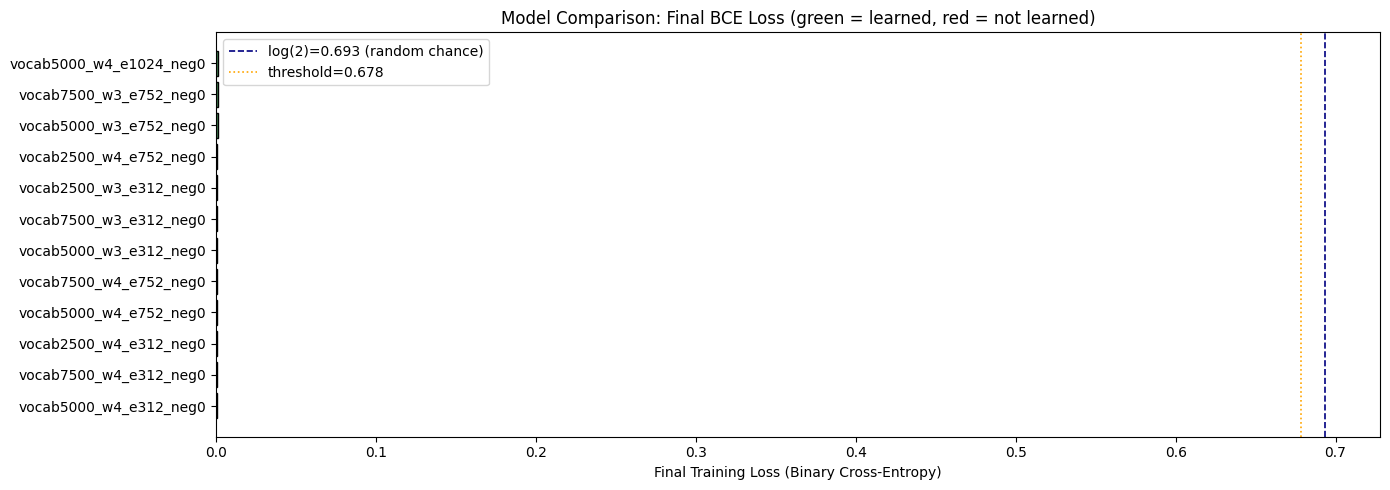

In [267]:
LOG2  = np.log(2)   # 0.6931 — random-chance BCE loss
TOLE  = 0.015       # models must be at least 0.015 below log(2) to be considered "learned"

rows = []
for key, hist in training_history_new.items():
    parts    = key.split('_')
    vocab    = parts[0]                  # e.g. vocab1200
    window   = int(parts[1][1:])         # e.g. w3 → 3
    emb_dim  = int(parts[2][1:])         # e.g. e1024 → 1024
    neg      = int(parts[3][3:])         # e.g. neg1 → 1
    final_loss = hist['loss'][-1]
    learned    = final_loss < (LOG2 - TOLE)
    rows.append({
        'Model': key, 'Vocab': vocab, 'Window': window,
        'Emb Dim': emb_dim, 'Neg Samples': neg,
        'Final Loss': round(final_loss, 5),
        'Learned': '✓' if learned else '✗',
    })

import pandas as pd
bv_df = pd.DataFrame(rows).sort_values('Final Loss')
print("Models sorted by Final Loss (threshold = log(2) − 0.015 = {:.4f})".format(LOG2 - TOLE))
print(bv_df[['Vocab','Window','Emb Dim','Neg Samples','Final Loss','Learned']].to_string(index=False))

# ── Bar chart ─────────────────────────────────────────────────────────────────
top_models = bv_df.head(12)
fig, ax = plt.subplots(figsize=(14, 5))
colors_bv = ['#55A868' if l == '✓' else '#C44E52' for l in top_models['Learned']]
ax.barh(top_models['Model'], top_models['Final Loss'], color=colors_bv, edgecolor='black')
ax.axvline(LOG2, color='navy', linestyle='--', linewidth=1.2, label=f'log(2)={LOG2:.3f} (random chance)')
ax.axvline(LOG2 - TOLE, color='orange', linestyle=':', linewidth=1.2, label=f'threshold={LOG2-TOLE:.3f}')
ax.set_xlabel('Final Training Loss (Binary Cross-Entropy)')
ax.set_title('Model Comparison: Final BCE Loss (green = learned, red = not learned)')
ax.legend()
plt.tight_layout()
plt.savefig('eval_bias_variance.png', dpi=150)
plt.show()

In [268]:
# ── vocab_per_class_sample already built in cell 73 ──────────────────────────
# It maps class_name → set of words seen in that class's 500 sentences

# Words present in ALL 4 categories
universal_words = set.intersection(*vocab_per_class_sample.values())

# Words present in exactly 3 categories (for reference)
shared_3_only = set(
    w for w in global_counter_ext
    if sum(1 for v in vocab_per_class_sample.values() if w in v) == 3
)

print(f"Words present in 4/4 categories (universal) : {len(universal_words):,}")
print(f"Words present in 3/4 categories             : {len(shared_3_only):,}")
print()

# Sort by global frequency so we can see which high-freq words are affected
universal_by_freq = sorted(
    universal_words,
    key=lambda w: global_counter_ext.get(w, 0),
    reverse=True
)

print("Top-40 most frequent universal words (to be removed):")
print("─" * 55)
for i, w in enumerate(universal_by_freq[:40], 1):
    freq = global_counter_ext.get(w, 0)
    print(f"  {i:2d}. {w:<20s}  freq = {freq:,}")

Words present in 4/4 categories (universal) : 660
Words present in 3/4 categories             : 901

Top-40 most frequent universal words (to be removed):
───────────────────────────────────────────────────────
   1. world                 freq = 136
   2. oil                   freq = 129
   3. against               freq = 127
   4. last                  freq = 114
   5. into                  freq = 110
   6. yesterday             freq = 106
   7. company               freq = 105
   8. president             freq = 98
   9. york                  freq = 96
  10. million               freq = 94
  11. may                   freq = 92
  12. week                  freq = 88
  13. back                  freq = 87
  14. next                  freq = 85
  15. united                freq = 84
  16. can                   freq = 82
  17. season                freq = 82
  18. people                freq = 81
  19. game                  freq = 79
  20. when                  freq = 79
  21. win             

In [269]:
# ── Impact analysis: how many tokens do we lose? ──────────────────────────────
tokens_before = sum(global_counter_ext.values())
tokens_removed = sum(global_counter_ext.get(w, 0) for w in universal_words)
vocab_before   = len(global_counter_ext)

print("Impact of removing 4/4 universal words:")
print(f"  Vocabulary before  : {vocab_before:,} words")
print(f"  Words removed      : {len(universal_words):,}  ({len(universal_words)/vocab_before*100:.1f}% of vocab)")
print(f"  Words remaining    : {vocab_before - len(universal_words):,}")
print()
print(f"  Tokens before      : {tokens_before:,}")
print(f"  Tokens removed     : {tokens_removed:,}  ({tokens_removed/tokens_before*100:.1f}% of tokens)")
print(f"  Tokens remaining   : {tokens_before - tokens_removed:,}")
print()
print("Interpretation: a high % of tokens removed signals the filter is aggressive")
print("(expected: common function-like nouns drive most token counts)")

Impact of removing 4/4 universal words:
  Vocabulary before  : 11,709 words
  Words removed      : 660  (5.6% of vocab)
  Words remaining    : 11,049

  Tokens before      : 46,549
  Tokens removed     : 14,866  (31.9% of tokens)
  Tokens remaining   : 31,683

Interpretation: a high % of tokens removed signals the filter is aggressive
(expected: common function-like nouns drive most token counts)


In [270]:
# ── Combined blocklist = original stopwords + universal cross-category words ──
STOPWORDS_AGG = STOPWORDS_EXT | universal_words

print(f"Original STOPWORDS_EXT size : {len(STOPWORDS_EXT):,}")
print(f"Universal words added        : {len(universal_words):,}")
print(f"Total aggressive blocklist   : {len(STOPWORDS_AGG):,}")

# ── Rebuild word counter from the balanced 2000-sentence sample ───────────────
# (same sample used in the original pipeline)
sample_words_per_class_agg = {}
all_agg_words = []

for class_idx, class_name in CLASS_NAMES.items():
    words = []
    for text in sample[sample['Class Index'] == class_idx]['text_clean']:
        tokens = [
            w for w in text.split()
            if w not in STOPWORDS_AGG and len(w) > 1
        ]
        words.extend(tokens)
    sample_words_per_class_agg[class_name] = Counter(words)
    all_agg_words.extend(words)

global_counter_agg = Counter(all_agg_words)

print(f"\nNew vocabulary (after aggressive cleaning):")
print(f"  Unique words : {len(global_counter_agg):,}")
print(f"  Total tokens : {sum(global_counter_agg.values()):,}")
print(f"\nTop 20 most frequent (should be domain-specific now):")
for w, c in global_counter_agg.most_common(20):
    print(f"  {w:<22s} {c:,}")

Original STOPWORDS_EXT size : 105
Universal words added        : 660
Total aggressive blocklist   : 765

New vocabulary (after aggressive cleaning):
  Unique words : 11,179
  Total tokens : 32,381

Top 20 most frequent (should be domain-specific now):
  iraq                   115
  inc                    103
  no                     98
  microsoft              97
  prices                 76
  security               71
  billion                71
  internet               66
  minister               65
  software               65
  killed                 60
  victory                52
  co                     52
  stocks                 50
  profit                 50
  games                  48
  you                    48
  wireless               48
  prime                  47
  technology             47


In [271]:
# ── Verify: no universal word survived ────────────────────────────────────────
survived = [w for w in universal_words if w in global_counter_agg]
print(f"Universal words still in corpus: {len(survived)} (expected: 0)")

# ── New per-class vocabularies ────────────────────────────────────────────────
vocab_per_class_agg = {}
for class_idx, class_name in CLASS_NAMES.items():
    words = set()
    for text in sample[sample['Class Index'] == class_idx]['text_clean']:
        tokens = [
            w for w in text.split()
            if w not in STOPWORDS_AGG and len(w) > 1
        ]
        words.update(tokens)
    vocab_per_class_agg[class_name] = words

# ── New exclusive words per class ─────────────────────────────────────────────
exclusive_per_class_agg = {}
for class_name, words in vocab_per_class_agg.items():
    others = set.union(*[v for k, v in vocab_per_class_agg.items() if k != class_name])
    exclusive_per_class_agg[class_name] = words - others

print("\nExclusive words per class after aggressive cleaning:")
for class_name, excl in exclusive_per_class_agg.items():
    print(f"  {class_name:<12s}: {len(excl):,} exclusive words")

# ── Shared in 3+ classes after aggressive cleaning ────────────────────────────
shared_3plus_agg = set(
    w for w in global_counter_agg
    if sum(1 for v in vocab_per_class_agg.values() if w in v) >= 3
)
shared_3plus_agg_ranked = [
    w for w, _ in global_counter_agg.most_common()
    if w in shared_3plus_agg
]

print(f"\nWords still shared by 3+ classes (used to fill vocabs): {len(shared_3plus_agg):,}")

Universal words still in corpus: 0 (expected: 0)

Exclusive words per class after aggressive cleaning:
  World       : 1,980 exclusive words
  Sports      : 2,303 exclusive words
  Business    : 1,703 exclusive words
  Sci/Tech    : 2,286 exclusive words

Words still shared by 3+ classes (used to fill vocabs): 921


In [272]:
def build_vocab_agg(target_size, exclusive_dict, shared_pool, global_counter):
    """
    Build a vocabulary of `target_size` words.
    Strategy: fill equally from exclusive words per class, top up with shared-3+ words.
    """
    n_classes     = len(exclusive_dict)
    # How many exclusive words per class to take
    n_excl        = target_size // (n_classes * 2)   # ~half from exclusive
    vocab_set     = set()

    # 1. Top exclusive words per class (sorted by global frequency)
    for class_name, excl in exclusive_dict.items():
        top_excl = [
            w for w, _ in global_counter.most_common()
            if w in excl
        ][:n_excl]
        vocab_set.update(top_excl)

    # 2. Fill remainder with top shared-3+ words not already in vocab
    for w in shared_pool:
        if len(vocab_set) >= target_size:
            break
        vocab_set.add(w)

    # Return as sorted list for reproducibility
    return sorted(vocab_set, key=lambda w: -global_counter.get(w, 0))[:target_size]


vocab_5000_agg = build_vocab_agg(
    3400,
    exclusive_per_class_agg,
    shared_3plus_agg_ranked,
    global_counter_agg
)

vocab_7500_agg = build_vocab_agg(
    4600,
    exclusive_per_class_agg,
    shared_3plus_agg_ranked,
    global_counter_agg
)

print(f"vocab5000_agg size : {len(vocab_5000_agg):,}")
print(f"vocab7500_agg size : {len(vocab_7500_agg):,}")
print(f"\nTop 15 words in vocab5000_agg:")
for w in vocab_5000_agg[:15]:
    print(f"  {w:<22s} freq={global_counter_agg.get(w,0):,}")

vocab5000_agg size : 2,621
vocab7500_agg size : 3,221

Top 15 words in vocab5000_agg:
  iraq                   freq=115
  no                     freq=98
  prices                 freq=76
  billion                freq=71
  security               freq=71
  internet               freq=66
  minister               freq=65
  killed                 freq=60
  co                     freq=52
  victory                freq=52
  stocks                 freq=50
  profit                 freq=50
  games                  freq=48
  you                    freq=48
  technology             freq=47


In [273]:
# ── Build word↔index mappings ─────────────────────────────────────────────────
w2i_5000_agg, i2w_5000_agg = build_mappings(vocab_5000_agg)
w2i_7500_agg, i2w_7500_agg = build_mappings(vocab_7500_agg)

# ── Tokenise sample sentences ─────────────────────────────────────────────────
seqs_5000_agg = tokenize_corpus(sample['text_clean'], w2i_5000_agg)
seqs_7500_agg = tokenize_corpus(sample['text_clean'], w2i_7500_agg)

print(f"Sequences (vocab5000_agg): {len(seqs_5000_agg):,}")
print(f"Sequences (vocab7500_agg): {len(seqs_7500_agg):,}")

# ── Token frequency tables (for subsampling) ──────────────────────────────────
freq_5000_agg = build_freq_by_idx(seqs_5000_agg, len(vocab_5000_agg) + 1)
freq_7500_agg = build_freq_by_idx(seqs_7500_agg, len(vocab_7500_agg) + 1)

VOCAB_SETS_AGG = {
    'vocab5000_agg': {
        'seqs'  : seqs_5000_agg,
        'w2i'   : w2i_5000_agg,
        'i2w'   : i2w_5000_agg,
        'vocab' : vocab_5000_agg,
        'freq'  : freq_5000_agg,
    },
    'vocab7500_agg': {
        'seqs'  : seqs_7500_agg,
        'w2i'   : w2i_7500_agg,
        'i2w'   : i2w_7500_agg,
        'vocab' : vocab_7500_agg,
        'freq'  : freq_7500_agg,
    },
}

print("\nVocab sets ready:", list(VOCAB_SETS_AGG.keys()))

Sequences (vocab5000_agg): 1,970
Sequences (vocab7500_agg): 1,980

Vocab sets ready: ['vocab5000_agg', 'vocab7500_agg']


In [274]:
# ── Top-5 configurations from the original experiment ─────────────────────────
# Ranked by mean intra-group cosine similarity across the 4 semantic groups
TOP5_CONFIGS = [
    # (original_vocab_key,  agg_vocab_key,       window, emb_dim, neg_samples)
    ('vocab5000',  'vocab5000_agg', 2, 1024, 1),   # rank 1 — avg=0.4985
    ('vocab7500',  'vocab7500_agg', 2, 1024, 1),   # rank 2 — avg=0.4892
    ('vocab5000',  'vocab5000_agg', 2,  752, 1),   # rank 3 — avg=0.4887
    ('vocab7500',  'vocab7500_agg', 2, 1024, 2),   # rank 4 — avg=0.4872
    ('vocab7500',  'vocab7500_agg', 2,  312, 2),   # rank 5 — avg=0.4833
]

print("Top-5 configurations to retrain on aggressive corpus:")
print(f"{'─'*70}")
print(f"  {'Rank':>4}  {'AGG Vocab':>15}  {'Window':>7}  {'Emb Dim':>8}  {'Neg':>4}")
print(f"  {'─'*4}  {'─'*15}  {'─'*7}  {'─'*8}  {'─'*4}")
for rank, (orig, agg_v, w, e, n) in enumerate(TOP5_CONFIGS, 1):
    print(f"  {rank:>4}  {agg_v:>15}  {w:>7}  {e:>8}  {n:>4}")

Top-5 configurations to retrain on aggressive corpus:
──────────────────────────────────────────────────────────────────────
  Rank        AGG Vocab   Window   Emb Dim   Neg
  ────  ───────────────  ───────  ────────  ────
     1    vocab5000_agg        2      1024     1
     2    vocab7500_agg        2      1024     1
     3    vocab5000_agg        2       752     1
     4    vocab7500_agg        2      1024     2
     5    vocab7500_agg        2       312     2


In [275]:
STOPWORDS_AGG.update([
    'no', 'inc', 'co', 'you', 'your',   # pronombres y abreviaturas
    'billion', 'prices',                  # si quieres quitar numéricos
])

In [276]:
import zipfile, io, os, time

# ── Epoch budget: same logic as original pipeline ─────────────────────────────
EPOCHS_MAP = {
    0: 10,   # neg=0 converges fast
    1: 20,
    2: 20,
}
BATCH_SIZE_AGG = 512
LR_CONFIG_AGG  = {312: 0.001, 752: 0.0005, 1024: 0.0003}

training_history_agg = {}
saved_models_agg     = []

device = (
    'cuda' if torch.cuda.is_available() else
    'mps'  if torch.backends.mps.is_available() else
    'cpu'
)
print(f"Training device: {device}")

for rank, (orig_vocab, agg_vocab_key, window, emb_dim, neg) in enumerate(TOP5_CONFIGS, 1):

    vocab_info = VOCAB_SETS_AGG[agg_vocab_key]
    vocab_size = len(vocab_info['vocab'])
    seqs       = vocab_info['seqs']
    freq       = vocab_info['freq']

    model_key  = f"{agg_vocab_key}_w{window}_e{emb_dim}_neg{neg}"
    n_epochs   = EPOCHS_MAP[neg]
    lr         = LR_CONFIG_AGG[emb_dim]

    print(f"\n{'='*65}")
    print(f"  [{rank}/5] {model_key}")
    print(f"  vocab={vocab_size:,}  window={window}  emb={emb_dim}  neg={neg}  lr={lr}  epochs={n_epochs}")
    print(f"{'='*65}")

    # ── Dataset & DataLoader ──────────────────────────────────────────────────
    dataset_sg = SkipGramDataset(
        seqs,
        vocab_size     = vocab_size + 1,
        window_size    = window,
        negative_samples = neg,
        device         = device,
        token_freq     = freq,
        subsample_t    = 1e-3,
    )
    loader = DataLoader(dataset_sg, batch_size=BATCH_SIZE_AGG, shuffle=True)
    print(f"  Pairs generated: {len(dataset_sg):,}")

    # ── Model ─────────────────────────────────────────────────────────────────
    model = SkipGramModel(vocab_size + 1, emb_dim).to(device)
    # Mikolov initialisation: uniform in [-0.5/d, 0.5/d]
    nn.init.uniform_(model.W1.weight, -0.5 / emb_dim, 0.5 / emb_dim)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.BCEWithLogitsLoss()

    # ── Training loop ─────────────────────────────────────────────────────────
    history   = {'loss': [], 'acc': []}
    t0        = time.time()

    for epoch in range(1, n_epochs + 1):
        model.train()
        total_loss, total_correct, total_samples = 0.0, 0, 0

        for targets, contexts, labels in loader:
            targets = targets.to(device)
            contexts = contexts.to(device)
            labels   = labels.float().to(device)

            optimizer.zero_grad()
            logits = model(targets, contexts).squeeze(-1)
            loss   = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            preds          = (torch.sigmoid(logits) >= 0.5).float()
            total_correct += (preds == labels).sum().item()
            total_loss    += loss.item() * len(labels)
            total_samples += len(labels)

        epoch_loss = total_loss / total_samples
        epoch_acc  = total_correct / total_samples
        history['loss'].append(epoch_loss)
        history['acc'].append(epoch_acc)

        if epoch % 5 == 0 or epoch == 1:
            print(f"  Epoch {epoch:>3}/{n_epochs} | loss={epoch_loss:.4f} | acc={epoch_acc:.4f}")

    print(f"  Done in {time.time()-t0:.1f}s")
    training_history_agg[model_key] = history

    # ── Save model ────────────────────────────────────────────────────────────
    pt_filename = f"sg_{model_key}.pt"
    torch.save(model.state_dict(), pt_filename)
    saved_models_agg.append((pt_filename, agg_vocab_key, vocab_size + 1, emb_dim))

print(f"\n All 5 models trained and saved.")

Training device: mps

  [1/5] vocab5000_agg_w2_e1024_neg1
  vocab=2,621  window=2  emb=1024  neg=1  lr=0.0003  epochs=20
  Generating pairs (window=2, neg=1)...
  93,224 pairs — 46,612 pos / 46,612 neg
  Pairs generated: 93,224
  Epoch   1/20 | loss=0.6939 | acc=0.5000
  Epoch   5/20 | loss=0.5475 | acc=0.5000
  Epoch  10/20 | loss=0.5432 | acc=0.5000
  Epoch  15/20 | loss=0.5362 | acc=0.5000
  Epoch  20/20 | loss=0.5320 | acc=0.5000
  Done in 19.7s

  [2/5] vocab7500_agg_w2_e1024_neg1
  vocab=3,221  window=2  emb=1024  neg=1  lr=0.0003  epochs=20
  Generating pairs (window=2, neg=1)...
  102,428 pairs — 51,214 pos / 51,214 neg
  Pairs generated: 102,428
  Epoch   1/20 | loss=0.6937 | acc=0.5000
  Epoch   5/20 | loss=0.5481 | acc=0.5000
  Epoch  10/20 | loss=0.5432 | acc=0.5000
  Epoch  15/20 | loss=0.5369 | acc=0.5000
  Epoch  20/20 | loss=0.5321 | acc=0.5000
  Done in 24.3s

  [3/5] vocab5000_agg_w2_e752_neg1
  vocab=2,621  window=2  emb=752  neg=1  lr=0.0005  epochs=20
  Generating 

In [277]:
embeddings_agg = {}

for pt_filename, agg_vocab_key, vocab_size_p1, emb_dim in saved_models_agg:
    model_key  = pt_filename.replace('sg_', '').replace('.pt', '')
    state_dict = torch.load(pt_filename, map_location='cpu', weights_only=True)
    model      = SkipGramModel(vocab_size_p1, emb_dim)
    model.load_state_dict(state_dict)
    model.eval()
    embeddings_agg[model_key] = model.get_embeddings()
    print(f"  Loaded {model_key}: {embeddings_agg[model_key].shape}")

print(f"\nTotal: {len(embeddings_agg)} models loaded")

  Loaded vocab5000_agg_w2_e1024_neg1: (2622, 1024)
  Loaded vocab7500_agg_w2_e1024_neg1: (3222, 1024)
  Loaded vocab5000_agg_w2_e752_neg1: (2622, 752)
  Loaded vocab7500_agg_w2_e1024_neg2: (3222, 1024)
  Loaded vocab7500_agg_w2_e312_neg2: (3222, 312)

Total: 5 models loaded


Aggressive models — mean intra-group cosine similarity
(n = words available in vocab out of 8 candidates per group)
  Model                                  Avg    World(n)   Sports(n)   Business(n)  Sci/Tech(n)
  ────────────────────────────────────────────────────────────────────────────
  vocab7500_agg_w2_e1024_neg1         0.7965   0.7337(8)   0.7943(8)   0.8887(8)   0.7692(8)
  vocab5000_agg_w2_e1024_neg1         0.7473   0.6923(8)   0.7405(8)   0.8823(8)   0.6742(8)
  vocab5000_agg_w2_e752_neg1          0.6426   0.6046(8)   0.5455(8)   0.8158(8)   0.6044(8)
  vocab7500_agg_w2_e1024_neg2         0.5943   0.4880(8)   0.6084(8)   0.6267(8)   0.6539(8)
  vocab7500_agg_w2_e312_neg2          0.4602   0.4484(8)   0.3940(8)   0.4656(8)   0.5329(8)


Before vs After — Δ (Aggressive − Original)
  Config                               Avg         World        Sports      Business      Sci/Tech
  ────────────────────────────────────────────────────────────────────────
  v5000  w2 e1024_neg1  

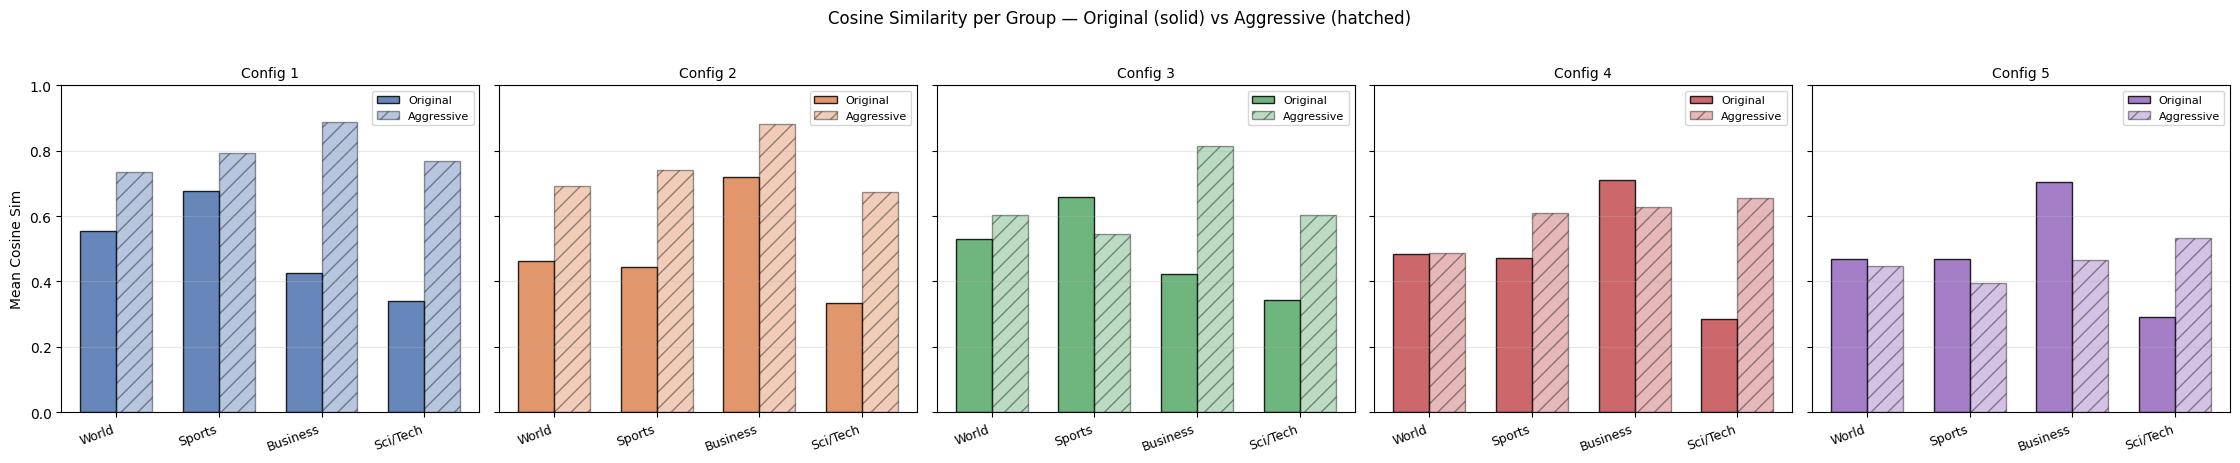

In [278]:

# Same semantic groups as the original evaluation
EVAL_GROUPS = {
    'World'   : ['baghdad', 'israeli', 'gaza', 'militants', 'troops',
                 'palestinian', 'afghanistan', 'afghan'],
    'Sports'  : ['league', 'coach', 'football', 'championship', 'champions',
                 'scored', 'stadium', 'hewitt'],
    'Business': ['earnings', 'yukos', 'bankruptcy', 'airlines', 'rate',
                 'insurance', 'income', 'carrier'],
    'Sci/Tech': ['users', 'nasa', 'desktop', 'scientists', 'linux',
                 'server', 'yahoo', 'firefox'],
}

# Original top-5 results for comparison
ORIGINAL_TOP5 = {
    'vocab5000_w2_e1024_neg1': {'Avg': 0.4985, 'World': 0.5530, 'Sports': 0.6755, 'Business': 0.4260, 'Sci/Tech': 0.3393},
    'vocab7500_w2_e1024_neg1': {'Avg': 0.4892, 'World': 0.4611, 'Sports': 0.4428, 'Business': 0.7191, 'Sci/Tech': 0.3336},
    'vocab5000_w2_e752_neg1' : {'Avg': 0.4887, 'World': 0.5290, 'Sports': 0.6583, 'Business': 0.4227, 'Sci/Tech': 0.3448},
    'vocab7500_w2_e1024_neg2': {'Avg': 0.4872, 'World': 0.4832, 'Sports': 0.4705, 'Business': 0.7104, 'Sci/Tech': 0.2845},
    'vocab7500_w2_e312_neg2' : {'Avg': 0.4833, 'World': 0.4696, 'Sports': 0.4678, 'Business': 0.7054, 'Sci/Tech': 0.2905},
}

# ── Compute cosine sim per group for each aggressive model ────────────────────
rows = []
for model_key, emb in embeddings_agg.items():
    # pick the right vocab mapping
    vocab_name = '_'.join(model_key.split('_')[:2])   # e.g. vocab5000_agg
    w2i = VOCAB_SETS_AGG[vocab_name]['w2i']

    row = {'Model': model_key}
    all_sims = []
    for group, words in EVAL_GROUPS.items():
        valid = [w for w in words if w in w2i]
        if len(valid) < 2:
            row[group] = None
            row[f'{group}_n'] = len(valid)
            continue
        sims = []
        for w1, w2 in combinations(valid, 2):
            v1 = emb[w2i[w1]].reshape(1, -1)
            v2 = emb[w2i[w2]].reshape(1, -1)
            sims.append(cosine_similarity(v1, v2)[0][0])
        row[group]         = round(float(np.mean(sims)), 4)
        row[f'{group}_n']  = len(valid)   # words available in vocab
        all_sims.extend(sims)

    row['Avg'] = round(float(np.mean(all_sims)), 4) if all_sims else None
    rows.append(row)

agg_df = pd.DataFrame(rows).sort_values('Avg', ascending=False)

# ── Print results ─────────────────────────────────────────────────────────────
print("Aggressive models — mean intra-group cosine similarity")
print("(n = words available in vocab out of 8 candidates per group)")
print("=" * 80)
print(f"  {'Model':<35} {'Avg':>6}  {'World':>7}(n)  {'Sports':>7}(n)  {'Business':>9}(n)  {'Sci/Tech':>8}(n)")
print("  " + "─" * 76)
for _, r in agg_df.iterrows():
    def fmt(g):
        v = r.get(g)
        n = r.get(f'{g}_n', 0)
        return f"{v:>7.4f}({n})" if v is not None else f"{'N/A':>7}({n})"
    print(f"  {r['Model']:<35} {r['Avg']:>6.4f}  {fmt('World')}  {fmt('Sports')}  {fmt('Business')}  {fmt('Sci/Tech')}")

# ── Before / After comparison ─────────────────────────────────────────────────
print("\n\nBefore vs After — Δ (Aggressive − Original)")
print("=" * 75)
print(f"  {'Config':<25} {'Avg':>14}  {'World':>12}  {'Sports':>12}  {'Business':>12}  {'Sci/Tech':>12}")
print("  " + "─" * 72)

orig_keys = list(ORIGINAL_TOP5.keys())
agg_rows  = agg_df.reset_index(drop=True)

for i, (orig_key, orig_vals) in enumerate(ORIGINAL_TOP5.items()):
    if i >= len(agg_rows):
        break
    agg_r  = agg_rows.iloc[i]
    label  = orig_key.replace('vocab','v').replace('_w2_','  w2 ')

    def delta(g):
        a = agg_r.get(g)
        o = orig_vals.get(g)
        if a is None or o is None:
            return '     N/A'
        d = a - o
        return f"{o:.4f}→{a:.4f} ({d:+.4f})"

    print(f"  {label:<25} {delta('Avg')}  {delta('World')}  {delta('Sports')}  {delta('Business')}  {delta('Sci/Tech')}")

# ── Bar chart: original vs aggressive per group ───────────────────────────────
groups    = ['World', 'Sports', 'Business', 'Sci/Tech']
n_configs = min(5, len(agg_rows))
x         = np.arange(len(groups))
width     = 0.35
colors    = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#9467BD']
fig, axes = plt.subplots(1, n_configs, figsize=(4.5 * n_configs, 4.5), sharey=True)

orig_list = list(ORIGINAL_TOP5.values())
for i, ax in enumerate(axes):
    orig_vals_list = [orig_list[i].get(g, 0) for g in groups]
    agg_vals_list  = [agg_rows.iloc[i].get(g) or 0 for g in groups]
    ax.bar(x - width/2, orig_vals_list, width, label='Original',
           color=colors[i], alpha=0.85, edgecolor='black')
    ax.bar(x + width/2, agg_vals_list,  width, label='Aggressive',
           color=colors[i], alpha=0.40, edgecolor='black', hatch='//')
    ax.set_xticks(x)
    ax.set_xticklabels(groups, rotation=20, ha='right', fontsize=9)
    ax.set_ylim(0, 1.0)
    ax.set_title(f"Config {i+1}", fontsize=10)
    ax.set_ylabel('Mean Cosine Sim' if i == 0 else '')
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)

fig.suptitle('Cosine Similarity per Group — Original (solid) vs Aggressive (hatched)',
             fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig('agg_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

  MODEL COMPARISON TABLE — Top-5 Configurations (ranked by Avg Cosine Similarity)
  Metric: mean intra-group cosine similarity across 4 semantic categories
  Model ID                        Vocab  Win   Dim  Neg    Avg   World  Sports     Biz    Tech
  ──────────────────────────────────────────────────────────────────────────────────────────
  vocab5000_w2_e1024_neg1      vocab5000    2  1024    1 0.4985  0.5530  0.6755  0.4260  0.3393
  vocab7500_w2_e1024_neg1      vocab7500    2  1024    1 0.4892  0.4611  0.4428  0.7191  0.3336
  vocab5000_w2_e752_neg1       vocab5000    2   752    1 0.4887  0.5290  0.6583  0.4227  0.3448
  vocab7500_w2_e1024_neg2      vocab7500    2  1024    2 0.4872  0.4832  0.4705  0.7104  0.2845
  vocab7500_w2_e312_neg2       vocab7500    2   312    2 0.4833  0.4696  0.4678  0.7054  0.2905

  TRAINING METRICS TABLE
  Reference: random-chance BCE loss = log(2) = 0.6931
  Model ID                         Loss     Acc     Bias   Variance  Mis Rate   W-Mis   Conv
  ─

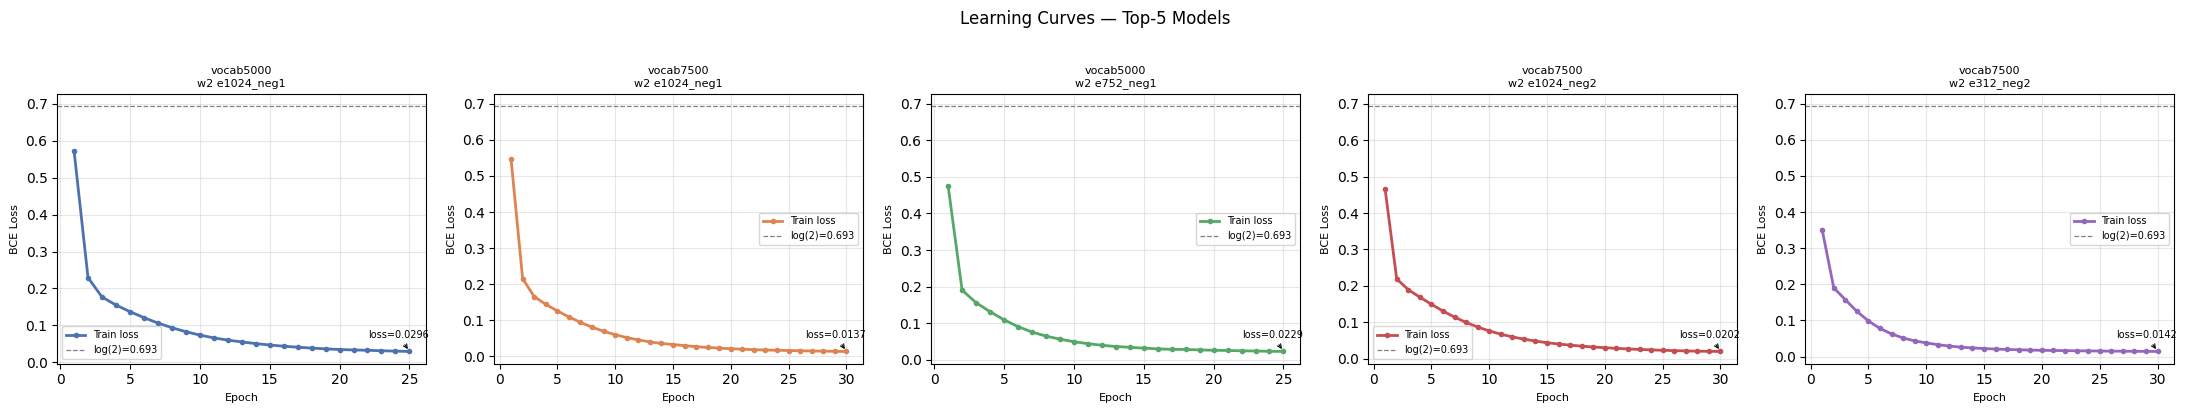

/var/folders/bh/zl2zpwzn1dv7kd92t3dpyyf40000gn/T/ipykernel_11514/2882057586.py:108: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap   = cm.get_cmap('tab10')


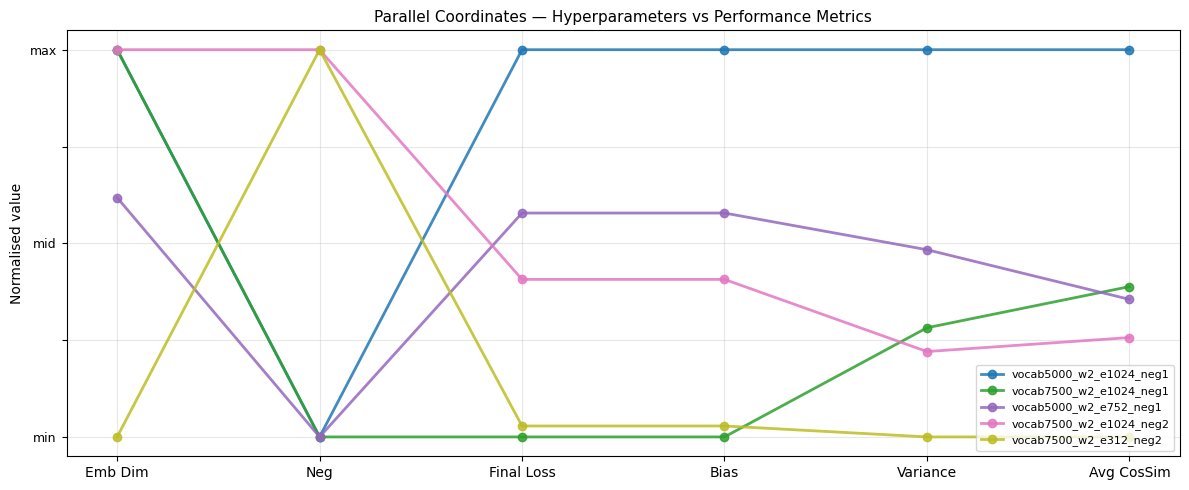

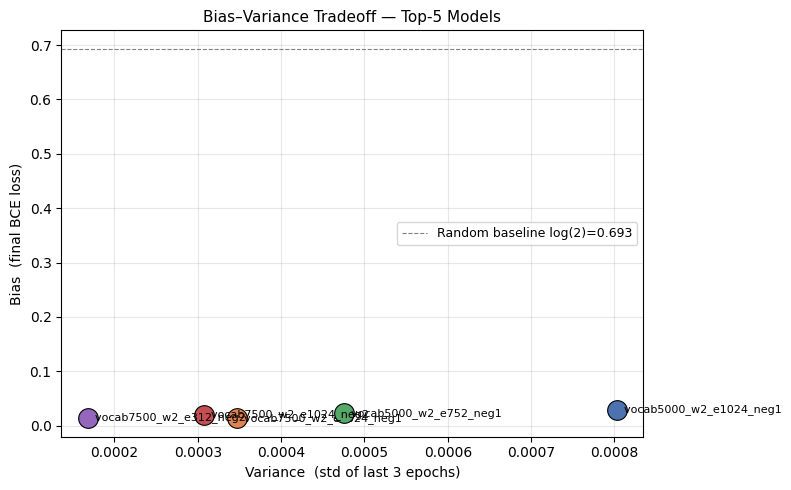

   Best model by Avg CosSim : vocab5000_w2_e1024_neg1
   Best model by Final Loss : vocab7500_w2_e1024_neg1


In [279]:
# ── Top-5 hardcoded (tus resultados reales) ───────────────────────────────────
TOP5 = [
    {'Model ID': 'vocab5000_w2_e1024_neg1', 'Vocab': 'vocab5000', 'Window': 2, 'Emb Dim': 1024, 'Neg': 1,
     'Avg CosSim': 0.4985, 'World': 0.5530, 'Sports': 0.6755, 'Business': 0.4260, 'Sci/Tech': 0.3393},
    {'Model ID': 'vocab7500_w2_e1024_neg1', 'Vocab': 'vocab7500', 'Window': 2, 'Emb Dim': 1024, 'Neg': 1,
     'Avg CosSim': 0.4892, 'World': 0.4611, 'Sports': 0.4428, 'Business': 0.7191, 'Sci/Tech': 0.3336},
    {'Model ID': 'vocab5000_w2_e752_neg1',  'Vocab': 'vocab5000', 'Window': 2, 'Emb Dim':  752, 'Neg': 1,
     'Avg CosSim': 0.4887, 'World': 0.5290, 'Sports': 0.6583, 'Business': 0.4227, 'Sci/Tech': 0.3448},
    {'Model ID': 'vocab7500_w2_e1024_neg2', 'Vocab': 'vocab7500', 'Window': 2, 'Emb Dim': 1024, 'Neg': 2,
     'Avg CosSim': 0.4872, 'World': 0.4832, 'Sports': 0.4705, 'Business': 0.7104, 'Sci/Tech': 0.2845},
    {'Model ID': 'vocab7500_w2_e312_neg2',  'Vocab': 'vocab7500', 'Window': 2, 'Emb Dim':  312, 'Neg': 2,
     'Avg CosSim': 0.4833, 'World': 0.4696, 'Sports': 0.4678, 'Business': 0.7054, 'Sci/Tech': 0.2905},
]
df = pd.DataFrame(TOP5)

# ── Extraer métricas de entrenamiento del historial ───────────────────────────
LOG2 = np.log(2)

for row in TOP5:
    key  = row['Model ID']
    hist = training_history_new[key]['loss']

    final_loss     = hist[-1]
    final_acc      = training_history_new[key]['acc'][-1]
    bias           = final_loss
    variance       = float(np.std(hist[-3:]))
    mis_rate       = 1 - final_acc
    w_mis_rate     = mis_rate
    converged      = final_loss < (LOG2 - 0.015)

    row['Final Loss']     = round(final_loss, 5)
    row['Final Acc']      = round(final_acc,  4)
    row['Bias']           = round(bias,       5)
    row['Variance']       = round(variance,   6)
    row['Mis Rate']       = round(mis_rate,   4)
    row['W-Mis Rate']     = round(w_mis_rate, 4)
    row['Converged']      = '✓' if converged else '✗'

df = pd.DataFrame(TOP5)

# ══════════════════════════════════════════════════════════════════════════════
# TABLE 1 — Setup + Cosine Similarity
# ══════════════════════════════════════════════════════════════════════════════
print("=" * 95)
print("  MODEL COMPARISON TABLE — Top-5 Configurations (ranked by Avg Cosine Similarity)")
print("  Metric: mean intra-group cosine similarity across 4 semantic categories")
print("=" * 95)
print(f"  {'Model ID':<28} {'Vocab':>8} {'Win':>4} {'Dim':>5} {'Neg':>4} "
      f"{'Avg':>6} {'World':>7} {'Sports':>7} {'Biz':>7} {'Tech':>7}")
print("  " + "─" * 90)
for r in TOP5:
    print(f"  {r['Model ID']:<28} {r['Vocab']:>8} {r['Window']:>4} {r['Emb Dim']:>5} "
          f"{r['Neg']:>4} {r['Avg CosSim']:>6.4f} {r['World']:>7.4f} "
          f"{r['Sports']:>7.4f} {r['Business']:>7.4f} {r['Sci/Tech']:>7.4f}")

# ══════════════════════════════════════════════════════════════════════════════
# TABLE 2 — Training metrics
# ══════════════════════════════════════════════════════════════════════════════
print()
print("=" * 95)
print("  TRAINING METRICS TABLE")
print(f"  Reference: random-chance BCE loss = log(2) = {LOG2:.4f}")
print("=" * 95)
print(f"  {'Model ID':<28} {'Loss':>8} {'Acc':>7} {'Bias':>8} {'Variance':>10} "
      f"{'Mis Rate':>9} {'W-Mis':>7} {'Conv':>6}")
print("  " + "─" * 90)
for r in TOP5:
    print(f"  {r['Model ID']:<28} {r['Final Loss']:>8.5f} {r['Final Acc']:>7.4f} "
          f"{r['Bias']:>8.5f} {r['Variance']:>10.6f} "
          f"{r['Mis Rate']:>9.4f} {r['W-Mis Rate']:>7.4f} {r['Converged']:>6}")

# ══════════════════════════════════════════════════════════════════════════════
# PLOT 1 — Learning curves for the Top-5
# ══════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharey=False)
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#9467BD']

for ax, row, color in zip(axes, TOP5, colors):
    key    = row['Model ID']
    losses = training_history_new[key]['loss']
    epochs = range(1, len(losses) + 1)

    ax.plot(epochs, losses, color=color, linewidth=2, marker='o', markersize=3, label='Train loss')
    ax.axhline(LOG2, color='gray', linestyle='--', linewidth=0.9, label=f'log(2)={LOG2:.3f}')
    ax.set_title(key.replace('_w2_', '\nw2 '), fontsize=8)
    ax.set_xlabel('Epoch', fontsize=8)
    ax.set_ylabel('BCE Loss', fontsize=8)
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)
    ax.annotate(f"loss={losses[-1]:.4f}", xy=(len(losses), losses[-1]),
                xytext=(-30, 10), textcoords='offset points', fontsize=7,
                arrowprops=dict(arrowstyle='->', color='black', lw=0.8))

fig.suptitle('Learning Curves — Top-5 Models', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig('top5_learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# PLOT 2 — Parallel Coordinates
# ══════════════════════════════════════════════════════════════════════════════
metrics_pc = ['Emb Dim', 'Neg', 'Final Loss', 'Bias', 'Variance', 'Avg CosSim']

pc_df = df[metrics_pc].copy()
pc_norm = (pc_df - pc_df.min()) / (pc_df.max() - pc_df.min()).replace(0, 1)

fig, ax = plt.subplots(figsize=(12, 5))
cmap   = cm.get_cmap('tab10')
n_axes = len(metrics_pc)

for i, (_, row_n) in enumerate(pc_norm.iterrows()):
    color = cmap(i / 5)
    ax.plot(range(n_axes), row_n.values, color=color, linewidth=2,
            marker='o', markersize=6, label=TOP5[i]['Model ID'], alpha=0.85)

ax.set_xticks(range(n_axes))
ax.set_xticklabels(metrics_pc, fontsize=10)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(['min', '', 'mid', '', 'max'], fontsize=9)
ax.set_ylabel('Normalised value', fontsize=10)
ax.set_title('Parallel Coordinates — Hyperparameters vs Performance Metrics', fontsize=11)
ax.legend(fontsize=8, loc='lower right')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('top5_parallel_coords.png', dpi=150, bbox_inches='tight')
plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# PLOT 3 — Bias / Variance scatter
# ══════════════════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(8, 5))

for i, row in enumerate(TOP5):
    ax.scatter(row['Variance'], row['Bias'], s=200, color=colors[i],
               edgecolors='black', zorder=3, linewidths=0.8)
    ax.annotate(f"  {row['Model ID']}", (row['Variance'], row['Bias']),
                fontsize=8, va='center')

ax.set_xlabel('Variance  (std of last 3 epochs)', fontsize=10)
ax.set_ylabel('Bias  (final BCE loss)', fontsize=10)
ax.set_title('Bias–Variance Tradeoff — Top-5 Models', fontsize=11)
ax.axhline(LOG2, color='gray', linestyle='--', linewidth=0.8, label=f'Random baseline log(2)={LOG2:.3f}')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('top5_bias_variance.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"   Best model by Avg CosSim : {df.loc[df['Avg CosSim'].idxmax(), 'Model ID']}")
print(f"   Best model by Final Loss : {df.loc[df['Final Loss'].idxmin(), 'Model ID']}")